# Thrombolysis and thrombectomy in non-mild stroke arriving within 6 hours: S-learner

## Summary

**Aim.** To estimate the effect of intravenous thrombolysis (IVT) and mechanical thrombectomy (MT), and of how soon after onset they are given, on a good outcome at hospital discharge in patients with non-mild ischaemic stroke who arrive within 6 hours of onset.

**Data.** SSNAP stroke admissions in England and Wales, 2020–2025 (cleaned data). 74,678 patients are eligible, from stroke teams that gave at least 10 thrombectomies in the cohort; 37,647 received neither treatment.

**Method.** An S-learner ("single learner"): one XGBoost model predicts a good outcome (discharge mRS 0–2, or no worse than pre-stroke mRS) from patient characteristics *and* the treatment received. Treatment effects are estimated by asking the fitted model a counterfactual question: what would this patient's predicted outcome be if they had not been treated? Hyperparameters are tuned by cross-validated log loss, and every prediction is out-of-fold (5-fold cross-validation). Treatment is represented in two ways: as continuous onset-to-treatment times (Part A) and as seven treatment arms defined by modality and early/late timing (Part B). For a causal interpretation the model must include all confounders, and treated patients must have comparable untreated patients.

**Main results.**

* The outcome model discriminates well (out-of-fold AUC 0.764, 95% CI 0.760 to 0.767) and is well calibrated (calibration slope 0.99, mean predicted probability equal to the observed rate of 0.42).
* Every treatment arm is associated with more good outcomes. Mean effects in the treated (percentage points, bootstrap 95% CI) range from **+7.8** (late MT only; 5.9 to 9.6) to **+21.7** (early IVT plus early MT; 19.5 to 23.9); early IVT only is +12.5 (11.6 to 13.4) and early MT only +17.2 (14.5 to 20.0).
* Estimated benefit falls with time to treatment: by about 0.15 on the log-odds scale per hour for each treatment. Extrapolated, predicted benefit reaches zero at about 406 minutes for IVT alone and 570 minutes for MT alone.
* Estimated benefit is larger in more severe strokes and smaller in the oldest patients and those with more pre-stroke disability.
* The estimates are stable across fold allocation, propensity trimming, removal of stroke team and model flexibility, and change in expected ways with the outcome definition and early/late cut-off.
* Sensitivity to confounding: a confounder as strong as NIHSS, or leaving NIHSS out of the model, removes most of the MT-based effects but not the IVT-alone effects.

**Conclusion.** The S-learner estimates substantial benefit from early IVT and MT, declining with time to treatment. The IVT-alone estimates are robust to the sensitivity analyses; the MT-based estimates depend more heavily on adjustment for stroke severity and on the assumption of no unmeasured confounding.

## Study design and notebook structure

**Selection criteria**

* Arrival within 6 hours of known stroke onset
* Thrombolysis, if given, within 6 hours of onset
* Thrombectomy, if given, within 12 hours of onset, and not before thrombolysis
* Stroke type: infarction
* No recorded use of perfusion imaging
* Stroke severity (NIHSS) > 5, or recorded large vessel occlusion (LVO)
* Stroke team carried out at least 10 thrombectomies in the selected data

**Outcome:** good outcome = discharge mRS 0–2, or discharge mRS no worse than pre-stroke mRS.

**Treatment variables:** Part A, onset-to-thrombolysis and onset-to-thrombectomy times (continuous; "not given" coded with a sentinel value). Part B, treatment arm (modality × early/late).

**Adjustment features:** prior disability, stroke severity, age, congestive heart failure, hypertension, diabetes, atrial fibrillation anticoagulant, any atrial fibrillation diagnosis (existing or new), stroke team, ethnicity.

Although results are reported by treatment group, each model is fitted to all patients (no treatment, thrombolysis alone, thrombectomy alone, both).

**Notebook structure**

1. **Set-up:** modules, settings, features, data selection, treatment groups, patient flow diagram, descriptive statistics, shared modelling functions.
2. **Part A – treatment times as continuous features:** tuned, cross-validated XGBoost S-learner; counterfactual predictions with thrombolysis and/or thrombectomy removed; benefit by time to treatment.
3. **Part B – treatment arms:** as Part A, with treatment represented as a categorical arm; mean effect in the treated for each arm.
4. **Part C – meta-model of benefit:** which patient characteristics are associated with larger or smaller estimated benefit.
5. **Model uncertainty, discrimination and calibration:** bootstrap confidence intervals.
6. **Part D – sensitivity analyses:** overlap, analytic choices, E-values, sensemakr, leave-one-out.
7. **Observed outcomes by treatment strategy.**
8. **Conclusions and limitations.**

# 1. Set-up

## Load modules

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss, r2_score, roc_auc_score
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

# Suppress library warnings for cleaner output
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


## Settings

* `CUTOFF` (270 minutes) separates "early" from "late" treatment.
* Treatment not given is coded as `NO_TREATMENT` (99,999 minutes). Because this value is far beyond any real treatment time, a tree-based model can separate treated from untreated patients with a single split on the time feature. Setting a time to the sentinel value is how the "no treatment" counterfactual is created.
* `N_SPLITS` = 5 cross-validation folds and a fixed random seed (`RANDOM_STATE`).
* `POS_WEIGHT_FACTOR_*` are class-weight multipliers for an alternative specification (default XGBoost settings with class weighting), used only as a sensitivity scenario in Part D. The primary analysis uses tuned hyperparameters without class weighting.
* `N_TUNING_TRIALS` (60), `TUNING_TIMEOUT` and `TUNING_CV` (3 folds) control the Optuna hyperparameter search.

In [2]:
PREFIX = "non_mild_stroke_early_arrival_good_outcome_s_learner"
DATA_PATH = "../data/sam3/cleaned_data.csv"
OUTPUT_DIR = "./output"

MRS_TARGET = 2          # Good outcome: discharge mRS <= MRS_TARGET (or no worse than pre-stroke)
CUTOFF = 270            # Minutes from onset separating early and late treatment
NO_TREATMENT = 99999    # Sentinel time meaning 'treatment not given'

N_SPLITS = 5
RANDOM_STATE = 42

# Alternative specification for a sensitivity analysis (Part D): multipliers for scale_pos_weight (neg/pos ratio x factor)
POS_WEIGHT_FACTOR_TIMES = 0.55   # Part A model
POS_WEIGHT_FACTOR_GROUPS = 0.38  # Part B model

# Hyperparameter tuning
N_TUNING_TRIALS = 60      # Optuna trials (TPE sampler, median pruning)
TUNING_TIMEOUT = None     # Optional time limit for the search, in seconds (None = no limit)
TUNING_CV = 3             # Folds used to score each trial

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"
TIME_THROMBECTOMY = "onset_to_thrombectomy_time"

os.makedirs(OUTPUT_DIR, exist_ok=True)


def output_path(name):
    """Path for a saved output file, using the notebook prefix."""
    return f"{OUTPUT_DIR}/{PREFIX}_{name}"

## Features

Adjustment features are the measured confounders. Stroke team and ethnicity are categorical and are passed to XGBoost as pandas `category` columns (native categorical handling, no one-hot encoding). In Part A the two treatment times are added as features; in Part B they are replaced by a single treatment-arm feature.

In [3]:
ADJUSTMENT_FEATURES = [
    "prior_disability",
    "stroke_severity",
    "age",
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
]
TIME_FEATURES = [TIME_THROMBOLYSIS, TIME_THROMBECTOMY]
CATEGORICAL_FEATURES = ["stroke_team", "ethnicity"]
NUMERIC_FEATURES = ADJUSTMENT_FEATURES + TIME_FEATURES

# Part A: treatment represented by times
X_FIELDS_TIMES = ADJUSTMENT_FEATURES + TIME_FEATURES + CATEGORICAL_FEATURES
# Part B: treatment represented by arm
X_FIELDS_GROUPS = ADJUSTMENT_FEATURES + ["treatment_group"] + CATEGORICAL_FEATURES

## Load and select data

Selection steps, in order:

1. Remove patients with missing discharge mRS (outcome unknown).
2. Keep ischaemic stroke (infarction) only.
3. Keep arrivals within 6 hours of onset.
4. Exclude patients where perfusion imaging was used (often linked to extended-window selection, which would select a different population).
5. Keep non-mild stroke: NIHSS > 5, or LVO recorded.
6. Keep stroke teams with at least 10 thrombectomies, so team effects can be estimated alongside thrombectomy.
7. Code missing treatment times with the sentinel value.
8. Remove records where thrombolysis is recorded after thrombectomy (implausible order).
9. Remove thrombectomy at 12 hours or later, and thrombolysis at 6 hours or later.

In [4]:
data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Initial data shape: {data.shape}")

# Categorical features: label empty strings and use pandas 'category' dtype
for col in CATEGORICAL_FEATURES:
    data[col] = data[col].replace("", "Empty").astype("category")

# Numeric features: coerce non-numeric entries to NaN (XGBoost handles missing values)
for col in NUMERIC_FEATURES:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# 1-5: outcome known, infarction, arrival < 6 hrs, no perfusion imaging, non-mild stroke
data = data.dropna(subset=["discharge_disability"])
data = data[data["infarction"] == 1]
data = data[data["onset_to_arrival_time"] < 360]
data = data[data["perfusion_imaging_used"] == 0]
data = data[(data["stroke_severity"] > 5) | (data["lvo"] == 1)]

# 6: teams with at least 10 thrombectomies (count of non-missing thrombectomy times)
thrombectomy_counts = data.groupby("stroke_team", observed=False)[TIME_THROMBECTOMY].count()
data = data[data["stroke_team"].isin(thrombectomy_counts[thrombectomy_counts >= 10].index)]

# 7: missing treatment time = treatment not given
data[TIME_FEATURES] = data[TIME_FEATURES].fillna(NO_TREATMENT)

# 8: remove thrombolysis after thrombectomy (when both given)
both_given = (data[TIME_THROMBOLYSIS] < NO_TREATMENT) & (data[TIME_THROMBECTOMY] < NO_TREATMENT)
data = data[~(both_given & (data[TIME_THROMBOLYSIS] > data[TIME_THROMBECTOMY]))]

# 9: time limits for treatment (sentinel values retained)
data = data[(data[TIME_THROMBECTOMY] < 720) | (data[TIME_THROMBECTOMY] == NO_TREATMENT)]
data = data[(data[TIME_THROMBOLYSIS] < 360) | (data[TIME_THROMBOLYSIS] == NO_TREATMENT)]

print(f"Final data shape: {data.shape}\n")

ivt_given = data[TIME_THROMBOLYSIS] != NO_TREATMENT
evt_given = data[TIME_THROMBECTOMY] != NO_TREATMENT
treatment_counts = pd.Series({
    "Thrombectomy (any)": evt_given.sum(),
    "Thrombectomy only": (evt_given & ~ivt_given).sum(),
    "Thrombolysis (any)": ivt_given.sum(),
    "Thrombolysis only": (ivt_given & ~evt_given).sum(),
    "Thrombolysis and thrombectomy": (ivt_given & evt_given).sum(),
    "Neither": (~ivt_given & ~evt_given).sum(),
}, name="patients")
treatment_counts.to_frame()

Initial data shape: (452863, 73)
Final data shape: (74678, 73)



,patients
Thrombectomy (any),8147
Thrombectomy only,2983
Thrombolysis (any),34048
Thrombolysis only,28884
Thrombolysis and thrombectomy,5164
Neither,37647


**Results.** Of 452,863 records in the cleaned data, 74,678 patients are selected. 34,048 received thrombolysis (28,884 alone) and 8,147 thrombectomy (2,983 alone); 5,164 received both and 37,647 neither.

## Treatment groups

Each patient is assigned to one of eight groups by modality and timing relative to `CUTOFF`. These groups are used for descriptive statistics and as the treatment feature in Part B.

Boundary convention: thrombolysis at exactly `CUTOFF` minutes counts as **early**, thrombectomy at exactly `CUTOFF` minutes counts as **late**. Late thrombolysis with early thrombectomy cannot occur, because thrombolysis after thrombectomy has been excluded.

The column is stored as a categorical with alphabetically ordered categories, so every cross-validation fold uses the same category coding.

In [5]:
TREATMENT_GROUP_ORDER = [
    "neither",
    "early_thrombolysis_only",
    "late_thrombolysis_only",
    "early_thrombectomy_only",
    "late_thrombectomy_only",
    "early_both",
    "early_thrombolysis_late_thrombectomy",
    "late_both",
]


def add_treatment_groups(df, cutoff=CUTOFF):
    """Add a categorical 'treatment_group' column based on modality and early/late timing."""
    ivt, evt = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]
    ivt_given, evt_given = ivt != NO_TREATMENT, evt != NO_TREATMENT
    ivt_early, ivt_late = ivt_given & (ivt <= cutoff), ivt_given & (ivt > cutoff)
    evt_early, evt_late = evt_given & (evt < cutoff), evt_given & (evt >= cutoff)

    conditions = {
        "early_thrombolysis_only": ivt_early & ~evt_given,
        "late_thrombolysis_only": ivt_late & ~evt_given,
        "early_thrombectomy_only": ~ivt_given & evt_early,
        "late_thrombectomy_only": ~ivt_given & evt_late,
        "early_both": ivt_early & evt_early,
        "early_thrombolysis_late_thrombectomy": ivt_early & evt_late,
        "late_both": ivt_late & evt_late,
    }
    groups = np.select(list(conditions.values()), list(conditions.keys()), default="neither")
    df["treatment_group"] = pd.Categorical(groups, categories=sorted(TREATMENT_GROUP_ORDER))
    return df


data = add_treatment_groups(data)
data["treatment_group"].value_counts().reindex(TREATMENT_GROUP_ORDER).to_frame("patients")

,patients
treatment_group,
neither,37647
early_thrombolysis_only,27695
late_thrombolysis_only,1189
early_thrombectomy_only,1107
late_thrombectomy_only,1876
early_both,2309
early_thrombolysis_late_thrombectomy,2714
late_both,141


**Results.** Early thrombolysis only is by far the largest treated group (27,695 patients). The late groups are small, especially late thrombolysis plus late thrombectomy (141 patients), so their estimates will be less precise.

## Patient flow diagram

Numbers of patients at each selection step, from the cleaned SSNAP data to the eligible cohort and the treatment groups. The steps are replayed on the raw data in the same order and with the same rules as the data selection above, and the final count is checked against the cohort. The first cell defines the diagram; the second draws it and saves the diagram (PNG) and counts (CSV) to `output/`.

In [6]:
import matplotlib.pyplot as plt

FLOW_GROUP_LABELS = {
    "neither": "No IVT\nor MT",
    "early_thrombolysis_only": "Early IVT\nonly",
    "late_thrombolysis_only": "Late IVT\nonly",
    "early_thrombectomy_only": "Early MT\nonly",
    "late_thrombectomy_only": "Late MT\nonly",
    "early_both": "Early IVT +\nearly MT",
    "early_thrombolysis_late_thrombectomy": "Early IVT +\nlate MT",
    "late_both": "Late IVT +\nlate MT",
}


def cohort_flow_steps(raw, cutoff_ivt=360, cutoff_mt=720, no_treatment=99999):
    """Replay the cohort selection on the raw data, returning (n remaining, exclusion label, n excluded)
    for each step, in the same order and with the same rules as the cohort selection above."""
    df = raw.copy()
    steps = [(len(df), None, 0)]

    def keep(label, mask):
        nonlocal df
        n_before = len(df)
        df = df[mask]
        steps.append((len(df), label, n_before - len(df)))

    keep("no discharge mRS recorded", df["discharge_disability"].notna())
    keep("not ischaemic stroke", df["infarction"] == 1)
    keep("arrived 6 hours or more after onset, or onset time unknown", df["onset_to_arrival_time"] < 360)
    keep("perfusion imaging used", df["perfusion_imaging_used"] == 0)
    keep("NIHSS 0 to 5 without a recorded LVO", (df["stroke_severity"] > 5) | (df["lvo"] == 1))
    team_mt = df.groupby("stroke_team")["onset_to_thrombectomy_time"].count()
    keep("stroke team gave fewer than 10 MTs in this cohort",
         df["stroke_team"].isin(team_mt.index[team_mt >= 10]))
    df = df.copy()
    times = ["onset_to_thrombolysis_time", "onset_to_thrombectomy_time"]
    df[times] = df[times].fillna(no_treatment)
    ivt, mt = df["onset_to_thrombolysis_time"], df["onset_to_thrombectomy_time"]
    keep("IVT recorded after MT", ~((ivt < no_treatment) & (mt < no_treatment) & (ivt > mt)))
    keep("MT 12 hours or more after onset", (df["onset_to_thrombectomy_time"] < cutoff_mt)
         | (df["onset_to_thrombectomy_time"] == no_treatment))
    keep("IVT 6 hours or more after onset", (df["onset_to_thrombolysis_time"] < cutoff_ivt)
         | (df["onset_to_thrombolysis_time"] == no_treatment))
    return steps


def plot_flow_diagram(steps, cohort_label, groups, filename, extra_steps=(), footnote=""):
    """CONSORT-style patient flow diagram.

    steps: output of cohort_flow_steps; extra_steps: further (n remaining, exclusion label, n excluded)
    steps after the cohort (e.g. missing data); groups: list of (group code, list of text lines)."""
    all_steps = list(steps) + list(extra_steps)
    n_excl = len(all_steps) - 1
    step_h = 0.55
    width = 12.0
    height = 2.2 + step_h * n_excl + 2.4
    fig, ax = plt.subplots(figsize=(width * 0.85, height * 0.85))
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.axis("off")
    main_box = dict(boxstyle="round,pad=0.4", fc="white", ec="#333333", lw=0.9)
    excl_box = dict(boxstyle="round,pad=0.3", fc="#f3f3f3", ec="#888888", lw=0.6)
    arrow = dict(arrowstyle="-|>", lw=0.9, color="#333333")
    x_main = 3.4

    y = height - 0.6
    ax.text(x_main, y, f"Admissions in cleaned SSNAP data, 2020-2025\nn = {all_steps[0][0]:,}",
            ha="center", va="center", fontsize=9, bbox=main_box)
    y_top = y - 0.35
    y_ex = y_top - 0.45
    for n_remaining, label, n_excluded in all_steps[1:]:
        ax.plot([x_main, 6.2], [y_ex, y_ex], color="#888888", lw=0.7)
        ax.text(6.25, y_ex, f"Excluded: {label} (n = {n_excluded:,})", ha="left", va="center",
                fontsize=8, bbox=excl_box)
        y_ex -= step_h
    y_cohort = y_ex - 0.15
    ax.annotate("", xy=(x_main, y_cohort + 0.35), xytext=(x_main, y_top), arrowprops=arrow)
    ax.text(x_main, y_cohort, f"{cohort_label}\nn = {all_steps[-1][0]:,}", ha="center", va="center",
            fontsize=9, fontweight="bold", bbox=main_box)

    # Branch to treatment groups
    n_groups = len(groups)
    xs = [width * (i + 0.5) / n_groups for i in range(n_groups)]
    y_bar = y_cohort - 0.75
    y_groups = y_bar - 0.9
    ax.plot([x_main, x_main], [y_cohort - 0.35, y_bar], color="#333333", lw=0.9)
    ax.plot([xs[0], xs[-1]], [y_bar, y_bar], color="#333333", lw=0.9)
    for x, (code, lines) in zip(xs, groups):
        ax.annotate("", xy=(x, y_groups + 0.55), xytext=(x, y_bar), arrowprops=arrow)
        text = FLOW_GROUP_LABELS.get(code, code) + "\n" + "\n".join(lines)
        ax.text(x, y_groups, text, ha="center", va="top" if False else "center", fontsize=7.5,
                bbox=dict(main_box, fc="#eef4fb" if code != "neither" else "#fdf1ea"))
    if footnote:
        ax.text(0.1, 0.15, footnote, ha="left", va="bottom", fontsize=7, color="#555555")
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

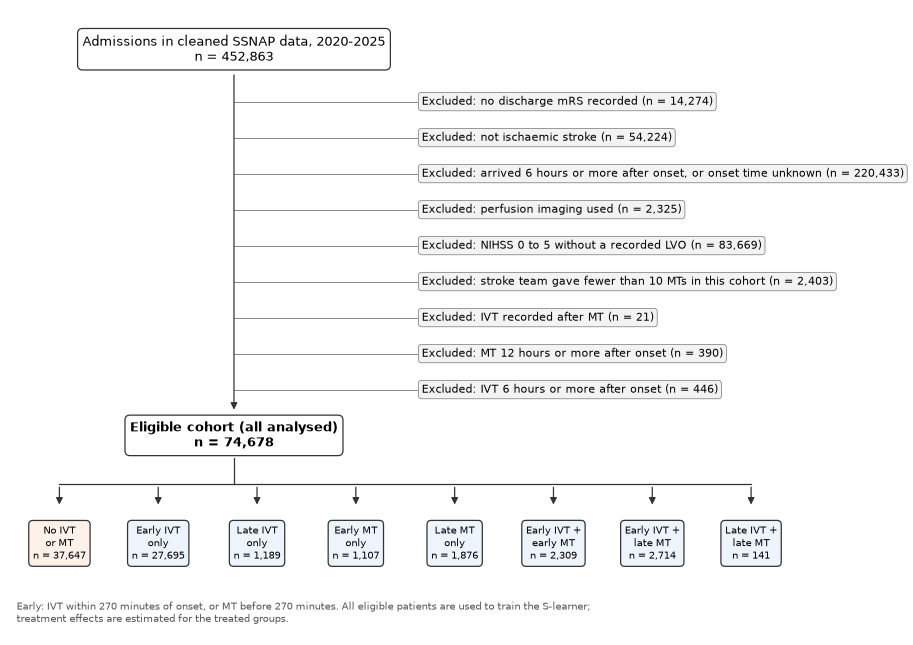

In [7]:
# Patient flow diagram: cohort selection and treatment groups
flow_steps = cohort_flow_steps(pd.read_csv(DATA_PATH, low_memory=False))
assert flow_steps[-1][0] == len(data), "Flow counts do not match the cohort in data"

group_counts = data["treatment_group"].value_counts()
flow_groups = [(group, [f"n = {group_counts[group]:,}"]) for group in TREATMENT_GROUP_ORDER]

plot_flow_diagram(
    flow_steps, "Eligible cohort (all analysed)", flow_groups, output_path("flow_diagram.png"),
    footnote=("Early: IVT within 270 minutes of onset, or MT before 270 minutes. All eligible patients are used to train the S-learner;\n"
              "treatment effects are estimated for the treated groups."))
pd.DataFrame(flow_steps, columns=["n_remaining", "excluded_reason", "n_excluded"]).to_csv(
    output_path("flow_counts.csv"), index=False)

**Results.** Most exclusions are for arrival 6 hours or more after onset (or unknown onset time) and for NIHSS 0–5 without a recorded LVO. All 74,678 eligible patients are used to fit the S-learner; half received neither treatment, and the late-treatment groups are small.

## Descriptive statistics by treatment group

Treatment times are summarised for treated patients only (sentinel values are set to missing for this table, so that means and percentiles are not distorted by the 99,999 code).

In [8]:
descriptive_data = data[ADJUSTMENT_FEATURES + TIME_FEATURES + ["treatment_group"]].copy()
descriptive_data[TIME_FEATURES] = descriptive_data[TIME_FEATURES].replace(NO_TREATMENT, np.nan)

descriptive_stats = (
    descriptive_data.groupby("treatment_group", observed=False)[ADJUSTMENT_FEATURES + TIME_FEATURES]
    .describe()
    .T
    .reindex(columns=TREATMENT_GROUP_ORDER)
    .round(2)
    .rename_axis(["feature", "statistic"])
    .reset_index()
)
descriptive_stats.to_csv(output_path("descriptive_stats.csv"), index=False)
descriptive_stats

treatment_group,feature,statistic,neither,early_thrombolysis_only,late_thrombolysis_only,early_thrombectomy_only,late_thrombectomy_only,early_both,early_thrombolysis_late_thrombectomy,late_both
0,prior_disability,count,37647.00,27695.00,1189.00,1107.00,1876.00,2309.00,2714.00,141.00
1,prior_disability,mean,1.87,1.00,0.97,0.75,0.63,0.43,0.41,0.45
2,prior_disability,std,1.60,1.31,1.29,0.89,0.85,0.74,0.73,0.70
3,prior_disability,min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,prior_disability,25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...
75,onset_to_thrombectomy_time,min,NaN,NaN,NaN,0.00,270.00,81.00,270.00,320.00
76,onset_to_thrombectomy_time,25%,NaN,NaN,NaN,180.00,320.00,182.00,301.00,375.00
77,onset_to_thrombectomy_time,50%,NaN,NaN,NaN,211.00,375.00,215.00,336.00,420.00
78,onset_to_thrombectomy_time,75%,NaN,NaN,NaN,240.00,455.00,243.00,390.00,483.00


**Results.** Untreated patients are older (mean age 78.5 years vs 69.5 to 74.2 in the treated groups) and have more pre-stroke disability (mean mRS 1.87 vs 0.41 to 1.00). Patients given thrombectomy have more severe strokes (mean NIHSS 15.1 to 17.9) than untreated patients and those given thrombolysis alone (12.0 to 12.8). These differences are the confounding the S-learner must adjust for.

### Descriptive statistics, ethnicity and missing data (LaTeX table rows)

Descriptive statistics by treatment group, extended with onset-to-scan time, year of admission, ethnicity and the number of patients with missing data for each model feature, printed as LaTeX rows for the paper's supplementary table (TARGET items 9 and 11).

In [9]:
# Descriptive statistics by treatment group for Supplementary Table S2, extended with onset-to-scan
# time, year of admission, ethnicity and a summary of missing data, and printed as LaTeX rows.
# Treatment times are summarised for treated patients only; untreated patients have no time
# (count 0, other statistics NA).

TABLE_S2_FEATURES = {
    "prior_disability": "Prior disability",
    "stroke_severity": "Stroke severity",
    "age": "Age",
    "congestive_heart_failure": "Congestive heart failure",
    "hypertension": "Hypertension",
    "diabetes": "Diabetes",
    "afib_anticoagulant": "AFib anticoagulant",
    "any_afib_diagnosis": "AFib diagnosis",
    "onset_to_scan_time": "Onset to scan",
    "year": "Year of admission",
    TIME_THROMBOLYSIS: "Onset to thrombolysis",
    TIME_THROMBECTOMY: "Onset to thrombectomy",
}
TABLE_S2_STATS = ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]

table_s2_data = data.copy()
table_s2_data["onset_to_scan_time"] = (
    table_s2_data["onset_to_arrival_time"] + table_s2_data["arrival_to_scan_time"]
)
table_s2_data[TIME_FEATURES] = table_s2_data[TIME_FEATURES].replace(NO_TREATMENT, np.nan)
table_s2_groups = table_s2_data.groupby("treatment_group", observed=False)

table_s2 = (
    table_s2_groups[list(TABLE_S2_FEATURES)]
    .describe()
    .T
    .reindex(columns=TREATMENT_GROUP_ORDER)
    .rename_axis(["feature", "statistic"])
)
table_s2.round(2).reset_index().to_csv(output_path("descriptive_stats_table_s2.csv"), index=False)


def latex_cell(value, statistic):
    """Format one statistic: counts as integers with thousands separators, NA when absent."""
    if pd.isna(value):
        return "NA"
    if statistic == "count":
        return f"{int(value):,}"
    return f"{value:.2f}"


print("% ---- Table S2 body: numeric features ----")
for feature, label in TABLE_S2_FEATURES.items():
    for k, statistic in enumerate(TABLE_S2_STATS):
        values = table_s2.loc[(feature, statistic)]
        if statistic != "count":
            # no statistics when no patient in the group has a value
            counts = table_s2.loc[(feature, "count")]
            values = values.where(counts > 0)
        cells = " & ".join(latex_cell(values[g], statistic) for g in TREATMENT_GROUP_ORDER)
        print(f"{label if k == 0 else ''} & {statistic.replace('%', chr(92) + '%')} & {cells} \\\\")
    print("\\addlinespace")

# Ethnicity: number (%) of patients in each category, by treatment group (counts below 10 suppressed)
ethnicity_raw = table_s2_data["ethnicity"].astype(object)
ethnicity = (ethnicity_raw.where(ethnicity_raw.notna(), "Missing").astype(str)
             .replace({"nan": "Missing", "": "Missing"}))
ethnicity_counts = pd.crosstab(ethnicity, table_s2_data["treatment_group"]).reindex(
    columns=TREATMENT_GROUP_ORDER, fill_value=0)
group_sizes = table_s2_data["treatment_group"].value_counts().reindex(TREATMENT_GROUP_ORDER)
print("% ---- Ethnicity: n (%) ----")
for category, row in ethnicity_counts.iterrows():
    cells = " & ".join(
        "$<$10" if row[g] < 10 else f"{row[g]:,} ({100 * row[g] / group_sizes[g]:.1f}\\%)"
        for g in TREATMENT_GROUP_ORDER)
    print(f"{category} & {cells} \\\\")

# Missing data: number of patients with a missing value for each model feature, by treatment group
MISSING_FEATURES = {**{f: TABLE_S2_FEATURES[f] for f in ADJUSTMENT_FEATURES},
                    "onset_to_scan_time": "Onset to scan", "year": "Year of admission",
                    "stroke_team": "Stroke team", "ethnicity": "Ethnicity"}
raw_missing = table_s2_data[list(MISSING_FEATURES)].copy()
for col in ["stroke_team", "ethnicity"]:
    as_text = raw_missing[col].astype(object)
    raw_missing[col] = as_text.where(as_text.notna() & ~as_text.astype(str).isin(["nan", ""]), np.nan)
missing_counts = (raw_missing.isna().groupby(table_s2_data["treatment_group"], observed=False).sum()
                  .T.reindex(columns=TREATMENT_GROUP_ORDER))
print("% ---- Missing data: number of patients with a missing value ----")
for feature, row in missing_counts.iterrows():
    cells = " & ".join(f"{int(row[g]):,}" for g in TREATMENT_GROUP_ORDER)
    print(f"{MISSING_FEATURES[feature]} & {cells} \\\\")
print(f"% total patients: {len(table_s2_data):,}")


% ---- Table S2 body: numeric features ----
Prior disability & count & 37,647 & 27,695 & 1,189 & 1,107 & 1,876 & 2,309 & 2,714 & 141 \\
 & mean & 1.87 & 1.00 & 0.97 & 0.75 & 0.63 & 0.43 & 0.41 & 0.45 \\
 & std & 1.60 & 1.31 & 1.29 & 0.89 & 0.85 & 0.74 & 0.73 & 0.70 \\
 & min & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
 & 25\% & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
 & 50\% & 2.00 & 0.00 & 0.00 & 1.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
 & 75\% & 3.00 & 2.00 & 2.00 & 1.00 & 1.00 & 1.00 & 1.00 & 1.00 \\
 & max & 5.00 & 5.00 & 5.00 & 5.00 & 5.00 & 5.00 & 5.00 & 3.00 \\
\addlinespace
Stroke severity & count & 37,602 & 27,675 & 1,189 & 1,107 & 1,876 & 2,307 & 2,714 & 141 \\
 & mean & 12.81 & 12.62 & 11.95 & 17.93 & 16.04 & 17.30 & 16.22 & 15.06 \\
 & std & 6.75 & 6.16 & 5.96 & 6.02 & 6.15 & 5.92 & 6.11 & 6.03 \\
 & min & 0.00 & 0.00 & 0.00 & 1.00 & 1.00 & 0.00 & 1.00 & 3.00 \\
 & 25\% & 7.00 & 7.00 & 7.00 & 14.00 & 11.00 & 13.00 & 11.25 & 10.00 \\
 & 50\% & 11.0

**Results.** NIHSS is the only model feature with missing values: 67 patients (45 untreated, 20 early thrombolysis only, 2 early both). Ethnicity not known is its own category (Other/NK, 9.7% to 15.3% by group). XGBoost handles the missing NIHSS values natively, so all 74,678 patients are used.

## Shared modelling functions

* `good_outcome`: binary outcome (discharge mRS ≤ target, optionally also counting discharge mRS no worse than pre-stroke mRS as good).
* `split_folds`: stratified k-fold split (stratified on outcome). Every patient appears in exactly one test fold.
* `xgb_factory`: returns a function that builds an XGBoost classifier for a training fold, with optional class weighting.
* `train_and_evaluate`: fits one model per fold and reports out-of-fold AUC, balanced accuracy, observed and predicted positive rate, and mean predicted probability (a calibration-in-the-large check).
* `to_log_odds`: converts probabilities to log-odds after clipping to avoid infinite values.
* `tune_xgb`: Optuna (TPE sampler) search over XGBoost hyperparameters, scored by cross-validated log loss, with unpromising trials pruned early.

In [10]:
def good_outcome(df, mrs_target=MRS_TARGET, include_no_worse=True):
    """1 if discharge mRS <= target (or, optionally, no worse than pre-stroke mRS), else 0."""
    outcome = df["discharge_disability"] <= mrs_target
    if include_no_worse:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


def split_folds(X, y, n_splits=N_SPLITS, random_state=RANDOM_STATE):
    """Return a list of (train_X, test_X, train_y, test_y) for stratified k-fold splits."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return [
        (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx])
        for train_idx, test_idx in skf.split(X, y)
    ]


def xgb_factory(pos_weight_factor=None, **xgb_params):
    """
    Return a function that builds an XGBoost classifier for a training fold.

    If pos_weight_factor is given, scale_pos_weight = (negatives / positives) x factor;
    otherwise no class weighting is used.
    """
    def make_model(train_y):
        weight = 1.0
        if pos_weight_factor is not None:
            positives = train_y.sum()
            weight = (len(train_y) - positives) / positives * pos_weight_factor
        return XGBClassifier(
            enable_categorical=True,
            verbosity=0,
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            scale_pos_weight=weight,
            **xgb_params,
        )
    return make_model


def train_and_evaluate(folds, model_factory):
    """Fit one model per fold; return the models and a table of out-of-fold performance."""
    models, results = [], []
    for split, (train_X, test_X, train_y, test_y) in enumerate(folds, start=1):
        model = model_factory(train_y)
        model.fit(train_X, train_y)
        probabilities = model.predict_proba(test_X)[:, 1]
        predictions = model.predict(test_X)
        models.append(model)
        results.append({
            "split": split,
            "AUC": roc_auc_score(test_y, probabilities),
            "balanced_accuracy": balanced_accuracy_score(test_y, predictions),
            "actual_positive_rate": test_y.mean(),
            "predicted_positive_rate": predictions.mean(),
            "mean_predicted_probability": probabilities.mean(),
        })
    return models, pd.DataFrame(results).set_index("split").round(4)


def to_log_odds(probabilities, eps=1e-9):
    """Convert probabilities to log-odds, clipping to avoid infinite values."""
    p = np.clip(probabilities, eps, 1 - eps)
    return np.log(p / (1 - p))


# Hyperparameter search space for Optuna. Ranges are continuous (or integer) rather than a fixed
# grid; learning rate, minimum child weight and the regularisation terms are searched on a log scale.
def suggest_xgb_params(trial):
    """Sample one set of XGBoost hyperparameters for an Optuna trial."""
    return {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 5, log=True),
    }

def tune_xgb(X, y, n_trials=N_TUNING_TRIALS, cv_folds=TUNING_CV, timeout=TUNING_TIMEOUT,
             random_state=RANDOM_STATE):
    """
    Optuna search over XGBoost hyperparameters, scored by cross-validated log loss (no class weighting).

    A seeded TPE (tree-structured Parzen estimator) sampler proposes each trial's settings from the
    results of earlier trials. Every trial is scored on the same stratified folds, so trials are
    compared on identical data splits. After each fold the running mean log loss is reported, and
    trials worse than the median of earlier trials at the same fold are pruned (stopped early).

    Returns the best parameters and a table of completed trials, best first, with default XGBoost
    settings added as a reference row. The Optuna study is kept in table.attrs["study"] for
    diagnostics, e.g. optuna.visualization.plot_optimization_history(table.attrs["study"]).
    """
    splits = list(StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state).split(X, y))
    base_settings = dict(enable_categorical=True, verbosity=0, random_state=random_state, eval_metric="logloss")

    def cv_scores(params, trial=None):
        """Mean log loss and AUC over the tuning folds; reports progress to the trial for pruning."""
        losses, aucs = [], []
        for step, (train_idx, test_idx) in enumerate(splits):
            model = XGBClassifier(**base_settings, **params)
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            probabilities = model.predict_proba(X.iloc[test_idx])[:, 1]
            losses.append(log_loss(y.iloc[test_idx], probabilities))
            aucs.append(roc_auc_score(y.iloc[test_idx], probabilities))
            if trial is not None:
                trial.report(np.mean(losses), step)
                if trial.should_prune():
                    raise optuna.TrialPruned()
        return np.mean(losses), np.mean(aucs)

    def objective(trial):
        loss, auc = cv_scores(suggest_xgb_params(trial), trial)
        trial.set_user_attr("AUC", auc)
        return loss

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=random_state, multivariate=True, n_startup_trials=10),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=0),
    )
    study.optimize(objective, n_trials=n_trials, timeout=timeout)

    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"Optuna: {len(completed)} trials completed, {n_pruned} pruned")

    table = pd.DataFrame([t.params for t in completed], index=[t.number for t in completed])
    table.index.name = "trial"
    table["log loss"] = [t.value for t in completed]
    table["AUC"] = [t.user_attrs["AUC"] for t in completed]

    default_loss, default_auc = cv_scores({})
    table.loc["default settings"] = pd.Series({"log loss": default_loss, "AUC": default_auc})

    table = table.sort_values("log loss").round(4)
    table.attrs["study"] = study
    return study.best_params, table

# 2. Part A: S-learner with treatment times as continuous features

## Method

* **Outcome:** good outcome (binary).
* **Features:** adjustment features plus onset-to-thrombolysis and onset-to-thrombectomy times.
* **Cross-validation:** data split into 5 stratified folds. For each fold an XGBoost classifier is trained on the other four folds (80% of patients) and used to predict the held-out fold (20%). Every patient therefore receives predictions from a model that did not see them during training.
* **Hyperparameters:** chosen by an Optuna search (`N_TUNING_TRIALS` trials) over tree depth, learning rate, number of trees, minimum child weight, row and column subsampling, L1 and L2 regularisation, and minimum split loss (gamma). Ranges are continuous rather than a fixed grid. Optuna's tree-structured Parzen estimator (TPE) sampler uses the scores of earlier trials to propose new settings in promising regions; it is seeded for reproducibility. All trials are scored on the same folds, and a trial whose running log loss after a fold is worse than the median of earlier trials is stopped early (median pruning). Each trial is scored by 3-fold stratified cross-validated **log loss**, which rewards both discrimination and calibration. Calibration matters here because treatment effects are differences between predicted probabilities. No class weighting is used, so predicted probabilities are on the scale of the observed outcome rate.
* **Note on tuning:** the search uses all patients, so the chosen settings have seen every patient once during tuning. With about 75,000 patients and a few hyperparameters the resulting optimism is small. Fully nested tuning (re-tuning inside each training fold) would remove it, at about 5 times the run time.

## Hyperparameter tuning

Completed Optuna trials ranked by cross-validated log loss (lower is better); the top 10 are shown. The full table (`tuning_times`) also has a *default settings* row for reference.

In [11]:
y = good_outcome(data)
best_params_times, tuning_times = tune_xgb(data[X_FIELDS_TIMES], y)
print("Selected hyperparameters:", best_params_times)
tuning_times.head(10)

Optuna: 40 trials completed, 20 pruned
Selected hyperparameters: {'max_depth': 4, 'learning_rate': 0.027798635265642444, 'n_estimators': 850, 'min_child_weight': 19.803327452416084, 'subsample': 0.980871514621511, 'colsample_bytree': 0.5922883259237922, 'reg_lambda': 7.589916255155783, 'reg_alpha': 8.282497744836723, 'gamma': 0.014393945594555216}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,log loss,AUC
trial,,,,,,,,,,,
48,4.0,0.0278,850.0,19.8033,0.9809,0.5923,7.5899,8.2825,0.0144,0.5689,0.7644
41,4.0,0.0217,950.0,20.2842,0.9712,0.5712,4.7027,3.1751,0.0297,0.5691,0.7642
45,4.0,0.0338,950.0,19.2138,0.9085,0.6105,3.5324,6.4806,0.0246,0.5691,0.7642
36,4.0,0.0224,950.0,17.7302,0.9569,0.5178,3.2691,1.8992,0.0148,0.5691,0.7641
50,4.0,0.0205,950.0,27.9571,0.9120,0.5678,3.3970,3.6041,0.0077,0.5692,0.7640
52,4.0,0.0257,900.0,22.9025,0.9642,0.5486,2.2596,1.7117,0.0224,0.5692,0.7641
54,4.0,0.0197,950.0,11.9603,0.9726,0.5074,1.0102,1.1702,0.0164,0.5692,0.7641
55,4.0,0.0196,800.0,22.5098,0.9025,0.6022,1.5218,2.7646,0.0105,0.5692,0.7640
20,4.0,0.0150,950.0,7.2913,0.9136,0.5765,9.4471,1.4666,0.0063,0.5692,0.7641


**Results.** 40 trials completed and 20 were pruned. The best trial (depth 4, 850 trees, learning rate 0.028, minimum child weight 20, row subsampling 0.98, column subsampling 0.59, L2 regularisation 7.6, L1 regularisation 8.3) has cross-validated log loss 0.5689 and AUC 0.764. The top 10 trials differ by at most 0.0003 in log loss, so performance is flat near the optimum and the exact choice of settings matters little.

## Train and evaluate the S-learner (tuned settings)

Five models, one per fold, with out-of-fold performance for each fold.

In [12]:
folds_times = split_folds(data[X_FIELDS_TIMES], y)
models_times, performance_times = train_and_evaluate(folds_times, xgb_factory(**best_params_times))
performance_times

,AUC,balanced_accuracy,actual_positive_rate,predicted_positive_rate,mean_predicted_probability
split,,,,,
1,0.7662,0.6883,0.4222,0.3817,0.4244
2,0.7635,0.6860,0.4222,0.3781,0.4194
3,0.7669,0.6867,0.4222,0.3836,0.4230
4,0.7656,0.6868,0.4222,0.3786,0.4204
5,0.7623,0.6880,0.4222,0.3860,0.4234


**Results.** Out-of-fold AUC is 0.762 to 0.767 across folds.

* **Calibration:** the mean predicted probability (0.419 to 0.424) matches the observed rate (0.422).
* **Predicted positive rate:** at a 0.5 threshold the predicted positive rate (0.38) is below the observed rate. This is expected for a calibrated model with an outcome rate below 0.5, and does not matter here, because effects are calculated from probabilities.

## Counterfactual predictions

For every treated patient in each held-out fold, the fold's model makes four predictions:

| Scenario | Thrombolysis time | Thrombectomy time |
|---|---|---|
| treated (actual) | actual | actual |
| no thrombolysis | sentinel | actual |
| no thrombectomy | actual | sentinel |
| no treatment | sentinel | sentinel |

The individual treatment effect estimate is the prediction under actual treatment minus the prediction with no treatment, on the probability scale (`treatment_diff_prob`) and on the log-odds scale (`log_odds_diff_treated_no_treatment`).

The mean of individual log-odds differences in a group is reported as that group's log odds ratio. This is an average of individual (conditional) log odds ratios, not a marginal (population) odds ratio.

In [13]:
COUNTERFACTUAL_SCENARIOS = {
    "treated": {},
    "no_thrombolysis": {TIME_THROMBOLYSIS: NO_TREATMENT},
    "no_thrombectomy": {TIME_THROMBECTOMY: NO_TREATMENT},
    "no_treatment": {TIME_THROMBOLYSIS: NO_TREATMENT, TIME_THROMBECTOMY: NO_TREATMENT},
}


def label_treatment_received(df):
    """Label treatment modality received (ignoring timing)."""
    ivt = df[TIME_THROMBOLYSIS] != NO_TREATMENT
    evt = df[TIME_THROMBECTOMY] != NO_TREATMENT
    return np.select(
        [ivt & evt, ivt, evt], ["both", "thrombolysis_only", "thrombectomy_only"], default="neither"
    )


counterfactual_frames = []
for model, (_, test_X, _, test_y) in zip(models_times, folds_times):
    treated = (test_X[TIME_THROMBOLYSIS] < NO_TREATMENT) | (test_X[TIME_THROMBECTOMY] < NO_TREATMENT)
    treated_X = test_X[treated]

    fold_cf = treated_X.copy()
    fold_cf.insert(0, "patient_index", treated_X.index)
    fold_cf["actual_y"] = test_y[treated]
    for scenario, overrides in COUNTERFACTUAL_SCENARIOS.items():
        fold_cf[f"y_prob_{scenario}"] = model.predict_proba(treated_X.assign(**overrides))[:, 1]
    counterfactual_frames.append(fold_cf)

cf_times = pd.concat(counterfactual_frames, ignore_index=True)
cf_times["treatment_diff_prob"] = cf_times["y_prob_treated"] - cf_times["y_prob_no_treatment"]
cf_times["treatment_group"] = label_treatment_received(cf_times)

for scenario in COUNTERFACTUAL_SCENARIOS:
    cf_times[f"log_odds_{scenario}"] = to_log_odds(cf_times[f"y_prob_{scenario}"])
for scenario in ["no_thrombolysis", "no_thrombectomy", "no_treatment"]:
    cf_times[f"log_odds_diff_treated_{scenario}"] = (
        cf_times["log_odds_treated"] - cf_times[f"log_odds_{scenario}"]
    )

## Descriptive statistics of counterfactual predictions

All treated patients, then by treatment received.

In [14]:
cf_times.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_index,37031.0,226152.399827,130720.057348,2.000000,112807.000000,225941.000000,339514.000000,452853.000000
prior_disability,37031.0,0.894899,1.231736,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,37009.0,13.496717,6.369932,0.000000,8.000000,12.000000,18.000000,42.000000
age,37031.0,73.451500,13.400093,37.500000,62.500000,77.500000,82.500000,92.500000
congestive_heart_failure,37031.0,0.055305,0.228578,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,37031.0,0.538441,0.498527,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,37031.0,0.202776,0.402072,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,37031.0,0.066566,0.249272,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,37031.0,0.239934,0.427049,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,37031.0,8208.920688,27169.603101,14.000000,127.000000,166.000000,222.000000,99999.000000


In [15]:
for group in ["thrombectomy_only", "thrombolysis_only", "both"]:
    print(f"Treatment group: {group}")
    display(cf_times[cf_times["treatment_group"] == group].describe().T)

Treatment group: thrombectomy_only


,count,mean,std,min,25%,50%,75%,max
patient_index,2983.0,228803.374790,130134.169310,581.000000,117208.500000,227453.000000,341059.500000,452793.000000
prior_disability,2983.0,0.672813,0.867605,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,2983.0,16.740530,6.170970,1.000000,12.000000,17.000000,21.000000,40.000000
age,2983.0,72.379316,13.302780,37.500000,62.500000,77.500000,82.500000,92.500000
congestive_heart_failure,2983.0,0.088166,0.283584,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,2983.0,0.528998,0.499242,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,2983.0,0.176333,0.381167,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,2983.0,0.445189,0.497070,0.000000,0.000000,0.000000,1.000000,1.000000
any_afib_diagnosis,2983.0,0.507543,0.500027,0.000000,0.000000,1.000000,1.000000,1.000000
onset_to_thrombolysis_time,2983.0,99999.000000,0.000000,99999.000000,99999.000000,99999.000000,99999.000000,99999.000000


Treatment group: thrombolysis_only


,count,mean,std,min,25%,50%,75%,max
patient_index,28884.0,225787.430481,130684.595226,2.000000,112495.500000,225230.000000,338904.500000,452853.000000
prior_disability,28884.0,1.003151,1.309003,0.000000,0.000000,0.000000,2.000000,5.000000
stroke_severity,28864.0,12.594096,6.151869,0.000000,7.000000,11.000000,17.000000,42.000000
age,28884.0,74.186055,13.316228,37.500000,67.500000,77.500000,82.500000,92.500000
congestive_heart_failure,28884.0,0.054390,0.226790,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,28884.0,0.548574,0.497644,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,28884.0,0.214305,0.410347,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,28884.0,0.034033,0.181316,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,28884.0,0.212955,0.409403,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,28884.0,169.738679,56.371949,14.000000,126.000000,163.000000,209.000000,359.000000


Treatment group: both


,count,mean,std,min,25%,50%,75%,max
patient_index,5164.0,226662.453331,131260.870967,33.000000,113101.000000,229067.000000,343534.000000,452674.000000
prior_disability,5164.0,0.417699,0.734320,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,5162.0,16.669314,6.049664,0.000000,12.000000,17.000000,21.000000,42.000000
age,5164.0,69.962239,13.334430,37.500000,62.500000,72.500000,82.500000,92.500000
congestive_heart_failure,5164.0,0.041441,0.199327,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,5164.0,0.487219,0.499885,0.000000,0.000000,0.000000,1.000000,1.000000
diabetes,5164.0,0.153563,0.360564,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,5164.0,0.029822,0.170112,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,5164.0,0.236251,0.424819,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,5164.0,151.973857,54.412627,22.000000,112.000000,141.000000,184.000000,359.000000


Mean, standard deviation and n of predicted outcomes and treatment effects by treatment received.

In [16]:
EFFECT_COLS = [
    "y_prob_treated",
    "y_prob_no_treatment",
    "treatment_diff_prob",
    "log_odds_diff_treated_no_treatment",
]

summary_stats = (
    cf_times.melt(id_vars="treatment_group", value_vars=EFFECT_COLS, var_name="treatment_effect")
    .groupby(["treatment_group", "treatment_effect"], sort=False)["value"]
    .agg(mean="mean", std="std", n="count")
    .round(3)
)
summary_stats

,,mean,std,n
treatment_group,treatment_effect,,,
thrombolysis_only,y_prob_treated,0.487,0.223,28884
both,y_prob_treated,0.422,0.204,5164
thrombectomy_only,y_prob_treated,0.344,0.189,2983
thrombolysis_only,y_prob_no_treatment,0.367,0.209,28884
both,y_prob_no_treatment,0.258,0.180,5164
thrombectomy_only,y_prob_no_treatment,0.243,0.176,2983
thrombolysis_only,treatment_diff_prob,0.120,0.057,28884
both,treatment_diff_prob,0.164,0.087,5164
thrombectomy_only,treatment_diff_prob,0.101,0.073,2983


**Results.**

* Across all 37,031 treated patients, the mean predicted probability of a good outcome is 46.6% with treatment and 34.2% without, a mean effect of 12.5 percentage points (log odds 0.65). The observed rate in these patients (46.8%) matches the treated prediction.
* By treatment received:
  * thrombolysis only: 48.7% vs 36.7% (+12.0 points; log odds 0.62)
  * thrombectomy only: 34.4% vs 24.3% (+10.1 points; log odds 0.61)
  * both: 42.2% vs 25.8% (+16.4 points; log odds 0.89)
* Across all treated patients, removing thrombolysis lowers the predicted log odds by 0.51 on average and removing thrombectomy by 0.06, because most treated patients had thrombolysis only.

**Discussion.** Patients given thrombectomy have lower predicted outcomes with and without treatment, reflecting their more severe strokes; the counterfactual comparison is within the same patients, so this does not bias the effect estimate if the model captures the confounding.

## Heatmaps of predicted benefit by treatment time

Treatment times are grouped into 60-minute bins (thrombolysis up to 6 hours, thrombectomy up to 12 hours); untreated is a separate bin (last row / column, separated by a solid line). Each cell shows the mean individual benefit, its 95% confidence interval (where shown) and n. Cells with fewer than 10 patients are blanked. Three heatmaps are drawn: log odds ratio, odds ratio and probability difference (percentage points).

The confidence interval is mean ± 1.96 × SD / √n. It reflects variation between patients' predicted benefits only, not uncertainty in the fitted model, so it understates total uncertainty (see section 5).

In [17]:
MIN_CELL_COUNT = 10


def add_time_bins(df, width=60):
    """Add binned onset-to-treatment times; untreated patients get their own bin."""
    for time_col, bin_col, max_time, untreated_label in [
        (TIME_THROMBOLYSIS, "thrombolysis_bin", 360, "No thrombolysis"),
        (TIME_THROMBECTOMY, "thrombectomy_bin", 720, "No thrombectomy"),
    ]:
        edges = list(range(0, max_time + 1, width)) + [NO_TREATMENT]
        labels = [f"{lo}-{hi}" for lo, hi in zip(edges[:-2], edges[1:-1])] + [untreated_label]
        df[bin_col] = pd.cut(df[time_col], bins=edges, labels=labels, right=True, include_lowest=True)
    return df


def format_cells(frame, fmt):
    """Format a numeric DataFrame as strings, leaving missing cells blank."""
    return frame.apply(lambda col: col.map(lambda v: fmt.format(v) if pd.notna(v) else ""))


def plot_time_heatmap(df, value_col, title, cbar_label, filename,
                      scale=1.0, exponentiate=False, center=0, decimals=2, show_ci=False):
    """Heatmap of mean value_col by thrombectomy (rows) and thrombolysis (columns) time bins."""
    grouped = df.groupby(["thrombectomy_bin", "thrombolysis_bin"], observed=False)[value_col]
    counts = grouped.count().unstack()
    keep = counts >= MIN_CELL_COUNT
    means = grouped.mean().unstack().where(keep)
    values = np.exp(means) if exponentiate else means * scale

    annot = format_cells(values, f"{{:.{decimals}f}}")
    if show_ci:
        ci = 1.96 * grouped.std().unstack().where(keep) / np.sqrt(counts) * scale
        annot = annot + format_cells(ci, f" ±{{:.{decimals}f}}")
    annot = annot + format_cells(counts.where(keep), "\n(n={:.0f})")

    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(values.astype(float), cmap="bwr_r", center=center, annot=annot, fmt="", ax=ax,
                cbar_kws={"label": cbar_label})

    # Dashed lines between bins; solid line before the 'no treatment' bin
    n_rows, n_cols = values.shape
    for i in range(1, n_cols):
        ax.axvline(i, color="black", linestyle="--", linewidth=0.5)
    for i in range(1, n_rows):
        ax.axhline(i, color="black", linestyle="--", linewidth=0.5)
    ax.axvline(n_cols - 1, color="black", linewidth=1)
    ax.axhline(n_rows - 1, color="black", linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Thrombolysis time bin (onset to thrombolysis, mins)")
    ax.set_ylabel("Thrombectomy time bin (onset to thrombectomy, mins)")
    fig.savefig(output_path(f"{filename}.png"), dpi=300, bbox_inches="tight")
    plt.show()


cf_times = add_time_bins(cf_times)

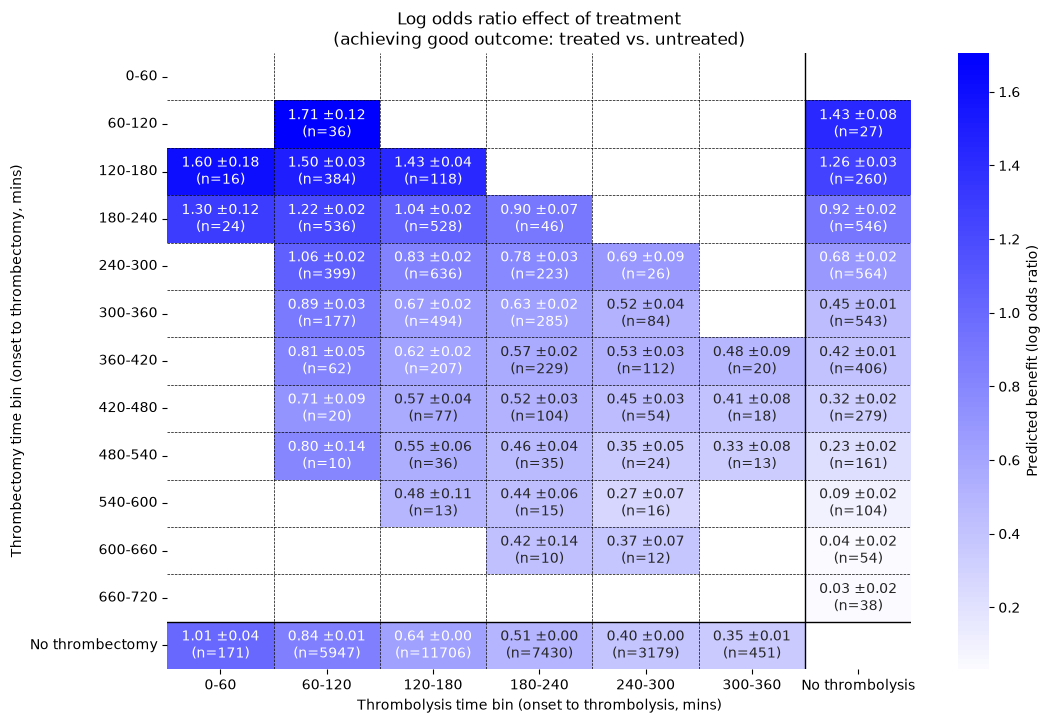

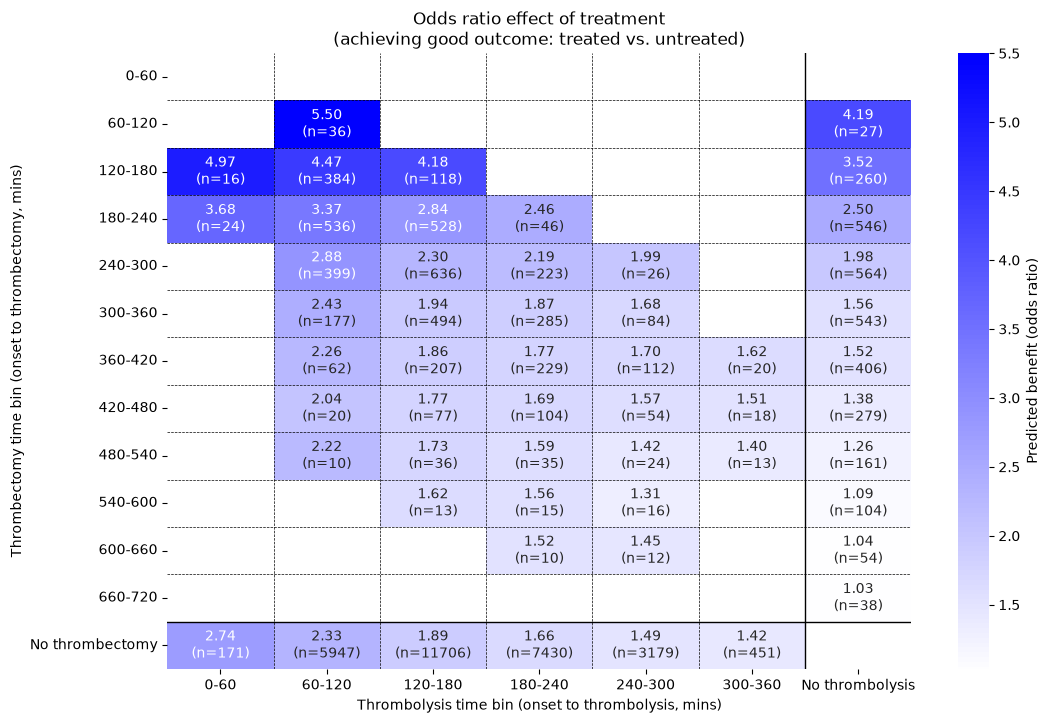

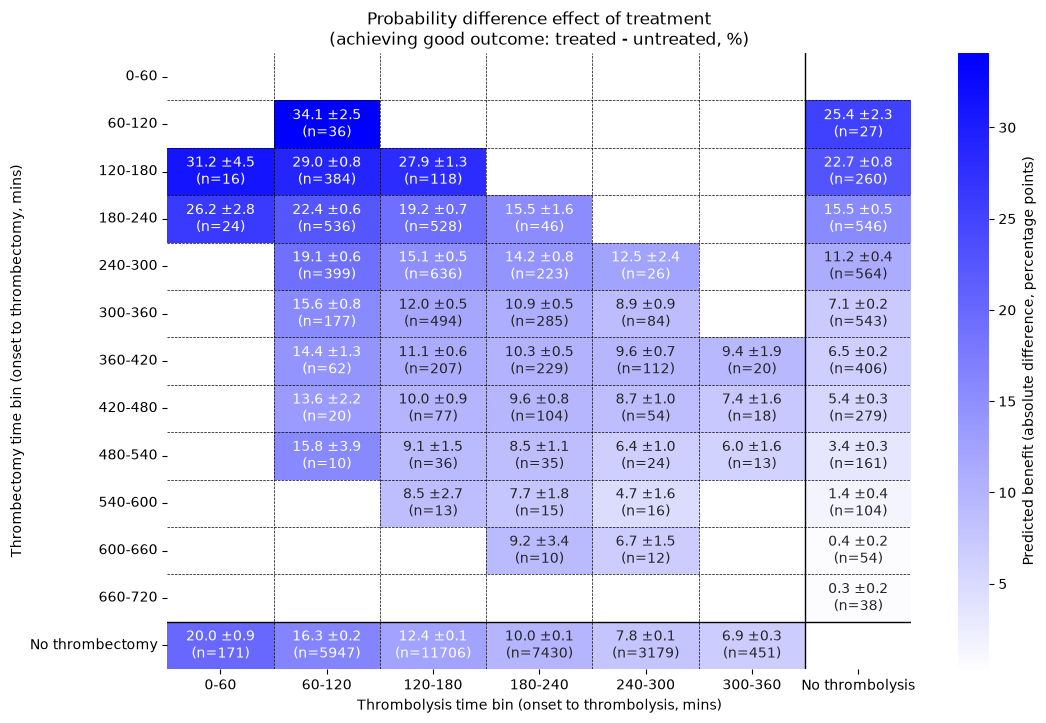

In [18]:
plot_time_heatmap(
    cf_times, "log_odds_diff_treated_no_treatment",
    title="Log odds ratio effect of treatment\n(achieving good outcome: treated vs. untreated)",
    cbar_label="Predicted benefit (log odds ratio)",
    filename="heatmap_log_odds", show_ci=True,
)

plot_time_heatmap(
    cf_times, "log_odds_diff_treated_no_treatment",
    title="Odds ratio effect of treatment\n(achieving good outcome: treated vs. untreated)",
    cbar_label="Predicted benefit (odds ratio)",
    filename="heatmap_odds", exponentiate=True, center=1,
)

plot_time_heatmap(
    cf_times, "treatment_diff_prob",
    title="Probability difference effect of treatment\n(achieving good outcome: treated - untreated, %)",
    cbar_label="Predicted benefit (absolute difference, percentage points)",
    filename="heatmap_diff_prob", scale=100, decimals=1, show_ci=True,
)

**Results.**

* **Thrombolysis alone** (bottom row): predicted benefit falls steadily with time, from +20.0 percentage points (log odds 1.01) at 0–60 minutes to +12.4 at 120–180 minutes and +6.9 (log odds 0.35) at 300–360 minutes.
* **Thrombectomy alone** (right-hand column): benefit falls from +25.4 points (log odds 1.43) at 60–120 minutes to +11.2 at 240–300 minutes, +3.4 at 480–540 minutes and almost nothing (+0.3) at 660–720 minutes.
* **Both treatments:** benefit is largest when both are early (for example +29.0 points with thrombolysis at 60–120 and thrombectomy at 120–180 minutes) and declines with delay to either treatment. At the same thrombectomy time, earlier thrombolysis adds benefit; at the same thrombolysis time, earlier thrombectomy adds benefit.

## Benefit by both treatment times (patients receiving both treatments)

An ordinary least squares (OLS) regression of individual predicted benefit (log odds ratio) on onset-to-thrombolysis and onset-to-thrombectomy time. This summarises how the fitted XGBoost model's estimated benefit changes with each time, holding the other constant.

Note: the "observations" are model predictions, not independent outcomes, so OLS standard errors and *p*-values are too small. Treat the coefficients as a description of the S-learner, not as independent tests.

In [19]:
both = cf_times[cf_times["treatment_group"] == "both"].copy()

ols_both_times = sm.OLS(
    both["log_odds_diff_treated_no_treatment"],
    sm.add_constant(both[[TIME_THROMBOLYSIS, TIME_THROMBECTOMY]]),
).fit()
print(ols_both_times.summary())

params = ols_both_times.params


def linear_benefit(ivt_time, evt_time):
    """Predicted log odds benefit from the two-time regression."""
    return params["const"] + params[TIME_THROMBOLYSIS] * ivt_time + params[TIME_THROMBECTOMY] * evt_time

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.575
Model:                                            OLS   Adj. R-squared:                  0.575
Method:                                 Least Squares   F-statistic:                     3496.
Date:                                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                                        14:40:07   Log-Likelihood:                -207.28
No. Observations:                                5164   AIC:                             420.6
Df Residuals:                                    5161   BIC:                             440.2
Df Model:                                           2                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

**Results.** In the 5,164 patients given both treatments, predicted benefit falls by 0.0022 log-odds units per minute of delay to thrombolysis and 0.0021 per minute of delay to thrombectomy (about 0.13 per hour for each), from 1.84 at time zero. The two times together explain 58% of the variation in predicted benefit.

### Contour plot

Predicted benefit across both times from the regression above. The grey area (thrombolysis after thrombectomy) is outside the data.

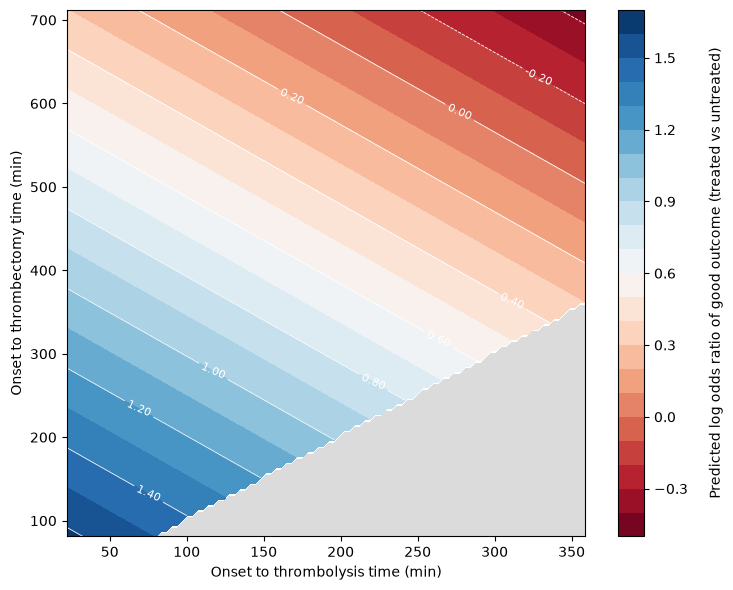

In [20]:
ivt_grid = np.linspace(both[TIME_THROMBOLYSIS].min(), both[TIME_THROMBOLYSIS].max(), 100)
evt_grid = np.linspace(both[TIME_THROMBECTOMY].min(), both[TIME_THROMBECTOMY].max(), 100)
ivt_mesh, evt_mesh = np.meshgrid(ivt_grid, evt_grid)

invalid = ivt_mesh > evt_mesh
benefit = np.ma.masked_where(invalid, linear_benefit(ivt_mesh, evt_mesh))

fig, ax = plt.subplots(figsize=(7.5, 6))
filled = ax.contourf(ivt_mesh, evt_mesh, benefit, levels=20, cmap="RdBu")
lines = ax.contour(ivt_mesh, evt_mesh, benefit, levels=10, colors="white", linewidths=0.6)
ax.clabel(lines, inline=True, fontsize=8, fmt="%.2f")
ax.contourf(ivt_mesh, evt_mesh, invalid, levels=[0.5, 1.5], colors="lightgrey", alpha=0.8)

fig.colorbar(filled, ax=ax).set_label(
    "Predicted log odds ratio of good outcome (treated vs untreated)", labelpad=15
)
ax.set_xlabel("Onset to thrombolysis time (min)")
ax.set_ylabel("Onset to thrombectomy time (min)")
fig.tight_layout()
fig.savefig(output_path("contour_plot.png"), dpi=300)
plt.show()

**Results.** The contours run diagonally: because the two slopes are almost equal, a given delay reduces predicted benefit by about the same amount whether it is to thrombolysis or to thrombectomy.

### Marginal effect plots

Left: benefit against thrombectomy time at fixed thrombolysis times. Right: benefit against thrombolysis time at fixed thrombectomy times. Lines are drawn only where thrombolysis is not after thrombectomy.

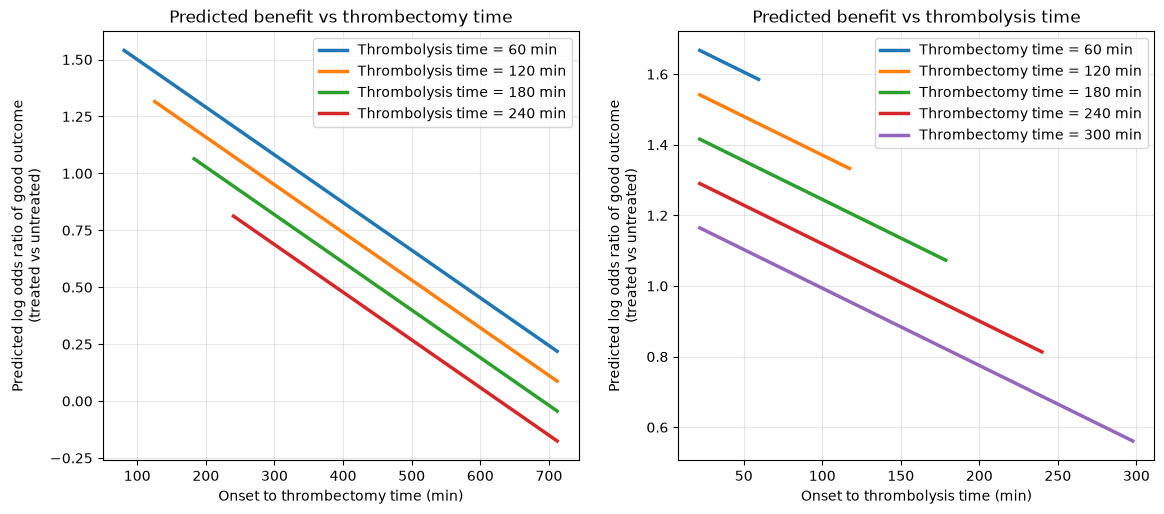

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
y_label = "Predicted log odds ratio of good outcome\n(treated vs untreated)"

evt_range = np.linspace(both[TIME_THROMBECTOMY].min(), both[TIME_THROMBECTOMY].max(), 100)
for ivt_time in [60, 120, 180, 240]:
    valid = evt_range >= ivt_time
    axes[0].plot(evt_range[valid], linear_benefit(ivt_time, evt_range[valid]),
                 linewidth=2.5, label=f"Thrombolysis time = {ivt_time} min")
axes[0].set_title("Predicted benefit vs thrombectomy time")
axes[0].set_xlabel("Onset to thrombectomy time (min)")

ivt_range = np.linspace(both[TIME_THROMBOLYSIS].min(), both[TIME_THROMBOLYSIS].max(), 100)
for evt_time in [60, 120, 180, 240, 300]:
    valid = ivt_range <= evt_time
    axes[1].plot(ivt_range[valid], linear_benefit(ivt_range[valid], evt_time),
                 linewidth=2.5, label=f"Thrombectomy time = {evt_time} min")
axes[1].set_title("Predicted benefit vs thrombolysis time")
axes[1].set_xlabel("Onset to thrombolysis time (min)")

for ax in axes:
    ax.set_ylabel(y_label)
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout(pad=2.0)
fig.savefig(output_path("marginal_effect_plot.png"), dpi=300)
plt.show()

**Results.** The lines are parallel and evenly spaced, showing the additive form of the regression: each hour of delay to either treatment lowers predicted benefit by a similar amount.

## Benefit by time to treatment, for each treatment received

For each group, a simple linear regression of individual predicted benefit (log odds ratio) on onset-to-treatment time gives:

* **Benefit at time zero** (the intercept), with 95% CI.
* **Time at which predicted benefit reaches zero**: x = −intercept / slope. Its 95% CI uses the delta method:
Var(x) = Var(a)/b² + a² Var(b)/b⁴ − 2a Cov(a, b)/b³, where a is the intercept and b the slope.
This is an extrapolation when the zero point lies beyond the observed times.

The same caveat on standard errors applies as above (predictions are not independent observations).

**SHAP plots** explain the outcome model (the first fold's model, probability of good outcome), not the treatment effect. They show which features drive predicted outcome for each group. About 20% of the patients shown were in that model's training data (they were test patients for other folds).

In [22]:
def analyse_time_to_treatment(df, time_col, treatment_label, subtitle, filename=None):
    """Regress predicted benefit on time to treatment; print key results and plot."""
    benefit_col = "log_odds_diff_treated_no_treatment"
    ols = sm.OLS(df[benefit_col], sm.add_constant(df[[time_col]])).fit()
    print(ols.summary())

    intercept, slope = ols.params["const"], ols.params[time_col]
    ci = ols.conf_int().loc["const"]
    print(f"\nPredicted benefit at time zero (intercept): {intercept:.4f}, "
          f"95% CI: [{ci.iloc[0]:.4f}, {ci.iloc[1]:.4f}]")

    if np.isclose(slope, 0):
        print("Slope is approximately zero, so the time of zero benefit cannot be estimated reliably.")
    else:
        cov = ols.cov_params()
        x_at_zero = -intercept / slope
        variance = (
            cov.loc["const", "const"] / slope**2
            + intercept**2 * cov.loc[time_col, time_col] / slope**4
            - 2 * intercept * cov.loc["const", time_col] / slope**3
        )
        half_width = 1.96 * np.sqrt(max(variance, 0))
        print(f"Time at which predicted benefit is zero: {x_at_zero:.0f} mins, "
              f"95% CI: [{x_at_zero - half_width:.0f}, {x_at_zero + half_width:.0f}] mins")

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.regplot(x=time_col, y=benefit_col, data=df, ci=95, ax=ax,
                scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(f"Effect of {treatment_label} time on predicted benefit (good outcome)\n({subtitle})")
    ax.set_xlabel(f"Onset to {treatment_label} time (mins)")
    ax.set_ylabel("Predicted benefit\n(log odds ratio of good outcome vs no treatment)")
    if filename:
        fig.savefig(output_path(f"{filename}.png"), dpi=300, bbox_inches="tight")
    plt.show()
    return ols


def plot_outcome_shap(df, title):
    """SHAP beeswarm for the Part A outcome model (fold 1) on the given patients."""
    shap_values = shap.Explainer(models_times[0])(df[X_FIELDS_TIMES])
    shap.plots.beeswarm(shap_values, max_display=99, show=False)
    plt.title(title)
    plt.show()

### Thrombectomy alone

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.684
Model:                                            OLS   Adj. R-squared:                  0.684
Method:                                 Least Squares   F-statistic:                     6445.
Date:                                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                                        14:40:08   Log-Likelihood:                 412.39
No. Observations:                                2983   AIC:                            -820.8
Df Residuals:                                    2981   BIC:                            -808.8
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

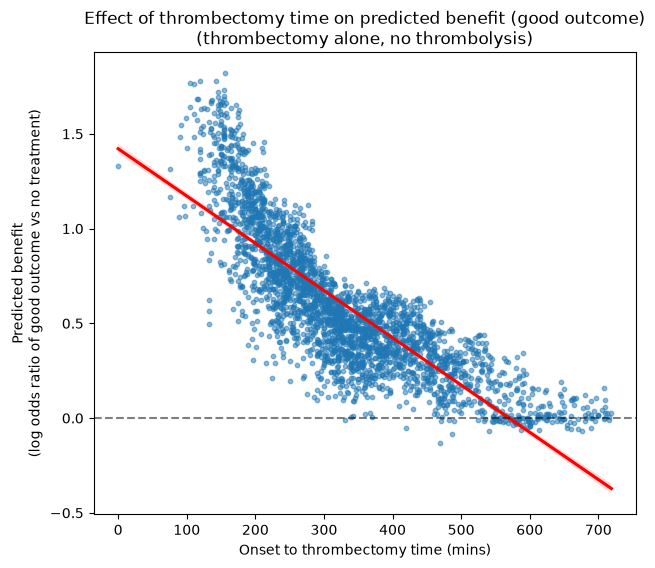

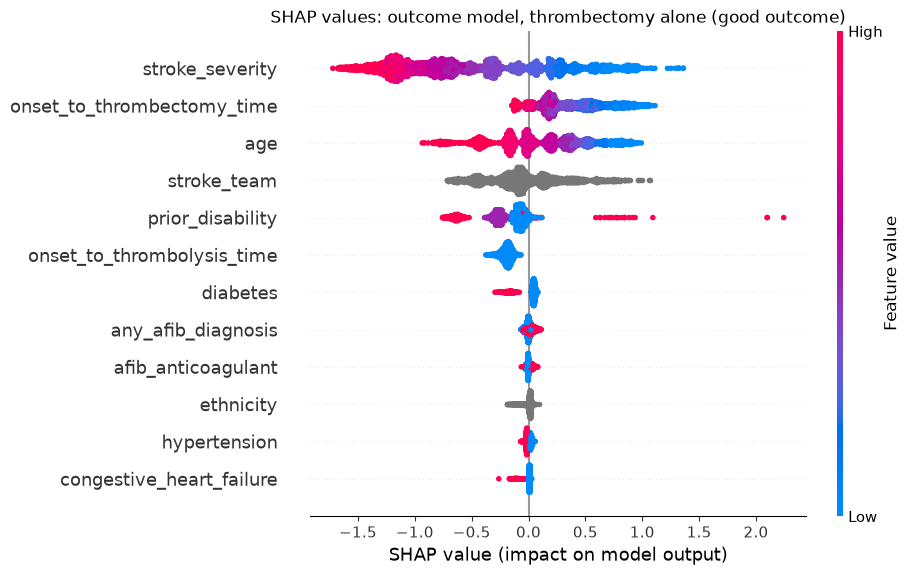

In [23]:
only_thrombectomy = cf_times[cf_times["treatment_group"] == "thrombectomy_only"].copy()
analyse_time_to_treatment(only_thrombectomy, TIME_THROMBECTOMY, "thrombectomy",
                          "thrombectomy alone, no thrombolysis", "time_effect_thrombectomy_alone")
plot_outcome_shap(only_thrombectomy, "SHAP values: outcome model, thrombectomy alone (good outcome)")

**Results.** For the 2,983 patients given thrombectomy alone, predicted benefit is 1.42 log-odds units at time zero (95% CI 1.40 to 1.44) and falls by 0.0025 per minute (0.15 per hour). It reaches zero at 570 minutes (563 to 577), within the 12-hour window. Time explains 68% of the variation in predicted benefit.

### Thrombolysis alone

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.364
Model:                                            OLS   Adj. R-squared:                  0.364
Method:                                 Least Squares   F-statistic:                 1.656e+04
Date:                                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                                        14:40:08   Log-Likelihood:                 6281.9
No. Observations:                               28884   AIC:                        -1.256e+04
Df Residuals:                                   28882   BIC:                        -1.254e+04
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

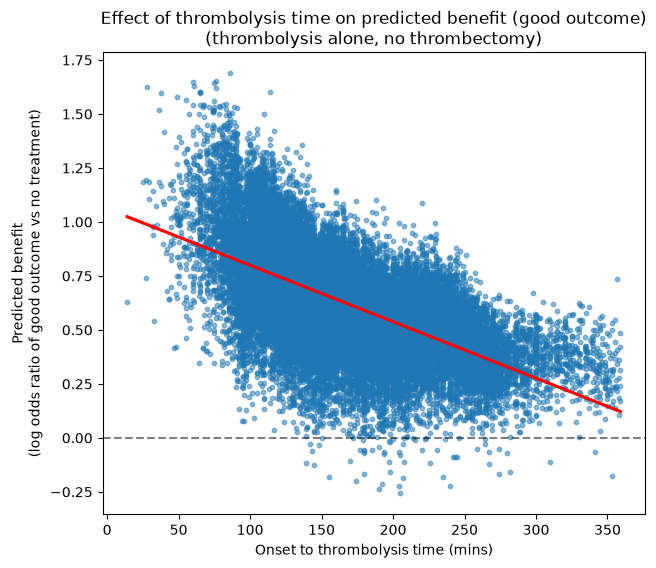

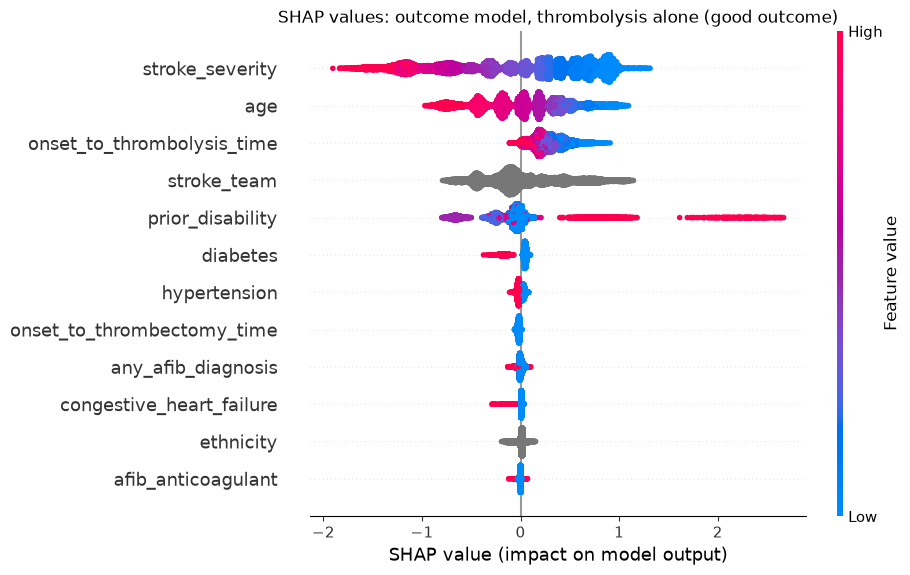

In [24]:
only_thrombolysis = cf_times[cf_times["treatment_group"] == "thrombolysis_only"].copy()
analyse_time_to_treatment(only_thrombolysis, TIME_THROMBOLYSIS, "thrombolysis",
                          "thrombolysis alone, no thrombectomy", "time_effect_thrombolysis_alone")
plot_outcome_shap(only_thrombolysis, "SHAP values: outcome model, thrombolysis alone (good outcome)")

**Results.** For the 28,884 patients given thrombolysis alone, predicted benefit is 1.06 at time zero (1.05 to 1.07) and falls by 0.0026 per minute (0.16 per hour). The extrapolated zero point is 406 minutes (402 to 409), beyond the 6-hour limit for thrombolysis in this cohort. Time explains 36% of the variation; the rest reflects patient characteristics.

In the outcome-model SHAP plot, stroke severity, age, onset-to-thrombolysis time, stroke team and prior disability have the largest influence on predicted outcome. Higher prior disability *raises* predicted good outcome for some patients, because the outcome counts discharge mRS no worse than pre-stroke mRS as good.

### Thrombolysis and thrombectomy: time to thrombectomy, then time to thrombolysis

Each time is analysed on its own here. The two times are correlated (thrombectomy follows thrombolysis), so these single-time slopes partly reflect the other time; the two-time regression above separates them. The SHAP plot is shown once, since both analyses use the same patients.

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.513
Model:                                            OLS   Adj. R-squared:                  0.513
Method:                                 Least Squares   F-statistic:                     5446.
Date:                                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                                        14:40:12   Log-Likelihood:                -558.58
No. Observations:                                5164   AIC:                             1121.
Df Residuals:                                    5162   BIC:                             1134.
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

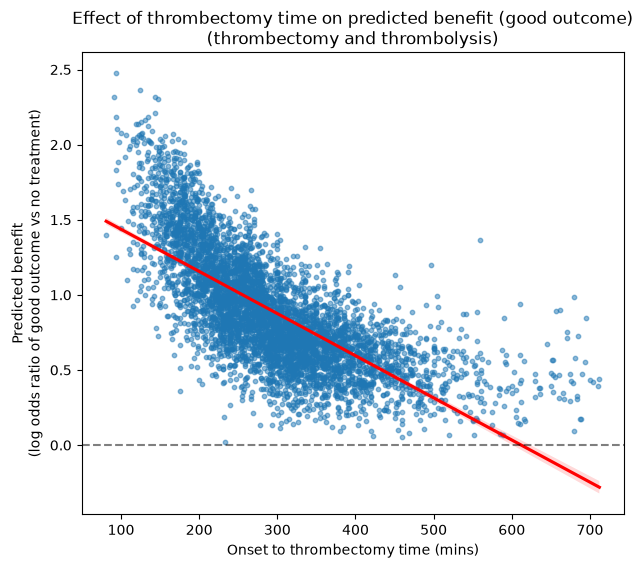

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.389
Model:                                            OLS   Adj. R-squared:                  0.389
Method:                                 Least Squares   F-statistic:                     3284.
Date:                                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                                        14:40:12   Log-Likelihood:                -1147.3
No. Observations:                                5164   AIC:                             2299.
Df Residuals:                                    5162   BIC:                             2312.
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

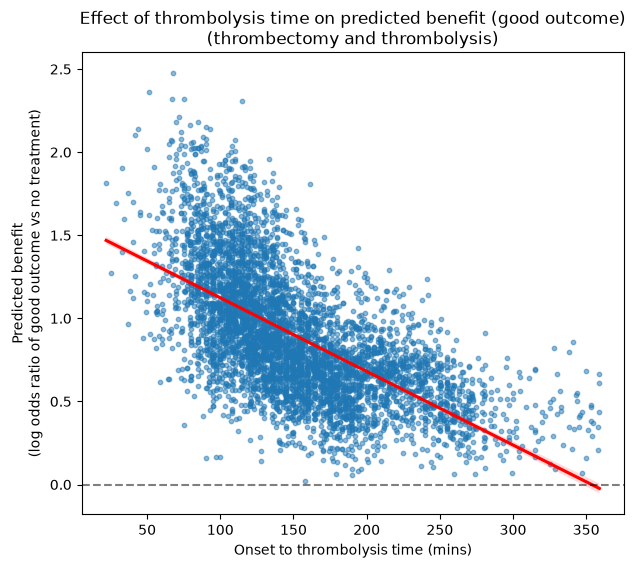

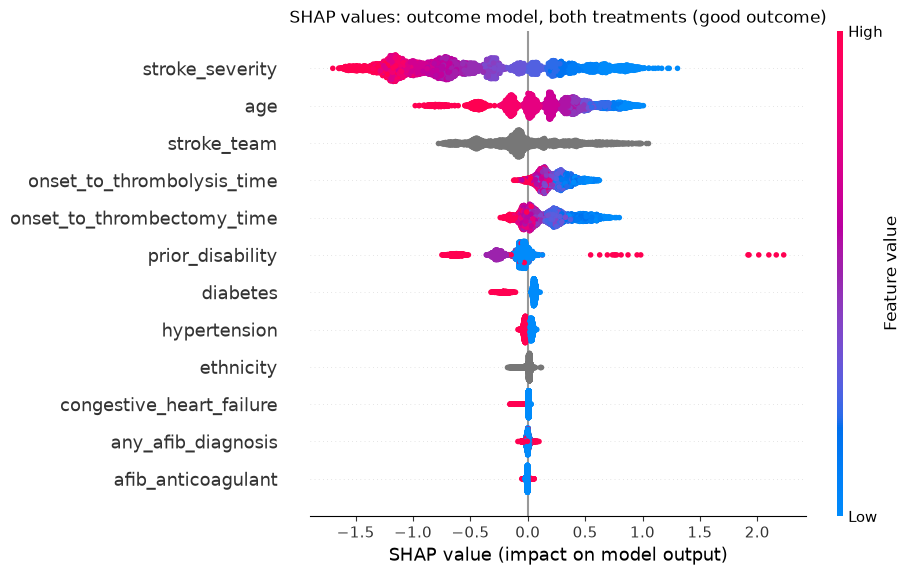

In [25]:
analyse_time_to_treatment(both, TIME_THROMBECTOMY, "thrombectomy",
                          "thrombectomy and thrombolysis", "time_effect_thrombectomy_both")
analyse_time_to_treatment(both, TIME_THROMBOLYSIS, "thrombolysis",
                          "thrombectomy and thrombolysis", "time_effect_thrombolysis_both")
plot_outcome_shap(both, "SHAP values: outcome model, both treatments (good outcome)")

**Results.** For patients given both treatments, predicted benefit falls from 1.72 at time zero with time to thrombectomy (zero at 612 minutes, 603 to 621) and from 1.57 with time to thrombolysis (zero at 354 minutes, 347 to 361).

**Discussion of Part A.** For each treatment, the S-learner's estimated benefit is largest when treatment is given soon after onset and declines roughly linearly with delay, by about 0.13 to 0.16 log-odds units per hour. Combined early treatment gives the largest benefit. The zero points are extrapolations and should not be read as treatment time limits.

# 3. Part B: S-learner with grouped treatment arms

## Method

The two continuous treatment times are replaced by one categorical feature, `treatment_group` (eight levels: neither, plus seven modality × early/late arms). Otherwise the approach matches Part A: the same outcome, the same adjustment features, 5-fold stratified cross-validation, and an XGBoost classifier. Hyperparameters are tuned separately for this model, in the same way as Part A (log loss, no class weighting).

Compared with Part A, grouping removes within-arm time detail but allows the model to treat each arm as a separate level, and produces simple per-arm summaries. The cell below tunes the model, then trains and evaluates it.

In [26]:
best_params_arms, tuning_arms = tune_xgb(data[X_FIELDS_GROUPS], y)
print("Selected hyperparameters:", best_params_arms)
display(tuning_arms.head(10))

folds_arms = split_folds(data[X_FIELDS_GROUPS], y)
models_arms, performance_arms = train_and_evaluate(folds_arms, xgb_factory(**best_params_arms))
performance_arms

Optuna: 47 trials completed, 13 pruned
Selected hyperparameters: {'max_depth': 3, 'learning_rate': 0.02822826941042137, 'n_estimators': 1000, 'min_child_weight': 2.4784388747125567, 'subsample': 0.8473807005175394, 'colsample_bytree': 0.520498081869668, 'reg_lambda': 2.280198529662911, 'reg_alpha': 2.700155333077662, 'gamma': 0.011269741369956765}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,log loss,AUC
trial,,,,,,,,,,,
45,3.0,0.0282,1000.0,2.4784,0.8474,0.5205,2.2802,2.7002,0.0113,0.5695,0.7637
33,3.0,0.0228,950.0,2.5269,0.8484,0.5131,2.1372,0.6157,0.0011,0.5696,0.7637
54,3.0,0.0201,950.0,1.8306,0.8984,0.5069,0.6609,0.4033,0.0023,0.5696,0.7636
34,3.0,0.0213,950.0,3.4001,0.8181,0.5321,1.3052,2.9828,0.0150,0.5697,0.7635
37,3.0,0.0260,850.0,4.3382,0.7852,0.5183,1.1815,1.5273,0.0018,0.5697,0.7636
44,3.0,0.0272,1000.0,1.8713,0.8381,0.5263,5.0288,0.9716,0.0025,0.5697,0.7636
49,3.0,0.0228,900.0,2.1398,0.8208,0.5010,1.4225,0.1879,0.0095,0.5697,0.7636
39,3.0,0.0225,850.0,1.0638,0.8264,0.5037,1.8255,0.1309,0.0014,0.5697,0.7635
50,3.0,0.0221,1000.0,4.3977,0.8760,0.5019,6.1279,0.4206,0.0015,0.5697,0.7635


,AUC,balanced_accuracy,actual_positive_rate,predicted_positive_rate,mean_predicted_probability
split,,,,,
1,0.7668,0.6884,0.4222,0.3814,0.4246
2,0.7622,0.6847,0.4222,0.3747,0.4193
3,0.7659,0.6871,0.4222,0.3836,0.4231
4,0.7651,0.6866,0.4222,0.3758,0.4203
5,0.7619,0.6884,0.4222,0.3871,0.4240


**Results.** 47 tuning trials completed and 13 were pruned. The selected model (depth 3, 1,000 trees, learning rate 0.028) has cross-validated log loss 0.5695 and AUC 0.764; again the top 10 trials differ by at most 0.0002. Out-of-fold AUC is 0.762 to 0.767 across folds, and the mean predicted probability (0.419 to 0.425) matches the observed rate (0.422).

## Counterfactual predictions by arm

For every patient in each held-out fold, the fold's model predicts with the actual arm, then with the arm set to "neither". The difference is the individual estimated treatment effect (probability and log-odds scales). Averaging within an arm gives the mean effect for patients who actually received that arm (an effect in the treated).

In [27]:
def predict_arm_counterfactuals(models, folds):
    """Out-of-fold predictions with the actual treatment arm and with the arm set to 'neither'."""
    frames = []
    for model, (_, test_X, _, _) in zip(models, folds):
        untreated_X = test_X.assign(treatment_group=pd.Categorical(
            ["neither"] * len(test_X), categories=test_X["treatment_group"].cat.categories
        ))
        fold_cf = test_X.copy()
        fold_cf["y_prob_treated"] = model.predict_proba(test_X)[:, 1]
        fold_cf["y_prob_untreated"] = model.predict_proba(untreated_X)[:, 1]
        frames.append(fold_cf)

    cf = pd.concat(frames, ignore_index=True)
    cf["prob_shift"] = cf["y_prob_treated"] - cf["y_prob_untreated"]
    cf["log_odds_shift"] = to_log_odds(cf["y_prob_treated"]) - to_log_odds(cf["y_prob_untreated"])
    return cf


cf_arms = predict_arm_counterfactuals(models_arms, folds_arms)

## Mean effect by treatment arm

Mean individual effect with 95% CI (mean ± 1.96 × SD / √n), first on the probability scale (table and forest plot). As in Part A, this CI reflects variation between patients' predicted effects, not model uncertainty; section 5 gives bootstrap CIs.

In [28]:
ARM_ORDER = [group for group in TREATMENT_GROUP_ORDER if group != "neither"]
ARM_LABELS = {
    "early_thrombolysis_only": "Early thrombolysis only",
    "late_thrombolysis_only": "Late thrombolysis only",
    "early_thrombectomy_only": "Early thrombectomy only",
    "late_thrombectomy_only": "Late thrombectomy only",
    "early_both": "Early both",
    "early_thrombolysis_late_thrombectomy": "Early thrombolysis,\nlate thrombectomy",
    "late_both": "Late both",
}


def summarise_by_arm(cf, value_col):
    """Mean, SD, n and 95% CI of value_col for each treatment arm."""
    summary = cf.groupby("treatment_group", observed=True)[value_col].agg(["mean", "std", "count"])
    half_width = 1.96 * summary["std"] / np.sqrt(summary["count"])
    summary["95% CI lower"] = summary["mean"] - half_width
    summary["95% CI upper"] = summary["mean"] + half_width
    return summary.reindex(ARM_ORDER)


def plot_arm_estimates(summary, xlabel, filename):
    """Forest plot of per-arm estimates with 95% CIs."""
    labels = [f"{ARM_LABELS[arm]}\n(n={n:.0f})" for arm, n in summary["count"].items()]
    y_pos = np.arange(len(summary))[::-1]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.errorbar(
        summary["mean"], y_pos,
        xerr=[summary["mean"] - summary["95% CI lower"], summary["95% CI upper"] - summary["mean"]],
        fmt="o", markersize=7, capsize=5,
    )
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.axvline(0, linestyle="--", alpha=0.7)
    ax.grid(axis="x", linestyle="--", alpha=0.7)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"Treatment arm (early: thrombolysis <= {CUTOFF} min, thrombectomy < {CUTOFF} min)",
                  labelpad=15)
    fig.tight_layout(pad=2)
    fig.savefig(output_path(f"{filename}.png"), dpi=300)
    plt.show()


arm_summary_prob = summarise_by_arm(cf_arms, "prob_shift")
arm_summary_log_odds = summarise_by_arm(cf_arms, "log_odds_shift")
arm_summary_prob.round(4)

,mean,std,count,95% CI lower,95% CI upper
treatment_group,,,,,
early_thrombolysis_only,0.1249,0.0480,27695,0.1243,0.1255
late_thrombolysis_only,0.0813,0.0320,1189,0.0795,0.0832
early_thrombectomy_only,0.1725,0.0654,1107,0.1686,0.1763
late_thrombectomy_only,0.0776,0.0343,1876,0.0760,0.0791
early_both,0.2169,0.0728,2309,0.2139,0.2199
early_thrombolysis_late_thrombectomy,0.1055,0.0397,2714,0.1040,0.1070
late_both,0.1294,0.0514,141,0.1209,0.1379


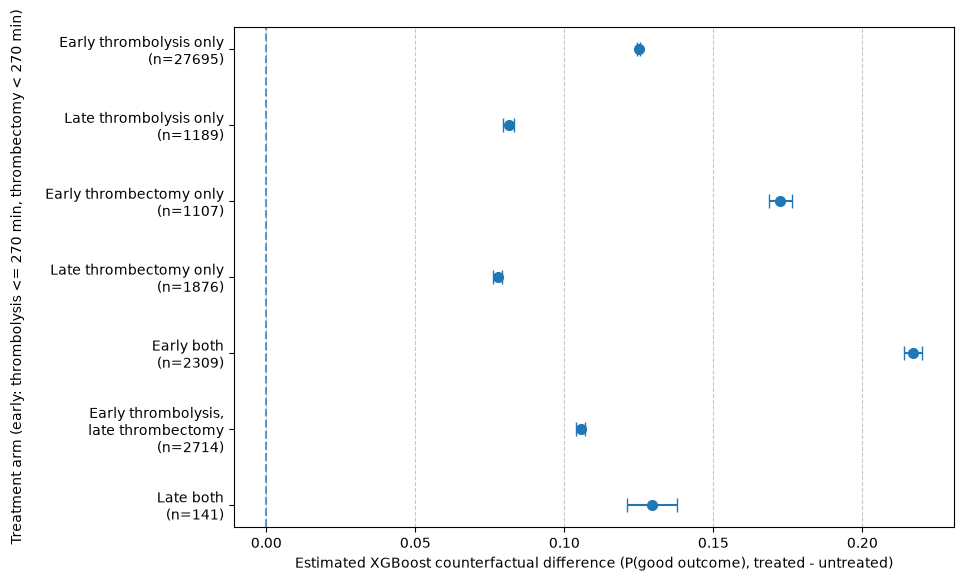

In [29]:
plot_arm_estimates(
    arm_summary_prob,
    "Estimated XGBoost counterfactual difference (P(good outcome), treated - untreated)",
    "counterfactual_cate_probabilities_estimates",
)

The same on the log-odds scale (table and forest plot).

In [30]:
arm_summary_log_odds.round(4)

,mean,std,count,95% CI lower,95% CI upper
treatment_group,,,,,
early_thrombolysis_only,0.6415,0.1834,27695,0.6394,0.6437
late_thrombolysis_only,0.4120,0.1171,1189,0.4053,0.4186
early_thrombectomy_only,0.9982,0.2317,1107,0.9845,1.0118
late_thrombectomy_only,0.4723,0.1713,1876,0.4645,0.4800
early_both,1.1566,0.2335,2309,1.1471,1.1662
early_thrombolysis_late_thrombectomy,0.6047,0.1642,2714,0.5985,0.6109
late_both,0.6851,0.2213,141,0.6486,0.7216


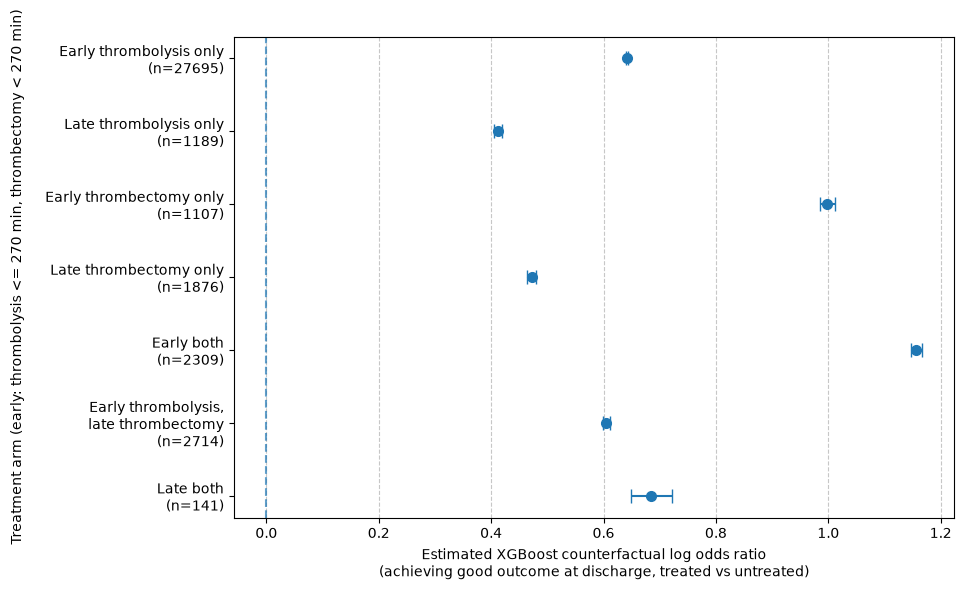

In [31]:
plot_arm_estimates(
    arm_summary_log_odds,
    "Estimated XGBoost counterfactual log odds ratio\n(achieving good outcome at discharge, treated vs untreated)",
    "counterfactual_cate_log_odds_estimates",
)

**Results.** Every arm is associated with a higher probability of a good outcome:

| Arm | n | Probability difference (pp) | Log odds ratio |
|---|---|---|---|
| Early thrombolysis only | 27,695 | 12.5 | 0.64 |
| Late thrombolysis only | 1,189 | 8.1 | 0.41 |
| Early thrombectomy only | 1,107 | 17.2 | 1.00 |
| Late thrombectomy only | 1,876 | 7.8 | 0.47 |
| Early both | 2,309 | 21.7 | 1.16 |
| Early thrombolysis, late thrombectomy | 2,714 | 10.6 | 0.60 |
| Late both | 141 | 12.9 | 0.69 |

**Discussion.** Early treatment is associated with larger effects than late treatment for each modality (thrombolysis only 12.5 vs 8.1 points; thrombectomy only 17.2 vs 7.8), and after early thrombolysis, early thrombectomy gives about twice the effect of late thrombectomy (21.7 vs 10.6). The between-patient CIs are very narrow and should not be used for inference.

# 4. Part C: Meta-model of benefit

## Method

An XGBoost regression model is fitted to the individual estimated benefit (Part B log-odds shift) of all treated patients, using the same features as the Part B model (including treatment arm). SHAP values for this meta-model show which characteristics are associated with larger or smaller estimated benefit (treatment effect heterogeneity).

* In-sample R-squared shows how much of the S-learner's benefit variation the meta-model reproduces. It is optimistic because the model is evaluated on its own training data, so a 5-fold out-of-fold R-squared is also reported, with a plot of meta-model predictions against S-learner estimates.
* The meta-model describes the S-learner's estimates. It cannot find heterogeneity the S-learner did not estimate, and inherits any bias in it.

In [32]:
benefit_df = cf_arms[cf_arms["treatment_group"] != "neither"].copy()
meta_X = benefit_df[X_FIELDS_GROUPS]
meta_y = benefit_df["log_odds_shift"]


def make_meta_model():
    return XGBRegressor(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="rmse")


meta_model = make_meta_model().fit(meta_X, meta_y)
benefit_df["predicted_log_odds_shift"] = meta_model.predict(meta_X)
benefit_df["oof_predicted_log_odds_shift"] = cross_val_predict(
    make_meta_model(), meta_X, meta_y,
    cv=KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
)

r2_in_sample = r2_score(meta_y, benefit_df["predicted_log_odds_shift"])
r2_out_of_fold = r2_score(meta_y, benefit_df["oof_predicted_log_odds_shift"])
print(f"Meta-model R-squared: in-sample {r2_in_sample:.4f}, out-of-fold {r2_out_of_fold:.4f}")

Meta-model R-squared: in-sample 0.9669, out-of-fold 0.9319


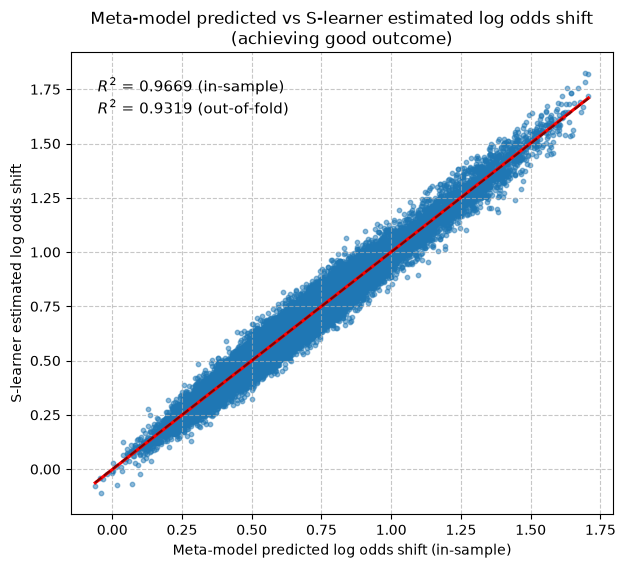

In [33]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.regplot(x="predicted_log_odds_shift", y="log_odds_shift", data=benefit_df, ci=95, ax=ax,
            scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
limits = [benefit_df["predicted_log_odds_shift"].min(), benefit_df["predicted_log_odds_shift"].max()]
ax.plot(limits, limits, color="black", linestyle="--", alpha=0.5)  # y = x
ax.set_title("Meta-model predicted vs S-learner estimated log odds shift\n(achieving good outcome)")
ax.set_xlabel("Meta-model predicted log odds shift (in-sample)")
ax.set_ylabel("S-learner estimated log odds shift")
ax.grid(linestyle="--", alpha=0.7)
ax.text(0.05, 0.95, f"$R^2$ = {r2_in_sample:.4f} (in-sample)\n$R^2$ = {r2_out_of_fold:.4f} (out-of-fold)",
        transform=ax.transAxes, fontsize=11, verticalalignment="top")
plt.show()

**Results.** The meta-model reproduces the S-learner's individual benefit estimates closely (R-squared 0.967 in-sample, 0.932 out-of-fold), so its SHAP values are a faithful description of how estimated benefit varies.

## SHAP values for the meta-model

Positive SHAP values mean the feature value is associated with *greater* estimated benefit from treatment.

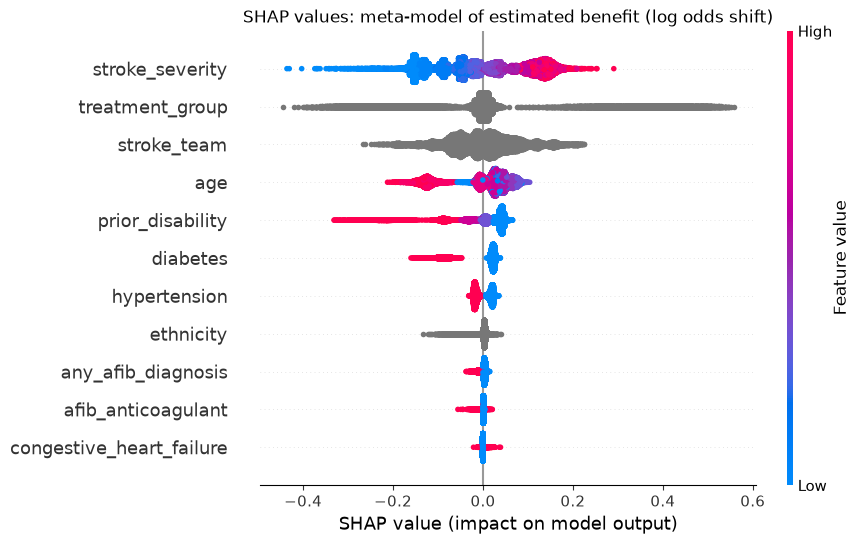

In [34]:
meta_shap_values = shap.Explainer(meta_model)(meta_X)
shap.plots.beeswarm(meta_shap_values, max_display=99, show=False)
plt.title("SHAP values: meta-model of estimated benefit (log odds shift)")
plt.savefig(output_path("treatment_effect_shap_beeswarm.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Treatment arm, stroke severity and stroke team have the largest influence on estimated benefit, followed by age and prior disability. Higher NIHSS is associated with greater benefit; older age and more pre-stroke disability with less.

### SHAP values by feature value

One panel per feature, ordered by mean |SHAP|, all on the same y-axis scale. Box whiskers show the full range. Stroke teams are sorted by mean SHAP value (labels hidden). For stroke severity, every fifth NIHSS value is labelled.

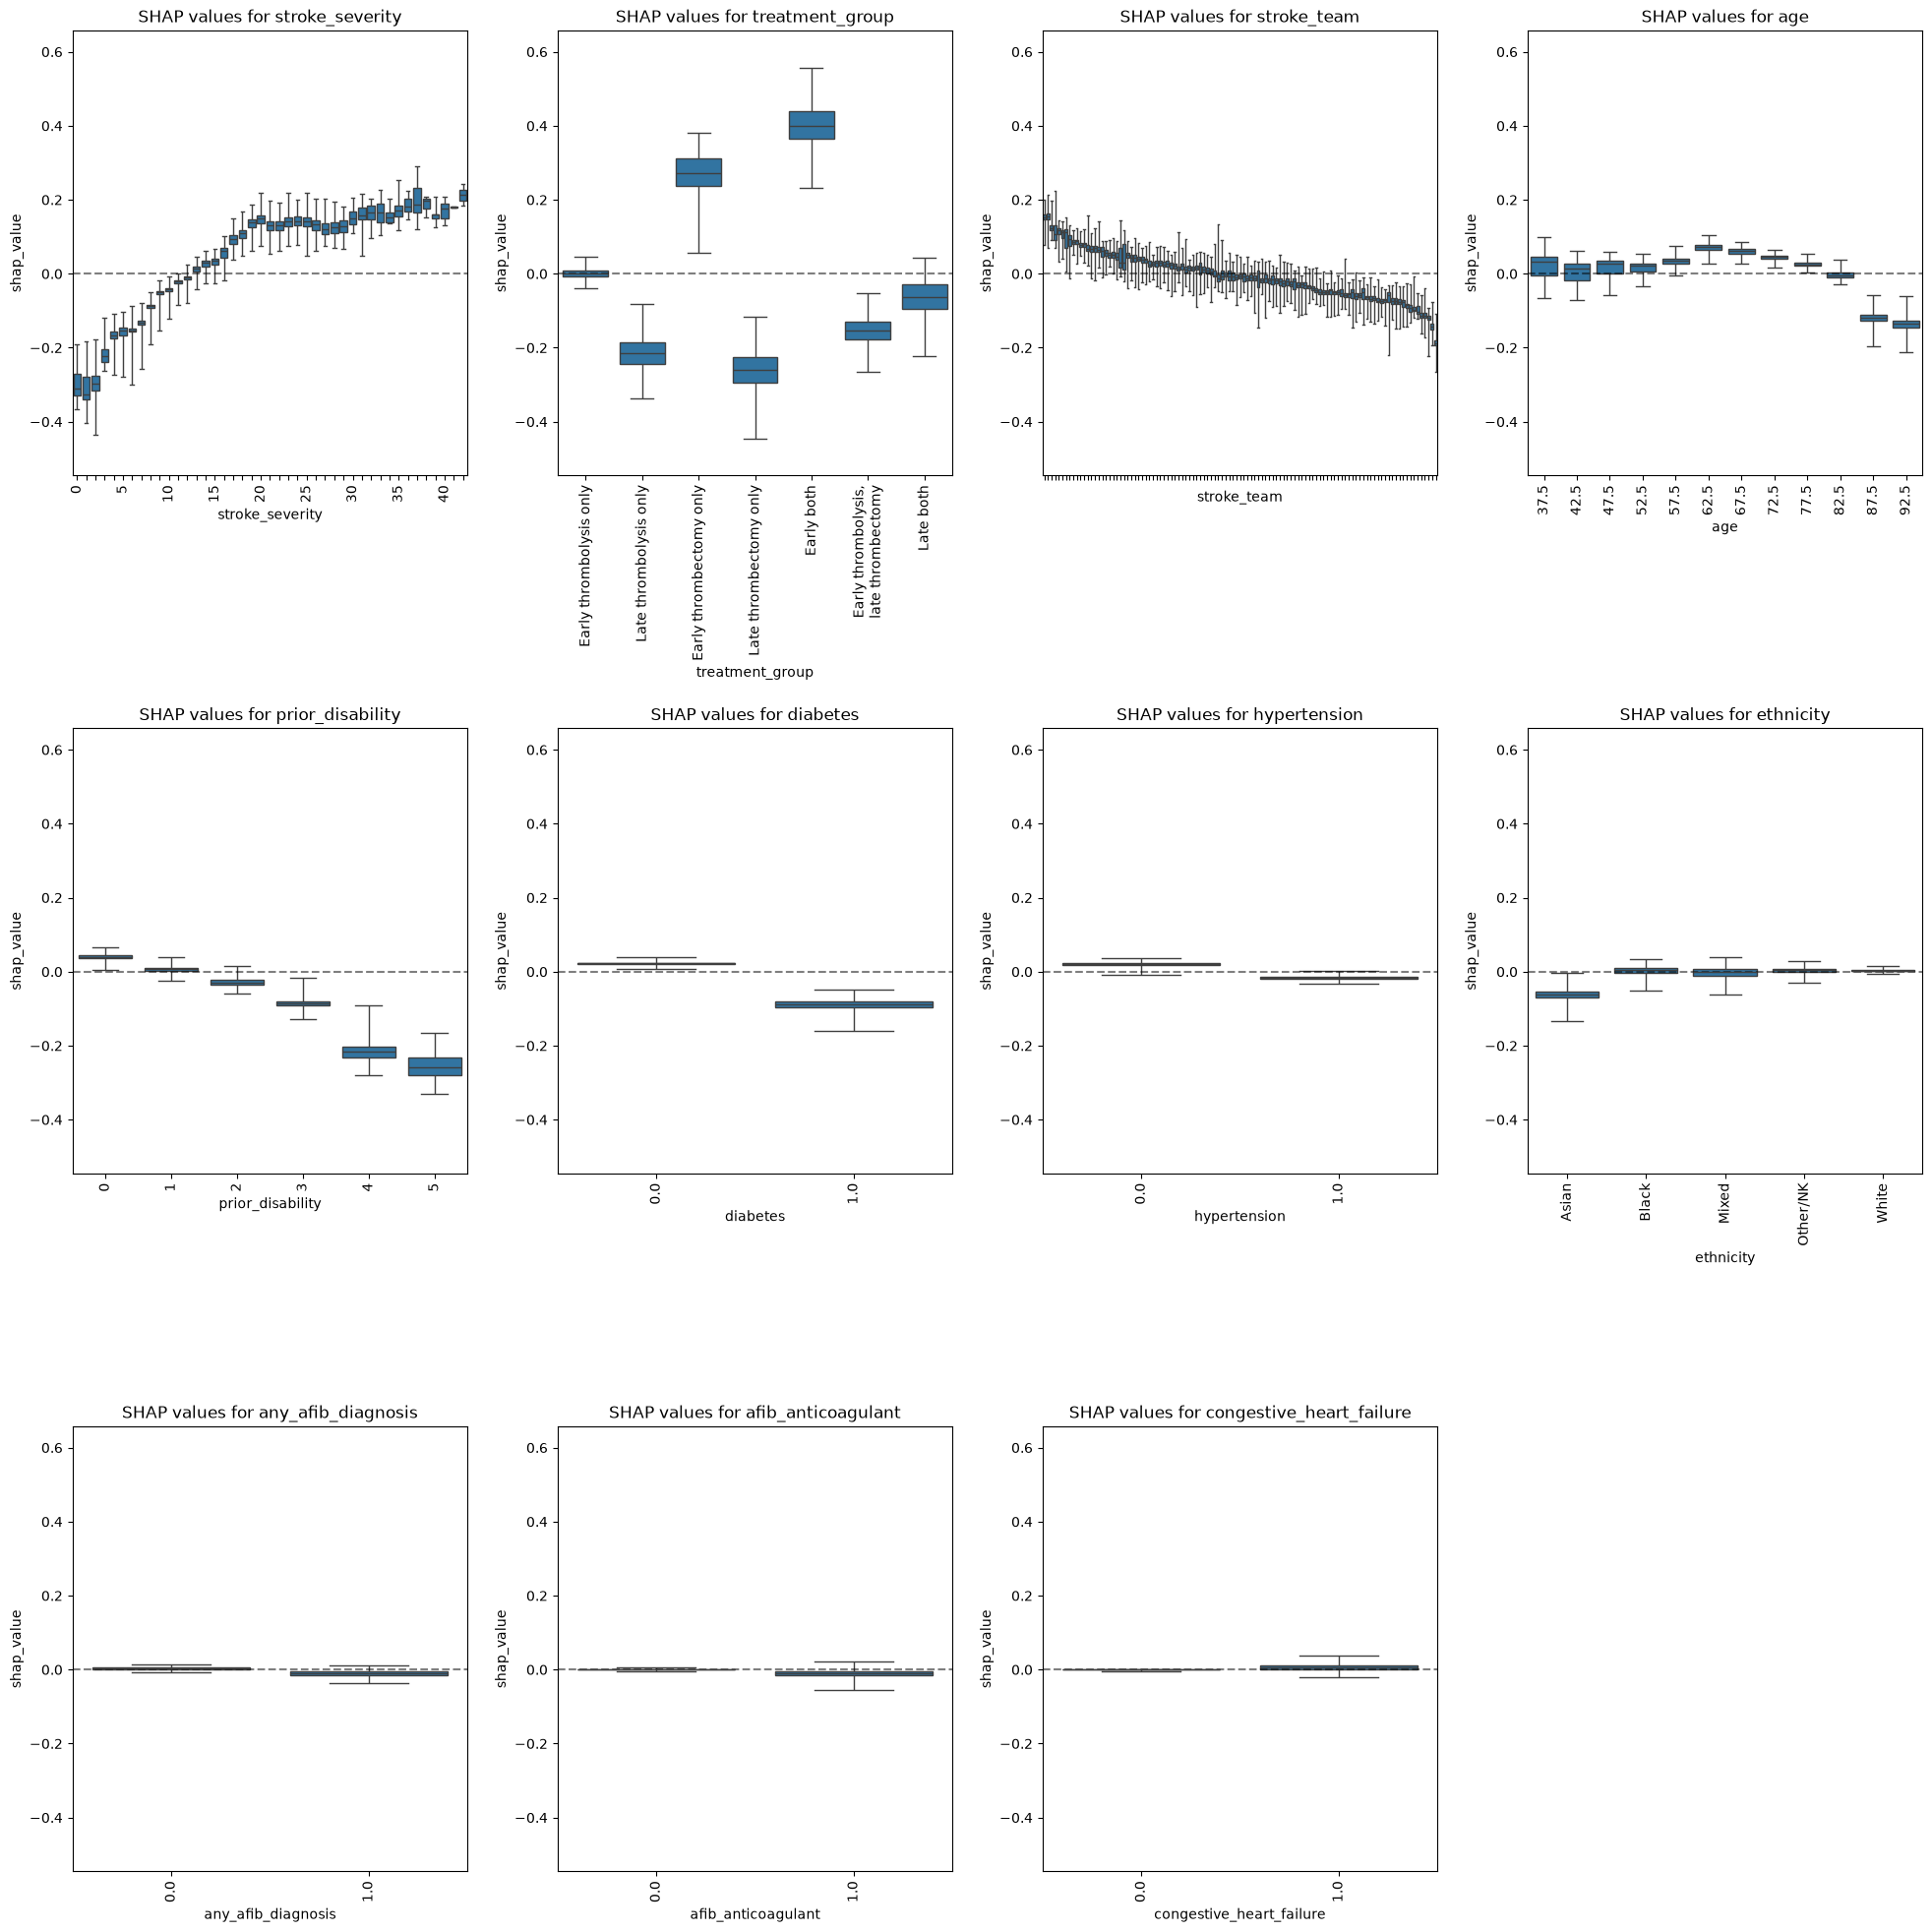

In [35]:
meta_shap_df = pd.DataFrame(meta_shap_values.values, columns=meta_X.columns)
features_by_importance = meta_shap_df.abs().mean().sort_values(ascending=False).index.tolist()

shap_range = meta_shap_df.min().min(), meta_shap_df.max().max()
padding = 0.1 * (shap_range[1] - shap_range[0])
y_limits = (shap_range[0] - padding, shap_range[1] + padding)

fig, axes = plt.subplots(3, 4, figsize=(20, 20))

for ax, feature in zip(axes.flat, features_by_importance):
    plot_df = pd.DataFrame({
        "feature_value": meta_X[feature].values,
        "shap_value": meta_shap_df[feature].values,
    })

    if feature == "stroke_team":
        team_order = plot_df.groupby("feature_value", observed=True)["shap_value"].mean()
        team_order = team_order.sort_values(ascending=False).index.tolist()
        plot_df["feature_value"] = pd.Categorical(plot_df["feature_value"].astype(str),
                                                  categories=[str(t) for t in team_order], ordered=True)
    elif feature == "treatment_group":
        plot_df["feature_value"] = pd.Categorical(
            plot_df["feature_value"].astype(str).map(ARM_LABELS),
            categories=[ARM_LABELS[arm] for arm in ARM_ORDER], ordered=True,
        )

    sns.boxplot(x="feature_value", y="shap_value", data=plot_df, ax=ax, whis=(0, 100))
    ax.set_title(f"SHAP values for {feature}")
    ax.set_xlabel(feature)
    ax.tick_params(axis="x", rotation=90)
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_ylim(y_limits)

    if feature == "stroke_team":
        ax.set_xticklabels([])
    elif feature == "stroke_severity":
        tick_values = [float(label.get_text()) for label in ax.get_xticklabels()]
        ax.set_xticklabels([f"{v:.0f}" if v % 5 == 0 else "" for v in tick_values])

# Hide unused panels
for ax in axes.flat[len(features_by_importance):]:
    ax.axis("off")

plt.tight_layout(pad=2)
plt.savefig(output_path("treatment_effect_shap_box_plots.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.**

* **Stroke severity:** estimated benefit rises with NIHSS, from about −0.3 log-odds units (relative to average) at NIHSS 0–5 to about +0.15 at NIHSS 20 and above, levelling off above about 20.
* **Treatment arm:** early both (about +0.4) and early thrombectomy only (+0.27) have the largest benefit; late thrombolysis only and late thrombectomy only the smallest (about −0.2 to −0.27).
* **Stroke team:** team means range from about +0.15 to −0.15, a spread similar to the effect of age.
* **Age:** benefit is similar up to about 77.5 years and lower at 82.5 years and over (about −0.12).
* **Prior disability:** benefit falls with pre-stroke mRS, to about −0.25 at mRS 5.
* **Diabetes** is associated with slightly lower benefit (about −0.08). Hypertension, ethnicity, AF and heart failure have little effect.

**Discussion.** These patterns describe the model's estimates and are adjusted for the other features. Larger benefit in more severe strokes is clinically plausible; smaller benefit in the oldest and most disabled patients partly reflects the outcome definition and their lower chance of a good outcome either way.

# 5. Uncertainty from refitting the model, discrimination and calibration

The confidence intervals above reflect variation between patients' predicted effects only. Here the Part B pipeline is repeated on 30 bootstrap samples with the tuned hyperparameters held fixed, giving confidence intervals that include model uncertainty (TARGET item 13). The out-of-fold ROC AUC is given with a bootstrap 95% CI, and calibration is shown by decile and summarised by the calibration intercept and slope (TRIPOD items 10d and 16). Results are also printed as LaTeX rows for the paper.

Bootstrap 1/30 done
Bootstrap 2/30 done
Bootstrap 3/30 done
Bootstrap 4/30 done
Bootstrap 5/30 done
Bootstrap 6/30 done
Bootstrap 7/30 done
Bootstrap 8/30 done
Bootstrap 9/30 done
Bootstrap 10/30 done
Bootstrap 11/30 done
Bootstrap 12/30 done
Bootstrap 13/30 done
Bootstrap 14/30 done
Bootstrap 15/30 done
Bootstrap 16/30 done
Bootstrap 17/30 done
Bootstrap 18/30 done
Bootstrap 19/30 done
Bootstrap 20/30 done
Bootstrap 21/30 done
Bootstrap 22/30 done
Bootstrap 23/30 done
Bootstrap 24/30 done
Bootstrap 25/30 done
Bootstrap 26/30 done
Bootstrap 27/30 done
Bootstrap 28/30 done
Bootstrap 29/30 done
Bootstrap 30/30 done


,n,prob_shift,prob_se_boot,log_odds_shift,log_odds_se_boot,prob_shift_lower,prob_shift_upper,log_odds_shift_lower,log_odds_shift_upper
treatment_group,,,,,,,,,
early_thrombolysis_only,27695,0.1249,0.0046,0.6415,0.0253,0.1158,0.1340,0.5920,0.6910
late_thrombolysis_only,1189,0.0813,0.0120,0.4120,0.0622,0.0578,0.1049,0.2902,0.5338
early_thrombectomy_only,1107,0.1725,0.0142,0.9982,0.0702,0.1446,0.2003,0.8605,1.1359
late_thrombectomy_only,1876,0.0776,0.0096,0.4723,0.0529,0.0587,0.0964,0.3687,0.5759
early_both,2309,0.2169,0.0111,1.1566,0.0561,0.1951,0.2388,1.0467,1.2666
early_thrombolysis_late_thrombectomy,2714,0.1055,0.0083,0.6047,0.0458,0.0893,0.1217,0.5150,0.6945
late_both,141,0.1294,0.0333,0.6851,0.1552,0.0641,0.1947,0.3810,0.9892


% ---- S-learner effects with bootstrap 95% CIs ----
early_thrombolysis_only & 27,695 & 12.5 (11.6--13.4) & 0.64 (0.59--0.69) & 1.90 (1.81--2.00) \\
late_thrombolysis_only & 1,189 & 8.1 (5.8--10.5) & 0.41 (0.29--0.53) & 1.51 (1.34--1.71) \\
early_thrombectomy_only & 1,107 & 17.2 (14.5--20.0) & 1.00 (0.86--1.14) & 2.71 (2.36--3.11) \\
late_thrombectomy_only & 1,876 & 7.8 (5.9--9.6) & 0.47 (0.37--0.58) & 1.60 (1.45--1.78) \\
early_both & 2,309 & 21.7 (19.5--23.9) & 1.16 (1.05--1.27) & 3.18 (2.85--3.55) \\
early_thrombolysis_late_thrombectomy & 2,714 & 10.6 (8.9--12.2) & 0.60 (0.51--0.69) & 1.83 (1.67--2.00) \\
late_both & 141 & 12.9 (6.4--19.5) & 0.69 (0.38--0.99) & 1.98 (1.46--2.69) \\


,estimate,ci_lower,ci_upper
ROC AUC,0.764,0.760,0.767
Calibration intercept,-0.000,-0.015,0.013
Calibration slope,0.992,0.971,1.008


,n,predicted,observed
decile,,,
1,7468,0.080,0.075
2,7468,0.159,0.155
3,7468,0.232,0.237
4,7467,0.304,0.309
5,7468,0.376,0.382
6,7468,0.448,0.450
7,7467,0.524,0.525
8,7468,0.604,0.611
9,7468,0.689,0.684


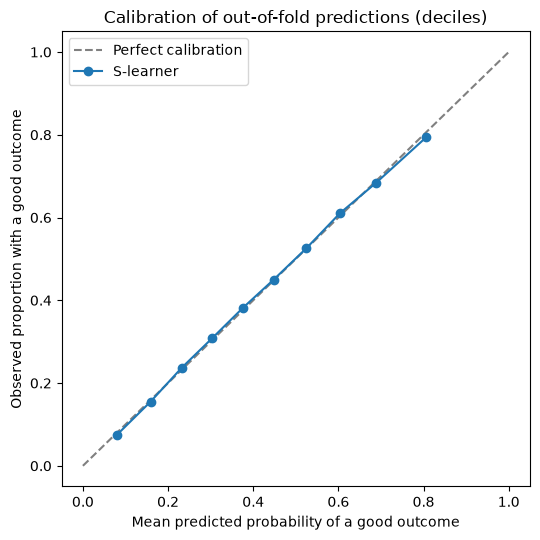

% ---- S-learner performance ----
% ROC AUC: 0.764 (0.760--0.767)
% Calibration intercept: -0.000 (-0.015--0.013)
% Calibration slope: 0.992 (0.971--1.008)
% ---- S-learner calibration by decile: n, predicted, observed ----
1 & 7,468 & 0.080 & 0.075 \\
2 & 7,468 & 0.159 & 0.155 \\
3 & 7,468 & 0.232 & 0.237 \\
4 & 7,467 & 0.304 & 0.309 \\
5 & 7,468 & 0.376 & 0.382 \\
6 & 7,468 & 0.448 & 0.450 \\
7 & 7,467 & 0.524 & 0.525 \\
8 & 7,468 & 0.604 & 0.611 \\
9 & 7,468 & 0.689 & 0.684 \\
10 & 7,468 & 0.806 & 0.794 \\


In [36]:
# Uncertainty in the S-learner effects from refitting the model (Part B, treatment groups).
# The confidence intervals above reflect variation between patients' predicted effects only.
# Here the whole pipeline is repeated on N_BOOT bootstrap samples of patients, with the tuned
# hyperparameters held fixed: five-fold cross-validation (copies of the same patient are kept in one
# fold), out-of-fold counterfactual predictions, and the mean effect in each treatment group.
# The 95% CI is the point estimate +/- 1.96 x the bootstrap standard deviation.
# Also: 95% CI for the out-of-fold ROC AUC, and calibration of the out-of-fold predictions
# (by decile, and calibration intercept and slope), each from N_BOOT bootstrap samples.

from sklearn.linear_model import LogisticRegression

N_BOOT = 30
boot_rng = np.random.default_rng(RANDOM_STATE)
X_groups = data[X_FIELDS_GROUPS]
patient_fold = boot_rng.integers(0, N_SPLITS, len(data))  # fold for each original patient

boot_rows = []
for b in range(N_BOOT):
    idx = boot_rng.integers(0, len(data), len(data))
    Xb = X_groups.iloc[idx].reset_index(drop=True)
    yb = y.iloc[idx].reset_index(drop=True)
    fold_b = patient_fold[idx]
    folds_b = [
        (Xb[fold_b != k], Xb[fold_b == k], yb[fold_b != k], yb[fold_b == k])
        for k in range(N_SPLITS)
    ]
    models_b, _ = train_and_evaluate(folds_b, xgb_factory(**best_params_arms))
    cf_b = predict_arm_counterfactuals(models_b, folds_b)
    means = (cf_b.groupby("treatment_group", observed=True)[["prob_shift", "log_odds_shift"]]
             .mean().reindex(ARM_ORDER))
    means["bootstrap"] = b
    boot_rows.append(means.reset_index())
    print(f"Bootstrap {b + 1}/{N_BOOT} done")

s_learner_boot = pd.concat(boot_rows, ignore_index=True)
s_learner_boot.to_csv(output_path("bootstrap_effects.csv"), index=False)

boot_sd = s_learner_boot.groupby("treatment_group")[["prob_shift", "log_odds_shift"]].std(ddof=1)
boot_summary = pd.DataFrame({
    "n": arm_summary_prob["count"],
    "prob_shift": arm_summary_prob["mean"],
    "prob_se_boot": boot_sd["prob_shift"].reindex(ARM_ORDER),
    "log_odds_shift": arm_summary_log_odds["mean"],
    "log_odds_se_boot": boot_sd["log_odds_shift"].reindex(ARM_ORDER),
})
for col, se in [("prob_shift", "prob_se_boot"), ("log_odds_shift", "log_odds_se_boot")]:
    boot_summary[f"{col}_lower"] = boot_summary[col] - 1.96 * boot_summary[se]
    boot_summary[f"{col}_upper"] = boot_summary[col] + 1.96 * boot_summary[se]
boot_summary.to_csv(output_path("bootstrap_summary.csv"))
display(boot_summary.round(4))

print("% ---- S-learner effects with bootstrap 95% CIs ----")
for arm_name, r in boot_summary.iterrows():
    print(f"{arm_name} & {int(r['n']):,} & "
          f"{100 * r['prob_shift']:.1f} ({100 * r['prob_shift_lower']:.1f}--{100 * r['prob_shift_upper']:.1f}) & "
          f"{r['log_odds_shift']:.2f} ({r['log_odds_shift_lower']:.2f}--{r['log_odds_shift_upper']:.2f}) & "
          f"{np.exp(r['log_odds_shift']):.2f} ({np.exp(r['log_odds_shift_lower']):.2f}--"
          f"{np.exp(r['log_odds_shift_upper']):.2f}) \\\\")

# Out-of-fold predictions of the primary model (Part B) with the treatment actually received
oof_y = pd.concat([test_y for (_, _, _, test_y) in folds_arms]).to_numpy()
oof_p = cf_arms["y_prob_treated"].to_numpy()


def calibration_intercept_slope(y_true, prob):
    """Calibration intercept (calibration-in-the-large, slope fixed at 1) and slope (logistic
    recalibration of the outcome on the logit of the predicted probability)."""
    logit = to_log_odds(prob)
    slope = LogisticRegression(C=1e12, max_iter=1000).fit(logit.reshape(-1, 1), y_true).coef_[0, 0]
    # intercept with the slope fixed at 1: Newton iterations for the offset model
    a = 0.0
    for _ in range(50):
        p = 1 / (1 + np.exp(-(a + logit)))
        a += (y_true - p).sum() / (p * (1 - p)).sum()
    return a, slope


def bootstrap_performance(y_true, prob, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Point estimates and percentile 95% CIs for ROC AUC and calibration intercept and slope."""
    rng = np.random.default_rng(seed)
    point = [roc_auc_score(y_true, prob), *calibration_intercept_slope(y_true, prob)]
    draws = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        draws.append([roc_auc_score(y_true[i], prob[i]), *calibration_intercept_slope(y_true[i], prob[i])])
    draws = np.array(draws)
    return pd.DataFrame({
        "estimate": point,
        "ci_lower": np.percentile(draws, 2.5, axis=0),
        "ci_upper": np.percentile(draws, 97.5, axis=0),
    }, index=["ROC AUC", "Calibration intercept", "Calibration slope"])


def calibration_by_decile(y_true, prob):
    """Mean predicted probability and observed proportion in each decile of predicted probability."""
    decile = pd.qcut(prob, 10, labels=False, duplicates="drop")
    return (pd.DataFrame({"decile": decile + 1, "predicted": prob, "observed": y_true})
            .groupby("decile").agg(n=("observed", "size"), predicted=("predicted", "mean"),
                                   observed=("observed", "mean")))


s_learner_performance = bootstrap_performance(oof_y, oof_p)
s_learner_calibration = calibration_by_decile(oof_y, oof_p)
s_learner_performance.to_csv(output_path("performance_bootstrap.csv"))
s_learner_calibration.to_csv(output_path("calibration_deciles.csv"))
display(s_learner_performance.round(3))
display(s_learner_calibration.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.plot(s_learner_calibration["predicted"], s_learner_calibration["observed"], "o-", label="S-learner")
ax.set_xlabel("Mean predicted probability of a good outcome")
ax.set_ylabel("Observed proportion with a good outcome")
ax.set_title("Calibration of out-of-fold predictions (deciles)")
ax.legend()
fig.tight_layout()
fig.savefig(output_path("calibration.png"), dpi=300)
plt.show()

print("% ---- S-learner performance ----")
for name, r in s_learner_performance.iterrows():
    print(f"% {name}: {r['estimate']:.3f} ({r['ci_lower']:.3f}--{r['ci_upper']:.3f})")
print("% ---- S-learner calibration by decile: n, predicted, observed ----")
for d, r in s_learner_calibration.iterrows():
    print(f"{d} & {int(r['n']):,} & {r['predicted']:.3f} & {r['observed']:.3f} \\\\")


**Results.**

* **Effects with bootstrap 95% CIs** (percentage points; log odds ratio):
  * early thrombolysis only: 12.5 (11.6 to 13.4); 0.64 (0.59 to 0.69)
  * late thrombolysis only: 8.1 (5.8 to 10.5); 0.41 (0.29 to 0.53)
  * early thrombectomy only: 17.2 (14.5 to 20.0); 1.00 (0.86 to 1.14)
  * late thrombectomy only: 7.8 (5.9 to 9.6); 0.47 (0.37 to 0.58)
  * early both: 21.7 (19.5 to 23.9); 1.16 (1.05 to 1.27)
  * early thrombolysis, late thrombectomy: 10.6 (8.9 to 12.2); 0.60 (0.51 to 0.69)
  * late both: 12.9 (6.4 to 19.5); 0.69 (0.38 to 0.99)
* Every bootstrap CI excludes zero. The bootstrap CIs are much wider than the between-patient CIs (for example early thrombolysis only 11.6 to 13.4, compared with 12.4 to 12.6), so model uncertainty dominates.
* **Discrimination:** out-of-fold AUC 0.764 (0.760 to 0.767).
* **Calibration:** intercept 0.000 (−0.015 to 0.013) and slope 0.992 (0.971 to 1.008). Predicted and observed proportions agree within 0.012 in every decile (from 0.080 vs 0.075 in the lowest to 0.806 vs 0.794 in the highest).

**Discussion.** The outcome model is well calibrated across the whole range of risk, which supports using differences in predicted probabilities as effect estimates.

# 6. Part D: Sensitivity analyses

The S-learner estimates rest on assumptions and analytic choices. This section tests how far the Part B per-arm estimates depend on them:

| Concern | Analysis |
|---|---|
| **Positivity / overlap:** are there comparable untreated patients for treated patients? | D1: propensity model for receiving any reperfusion treatment; check its distribution; re-estimate after trimming extreme propensities (in D2). |
| **Analytic choices:** class weighting, fold allocation, outcome definition, early/late cut-off, covariate set, population, model flexibility, model class | D2: re-run the Part B pipeline under alternative specifications and compare per-arm estimates with the base case. |
| **Unmeasured confounding** (e.g. confounding by indication: clinicians' judgement of likely benefit) | D3: E-values for each arm's odds ratio. D4: sensemakr robustness values and benchmark bounds from a linear probability model. |
| **Dependence on measured confounders** | D5: leave NIHSS, age or pre-stroke mRS out of the model in turn. |

Runtime: D2 fits 5 models for each of 15 scenarios, so it takes several minutes.

## D1. Overlap (positivity)

An XGBoost classifier predicts the probability of receiving any reperfusion treatment (thrombolysis and/or thrombectomy) from the adjustment features, using out-of-fold predictions. If treated and untreated patients have very different propensity distributions, or many patients have propensities near 0 or 1, the S-learner has to extrapolate for those patients and its counterfactual predictions are less reliable.

Patients outside `PROPENSITY_TRIM` (0.05 to 0.95) are counted by arm and are excluded in the trimmed scenario in D2.

Propensity model AUC (out-of-fold): 0.751


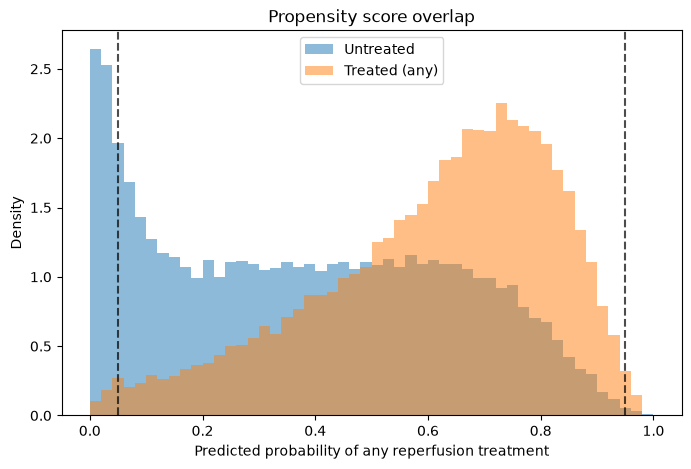

,n outside trim range,proportion outside trim range
treatment_group,,
neither,4669,0.124
early_thrombolysis_only,346,0.012
late_thrombolysis_only,13,0.011
early_thrombectomy_only,32,0.029
late_thrombectomy_only,45,0.024
early_both,41,0.018
early_thrombolysis_late_thrombectomy,31,0.011
late_both,1,0.007


In [37]:
PROPENSITY_TRIM = (0.05, 0.95)

any_treatment = (data["treatment_group"] != "neither").astype(int)
propensity_features = ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES

data["propensity_any_treatment"] = cross_val_predict(
    XGBClassifier(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="logloss"),
    data[propensity_features], any_treatment,
    cv=StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba",
)[:, 1]

print(f"Propensity model AUC (out-of-fold): "
      f"{roc_auc_score(any_treatment, data['propensity_any_treatment']):.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
for label, mask in [("Untreated", any_treatment == 0), ("Treated (any)", any_treatment == 1)]:
    ax.hist(data.loc[mask, "propensity_any_treatment"], bins=50, range=(0, 1),
            density=True, alpha=0.5, label=label)
for limit in PROPENSITY_TRIM:
    ax.axvline(limit, color="black", linestyle="--", alpha=0.7)
ax.set_xlabel("Predicted probability of any reperfusion treatment")
ax.set_ylabel("Density")
ax.set_title("Propensity score overlap")
ax.legend()
fig.savefig(output_path("sensitivity_propensity_overlap.png"), dpi=300, bbox_inches="tight")
plt.show()

outside_trim = ~data["propensity_any_treatment"].between(*PROPENSITY_TRIM)
(
    outside_trim.groupby(data["treatment_group"], observed=False)
    .agg(["sum", "mean"])
    .rename(columns={"sum": "n outside trim range", "mean": "proportion outside trim range"})
    .reindex(TREATMENT_GROUP_ORDER)
    .round(3)
)

**Results.** The propensity model has out-of-fold AUC 0.751, so treatment is only moderately predictable from the adjustment features. Treated patients' propensities peak at about 0.7 to 0.8, untreated patients' are spread from 0 to 0.9 with a peak near 0, and the two distributions overlap over most of the range. 12.4% of untreated patients have a propensity outside 0.05 to 0.95 (nearly all below 0.05), compared with 0.7% to 2.9% of patients in each treated arm.

**Discussion.** Overlap is adequate for estimating effects in the treated: almost all treated patients have comparable untreated patients. The untreated patients with very low propensity have little bearing on effects in the treated.

## D2. Robustness to analytic choices

`run_arm_analysis` repeats the Part B pipeline (treatment groups, outcome, 5-fold XGBoost S-learner, counterfactual "neither" predictions, per-arm summaries) with one setting changed at a time:

| Scenario | What it tests |
|---|---|
| Base case | Reproduces Part B (tuned hyperparameters, no class weighting) |
| Default XGBoost, class-weighted | Default XGBoost settings with a `scale_pos_weight` class weighting. Shows how much tuning and class weighting change the estimates. |
| Default XGBoost, no class weighting | Separates the effect of class weighting from the effect of tuning. |
| CV seed 1, CV seed 2 | Variability due to the random allocation of patients to folds |
| Outcome: mRS 0–2 only | Dropping the "no worse than pre-stroke" rule |
| Outcome: mRS 0–3 or no worse | A more lenient definition of good outcome |
| Early/late cut-off 180, 240, 300 min | Dependence on where early/late is split. Arms are redefined, so "early" and "late" mean different things in each of these scenarios. |
| Without stroke team | Team captures local practice and case mix. Its removal shows how much estimates rely on within-team comparisons. |
| NIHSS > 10 only | A more severe population (more LVO, more thrombectomy candidates) |
| Propensity-trimmed (0.05–0.95) | Restricts to patients with overlap (see D1) |
| Regularised XGBoost | A fixed, heavily regularised specification (depth 3, 300 trees, learning rate 0.05, min child weight 10), unweighted: a further check on model flexibility. |
| Logistic regression S-learner | A parametric model (main effects only). It assumes one constant log odds ratio per arm, so it tests model class, not heterogeneity. |

Hyperparameters are not re-tuned for each scenario: scenarios that use the base model use the Part B tuned settings. The cell reports mean AUC, observed positive rate and mean predicted probability for each scenario.

In [38]:
def logistic_factory():
    """Logistic regression S-learner (main effects; numeric scaled, categorical one-hot encoded)."""
    def make_model(train_y):
        preprocess = ColumnTransformer([
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
             make_column_selector(dtype_exclude=["category", "object"])),
            ("categorical", make_pipeline(FunctionTransformer(lambda X: X.astype(str)),
                                          OneHotEncoder(handle_unknown="ignore")),
             make_column_selector(dtype_include=["category", "object"])),
        ])
        return make_pipeline(preprocess, LogisticRegression(max_iter=2000))
    return make_model


def run_arm_analysis(df, cutoff=CUTOFF, mrs_target=MRS_TARGET, include_no_worse=True,
                     features=None, model_factory=None, random_state=RANDOM_STATE):
    """Re-run the Part B pipeline with alternative settings; return counterfactuals for treated patients and performance."""
    df = add_treatment_groups(df.copy(), cutoff=cutoff)
    features = features if features is not None else X_FIELDS_GROUPS
    model_factory = model_factory if model_factory is not None else xgb_factory(**best_params_arms)

    outcome = good_outcome(df, mrs_target=mrs_target, include_no_worse=include_no_worse)
    folds = split_folds(df[features], outcome, random_state=random_state)
    models, performance = train_and_evaluate(folds, model_factory)
    cf = predict_arm_counterfactuals(models, folds)
    return cf[cf["treatment_group"] != "neither"], performance


SCENARIOS = {
    "Base case": {},
    "Default XGBoost, class-weighted": {"model_factory": xgb_factory(POS_WEIGHT_FACTOR_GROUPS)},
    "Default XGBoost, no class weighting": {"model_factory": xgb_factory(pos_weight_factor=None)},
    "CV seed 1": {"random_state": 1},
    "CV seed 2": {"random_state": 2},
    "Outcome: mRS 0-2 only": {"include_no_worse": False},
    "Outcome: mRS 0-3 or no worse": {"mrs_target": 3},
    "Early/late cutoff 180 min": {"cutoff": 180},
    "Early/late cutoff 240 min": {"cutoff": 240},
    "Early/late cutoff 300 min": {"cutoff": 300},
    "Without stroke team": {"features": [f for f in X_FIELDS_GROUPS if f != "stroke_team"]},
    "NIHSS > 10 only": {"population": lambda df: df[df["stroke_severity"] > 10]},
    "Propensity-trimmed (0.05-0.95)": {
        "population": lambda df: df[df["propensity_any_treatment"].between(*PROPENSITY_TRIM)]
    },
    "Regularised XGBoost": {"model_factory": xgb_factory(
        None, max_depth=3, n_estimators=300, learning_rate=0.05, min_child_weight=10
    )},
    "Logistic regression S-learner": {"model_factory": logistic_factory()},
}

sensitivity_summaries, sensitivity_performance = [], []

for scenario, settings in SCENARIOS.items():
    settings = dict(settings)
    population = settings.pop("population", None)
    scenario_data = population(data) if population is not None else data

    cf, performance = run_arm_analysis(scenario_data, **settings)

    for measure in ["prob_shift", "log_odds_shift"]:
        summary = summarise_by_arm(cf, measure).reset_index()
        summary["measure"] = measure
        summary["scenario"] = scenario
        sensitivity_summaries.append(summary)

    sensitivity_performance.append({
        "scenario": scenario,
        "patients": len(scenario_data),
        "mean AUC": performance["AUC"].mean(),
        "observed positive rate": performance["actual_positive_rate"].mean(),
        "mean predicted probability": performance["mean_predicted_probability"].mean(),
    })
    print(f"Completed: {scenario}")

sensitivity_results = pd.concat(sensitivity_summaries, ignore_index=True)
sensitivity_results.to_csv(output_path("sensitivity_results.csv"), index=False)

pd.DataFrame(sensitivity_performance).set_index("scenario").round(3)

Completed: Base case
Completed: Default XGBoost, class-weighted
Completed: Default XGBoost, no class weighting
Completed: CV seed 1
Completed: CV seed 2
Completed: Outcome: mRS 0-2 only
Completed: Outcome: mRS 0-3 or no worse
Completed: Early/late cutoff 180 min
Completed: Early/late cutoff 240 min
Completed: Early/late cutoff 300 min
Completed: Without stroke team
Completed: NIHSS > 10 only
Completed: Propensity-trimmed (0.05-0.95)
Completed: Regularised XGBoost
Completed: Logistic regression S-learner


,patients,mean AUC,observed positive rate,mean predicted probability
scenario,,,,
Base case,74678,0.764,0.422,0.422
"Default XGBoost, class-weighted",74678,0.746,0.422,0.315
"Default XGBoost, no class weighting",74678,0.744,0.422,0.422
CV seed 1,74678,0.765,0.422,0.422
CV seed 2,74678,0.764,0.422,0.422
Outcome: mRS 0-2 only,74678,0.833,0.321,0.321
Outcome: mRS 0-3 or no worse,74678,0.791,0.568,0.568
Early/late cutoff 180 min,74678,0.765,0.422,0.422
Early/late cutoff 240 min,74678,0.765,0.422,0.422


**Results.** The base case (AUC 0.764) is matched by the two CV seeds, propensity trimming and the regularised model (0.763 to 0.765). Default settings give lower AUC (0.746 with class weighting, 0.744 without), as do removing stroke team (0.750) and logistic regression (0.732). The class-weighted model is miscalibrated (mean predicted probability 0.315 vs observed 0.422); every other scenario's mean prediction matches its observed rate.

### Per-arm estimates by scenario

Tables show mean (95% CI) on the log-odds and probability scales. The base case reproduces Part B.

In [39]:
def scenario_table(results, measure, decimals=3):
    """Arm x scenario table of 'mean (lower, upper)'."""
    res = results[results["measure"] == measure].copy()
    res["estimate"] = res.apply(
        lambda r: "" if pd.isna(r["mean"]) else
        f"{r['mean']:.{decimals}f} ({r['95% CI lower']:.{decimals}f}, {r['95% CI upper']:.{decimals}f})",
        axis=1,
    )
    table = res.pivot(index="scenario", columns="treatment_group", values="estimate")
    return table.reindex(index=list(SCENARIOS), columns=ARM_ORDER)


print("Log odds shift (treated vs untreated)")
display(scenario_table(sensitivity_results, "log_odds_shift"))
print("Probability shift (treated - untreated)")
display(scenario_table(sensitivity_results, "prob_shift"))

Log odds shift (treated vs untreated)


treatment_group,early_thrombolysis_only,late_thrombolysis_only,early_thrombectomy_only,late_thrombectomy_only,early_both,early_thrombolysis_late_thrombectomy,late_both
scenario,,,,,,,
Base case,"0.642 (0.639, 0.644)","0.412 (0.405, 0.419)","0.998 (0.985, 1.012)","0.472 (0.465, 0.480)","1.157 (1.147, 1.166)","0.605 (0.599, 0.611)","0.685 (0.649, 0.722)"
"Default XGBoost, class-weighted","0.708 (0.702, 0.713)","0.504 (0.464, 0.544)","1.194 (1.147, 1.241)","0.581 (0.551, 0.611)","1.355 (1.326, 1.384)","0.726 (0.701, 0.751)","1.029 (0.858, 1.200)"
"Default XGBoost, no class weighting","0.717 (0.712, 0.723)","0.444 (0.401, 0.487)","1.141 (1.090, 1.193)","0.569 (0.538, 0.600)","1.356 (1.325, 1.386)","0.731 (0.705, 0.757)","0.795 (0.629, 0.960)"
CV seed 1,"0.642 (0.640, 0.644)","0.412 (0.405, 0.419)","0.992 (0.979, 1.006)","0.476 (0.468, 0.484)","1.151 (1.142, 1.160)","0.600 (0.594, 0.607)","0.694 (0.658, 0.729)"
CV seed 2,"0.643 (0.641, 0.645)","0.406 (0.399, 0.413)","0.996 (0.982, 1.010)","0.478 (0.470, 0.486)","1.153 (1.143, 1.162)","0.603 (0.597, 0.610)","0.684 (0.646, 0.722)"
Outcome: mRS 0-2 only,"0.694 (0.691, 0.696)","0.459 (0.450, 0.467)","1.082 (1.065, 1.098)","0.533 (0.522, 0.543)","1.228 (1.217, 1.238)","0.677 (0.669, 0.685)","0.797 (0.755, 0.839)"
Outcome: mRS 0-3 or no worse,"0.622 (0.619, 0.624)","0.396 (0.387, 0.404)","0.906 (0.891, 0.921)","0.402 (0.393, 0.411)","1.187 (1.176, 1.199)","0.679 (0.670, 0.688)","0.574 (0.527, 0.620)"
Early/late cutoff 180 min,"0.726 (0.723, 0.729)","0.480 (0.477, 0.482)","1.337 (1.306, 1.369)","0.602 (0.595, 0.610)","1.499 (1.475, 1.524)","0.848 (0.842, 0.855)","0.614 (0.603, 0.625)"
Early/late cutoff 240 min,"0.664 (0.661, 0.666)","0.412 (0.408, 0.415)","1.089 (1.072, 1.106)","0.506 (0.499, 0.513)","1.228 (1.216, 1.240)","0.704 (0.697, 0.710)","0.558 (0.540, 0.576)"


Probability shift (treated - untreated)


treatment_group,early_thrombolysis_only,late_thrombolysis_only,early_thrombectomy_only,late_thrombectomy_only,early_both,early_thrombolysis_late_thrombectomy,late_both
scenario,,,,,,,
Base case,"0.125 (0.124, 0.125)","0.081 (0.080, 0.083)","0.172 (0.169, 0.176)","0.078 (0.076, 0.079)","0.217 (0.214, 0.220)","0.106 (0.104, 0.107)","0.129 (0.121, 0.138)"
"Default XGBoost, class-weighted","0.113 (0.112, 0.114)","0.088 (0.081, 0.096)","0.159 (0.150, 0.168)","0.072 (0.067, 0.077)","0.197 (0.191, 0.203)","0.095 (0.091, 0.099)","0.169 (0.138, 0.201)"
"Default XGBoost, no class weighting","0.129 (0.128, 0.130)","0.080 (0.073, 0.088)","0.185 (0.175, 0.194)","0.087 (0.082, 0.093)","0.233 (0.227, 0.240)","0.117 (0.112, 0.121)","0.145 (0.114, 0.177)"
CV seed 1,"0.125 (0.124, 0.126)","0.081 (0.080, 0.083)","0.171 (0.167, 0.175)","0.078 (0.077, 0.080)","0.216 (0.213, 0.219)","0.105 (0.103, 0.106)","0.131 (0.123, 0.139)"
CV seed 2,"0.125 (0.124, 0.126)","0.080 (0.078, 0.082)","0.172 (0.168, 0.176)","0.078 (0.076, 0.080)","0.216 (0.213, 0.219)","0.105 (0.103, 0.106)","0.129 (0.120, 0.137)"
Outcome: mRS 0-2 only,"0.116 (0.115, 0.117)","0.076 (0.074, 0.078)","0.176 (0.171, 0.180)","0.080 (0.078, 0.082)","0.221 (0.218, 0.225)","0.110 (0.108, 0.112)","0.146 (0.137, 0.155)"
Outcome: mRS 0-3 or no worse,"0.113 (0.112, 0.113)","0.072 (0.070, 0.075)","0.187 (0.183, 0.191)","0.082 (0.080, 0.084)","0.242 (0.238, 0.245)","0.139 (0.136, 0.141)","0.119 (0.108, 0.130)"
Early/late cutoff 180 min,"0.141 (0.140, 0.142)","0.095 (0.094, 0.095)","0.245 (0.236, 0.255)","0.099 (0.098, 0.101)","0.292 (0.285, 0.300)","0.153 (0.151, 0.155)","0.109 (0.107, 0.112)"
Early/late cutoff 240 min,"0.129 (0.129, 0.130)","0.081 (0.080, 0.082)","0.192 (0.187, 0.197)","0.083 (0.081, 0.084)","0.231 (0.227, 0.235)","0.125 (0.123, 0.126)","0.101 (0.097, 0.106)"


**Results.**

* **Fold allocation** hardly matters: the CV-seed estimates are within 0.01 log-odds units and 0.2 percentage points of the base case.
* **Propensity trimming**, **removing stroke team** and the **regularised model** change the probability-scale estimates by 1.5 percentage points or less; the largest changes are early both with the regularised model (21.7 → 20.2) and late thrombectomy only without stroke team (7.8 → 6.8).
* **Default XGBoost settings** give larger log-odds effects than the tuned model (for example early thrombolysis only 0.71 to 0.72 vs 0.64; early both 1.36 vs 1.16; late both 0.80 to 1.03 vs 0.69), with or without class weighting, so the difference comes from tuning (a more regularised model) rather than from class weighting. On the probability scale the differences are smaller: early both +19.7 (class-weighted) and +23.3 (unweighted) vs +21.7 percentage points.
* **The logistic regression S-learner** gives smaller effects, especially for thrombectomy-based arms (late thrombectomy only 4.8 vs 7.8 points; early both 19.0 vs 21.7; early thrombolysis only 11.4 vs 12.5). It has the lowest AUC (0.732) and cannot represent interactions.
* **Outcome definition:** mRS 0–2 only changes the probability-scale estimates by less than 1 point except late both (+1.7); mRS 0–3 or no worse increases the thrombectomy-based effects other than late both (early both 24.2, early thrombolysis with late thrombectomy 13.9) and slightly reduces the thrombolysis-only effects.
* **Early/late cut-off:** earlier cut-offs give larger "early" effects (180 minutes: early thrombolysis only 14.1, early thrombectomy only 24.5, early both 29.2 points), consistent with a time gradient.
* **NIHSS > 10 only** gives larger effects for every arm (for example early thrombolysis only 13.4, late both 17.4 points), consistent with greater benefit in more severe strokes.

**Discussion.** The estimates are stable to fold allocation, overlap restriction, stroke team and model flexibility. The main sensitivities are expected ones (outcome definition, cut-off, population). The tuned, calibrated model gives smaller log-odds effects than untuned models, and the logistic model smaller still, so the base-case estimates are not at the upper end of the alternatives.

### Forest plots by scenario

One panel per arm: estimate and 95% CI for each scenario on the log-odds and probability scales; the dotted line is the base case.

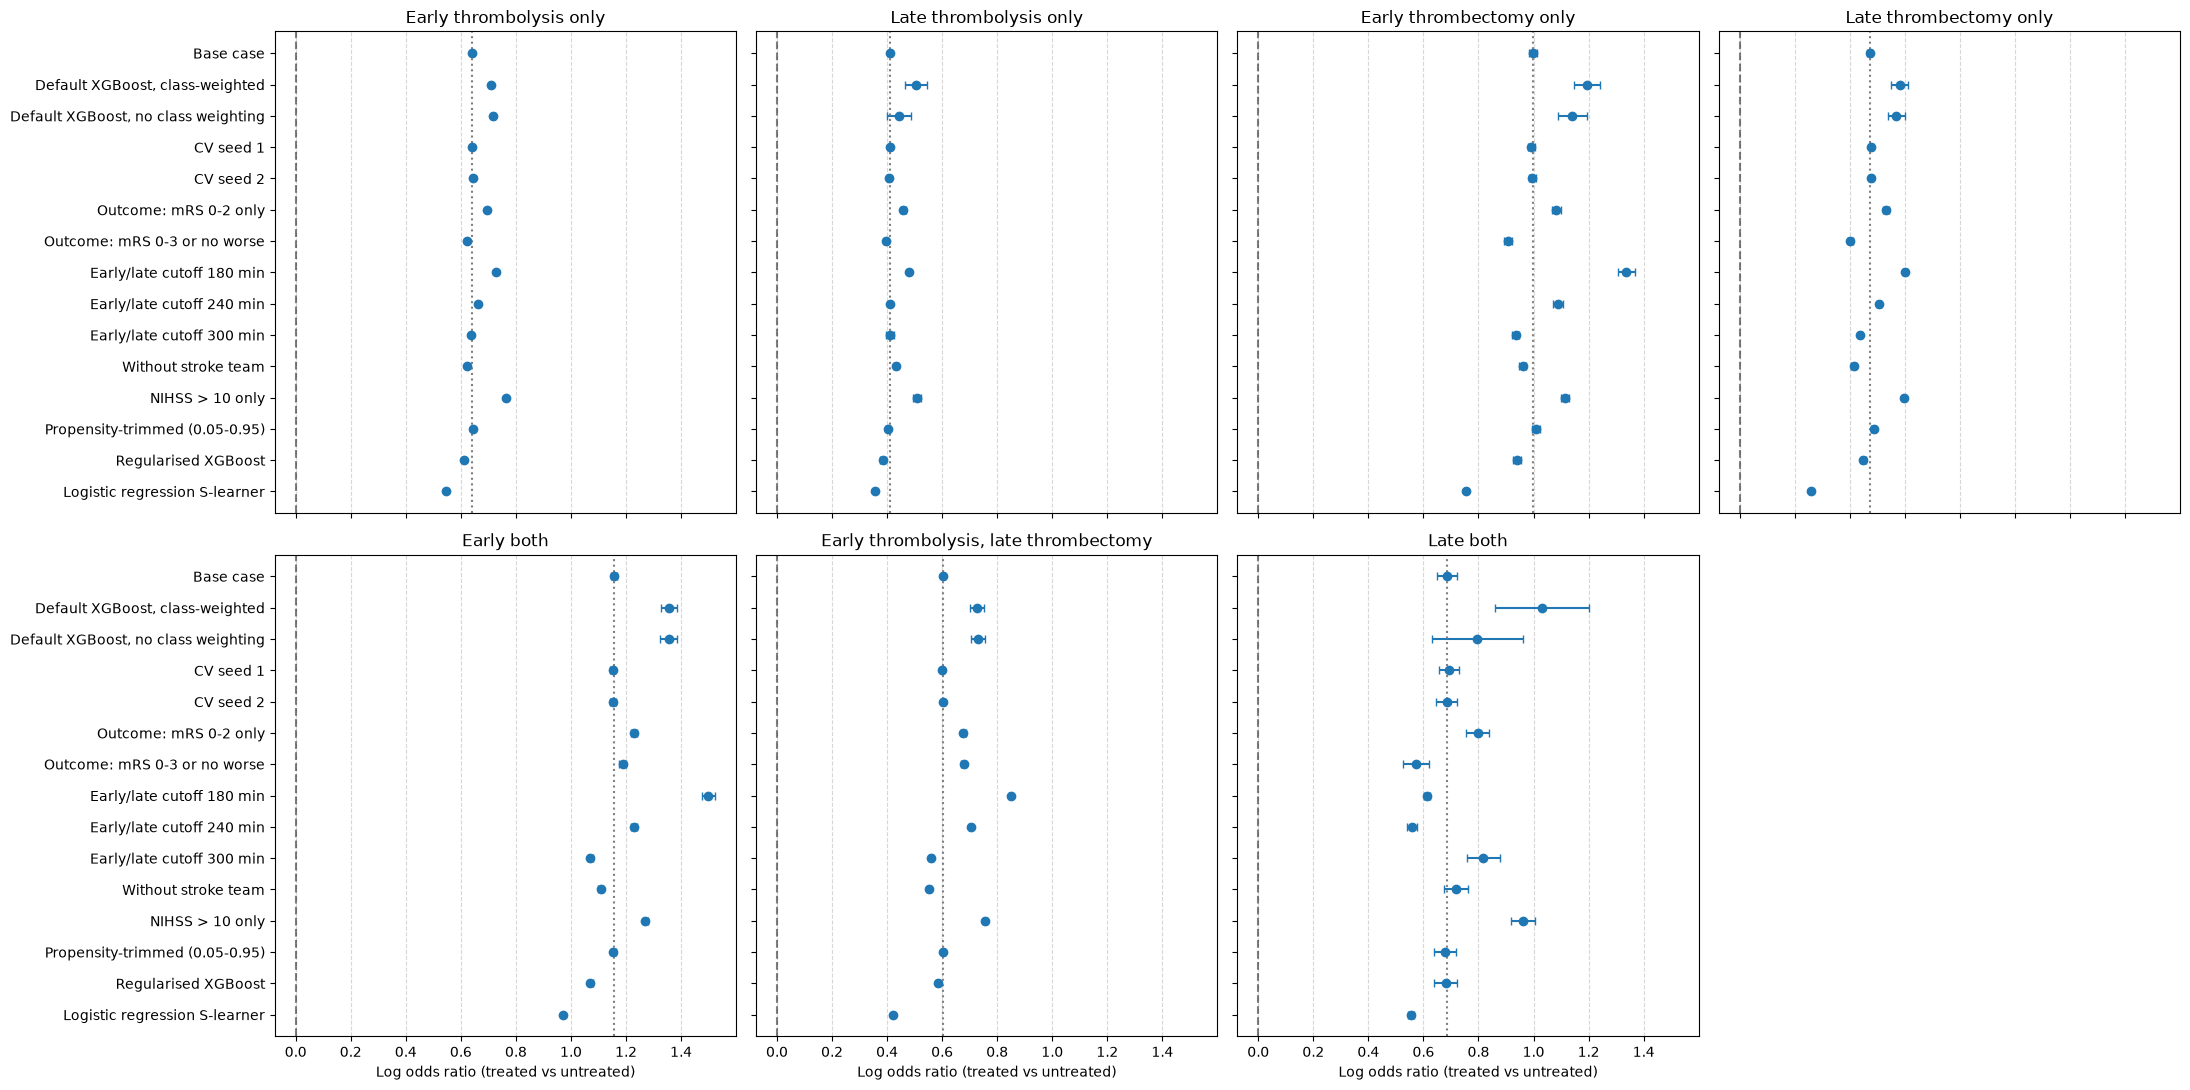

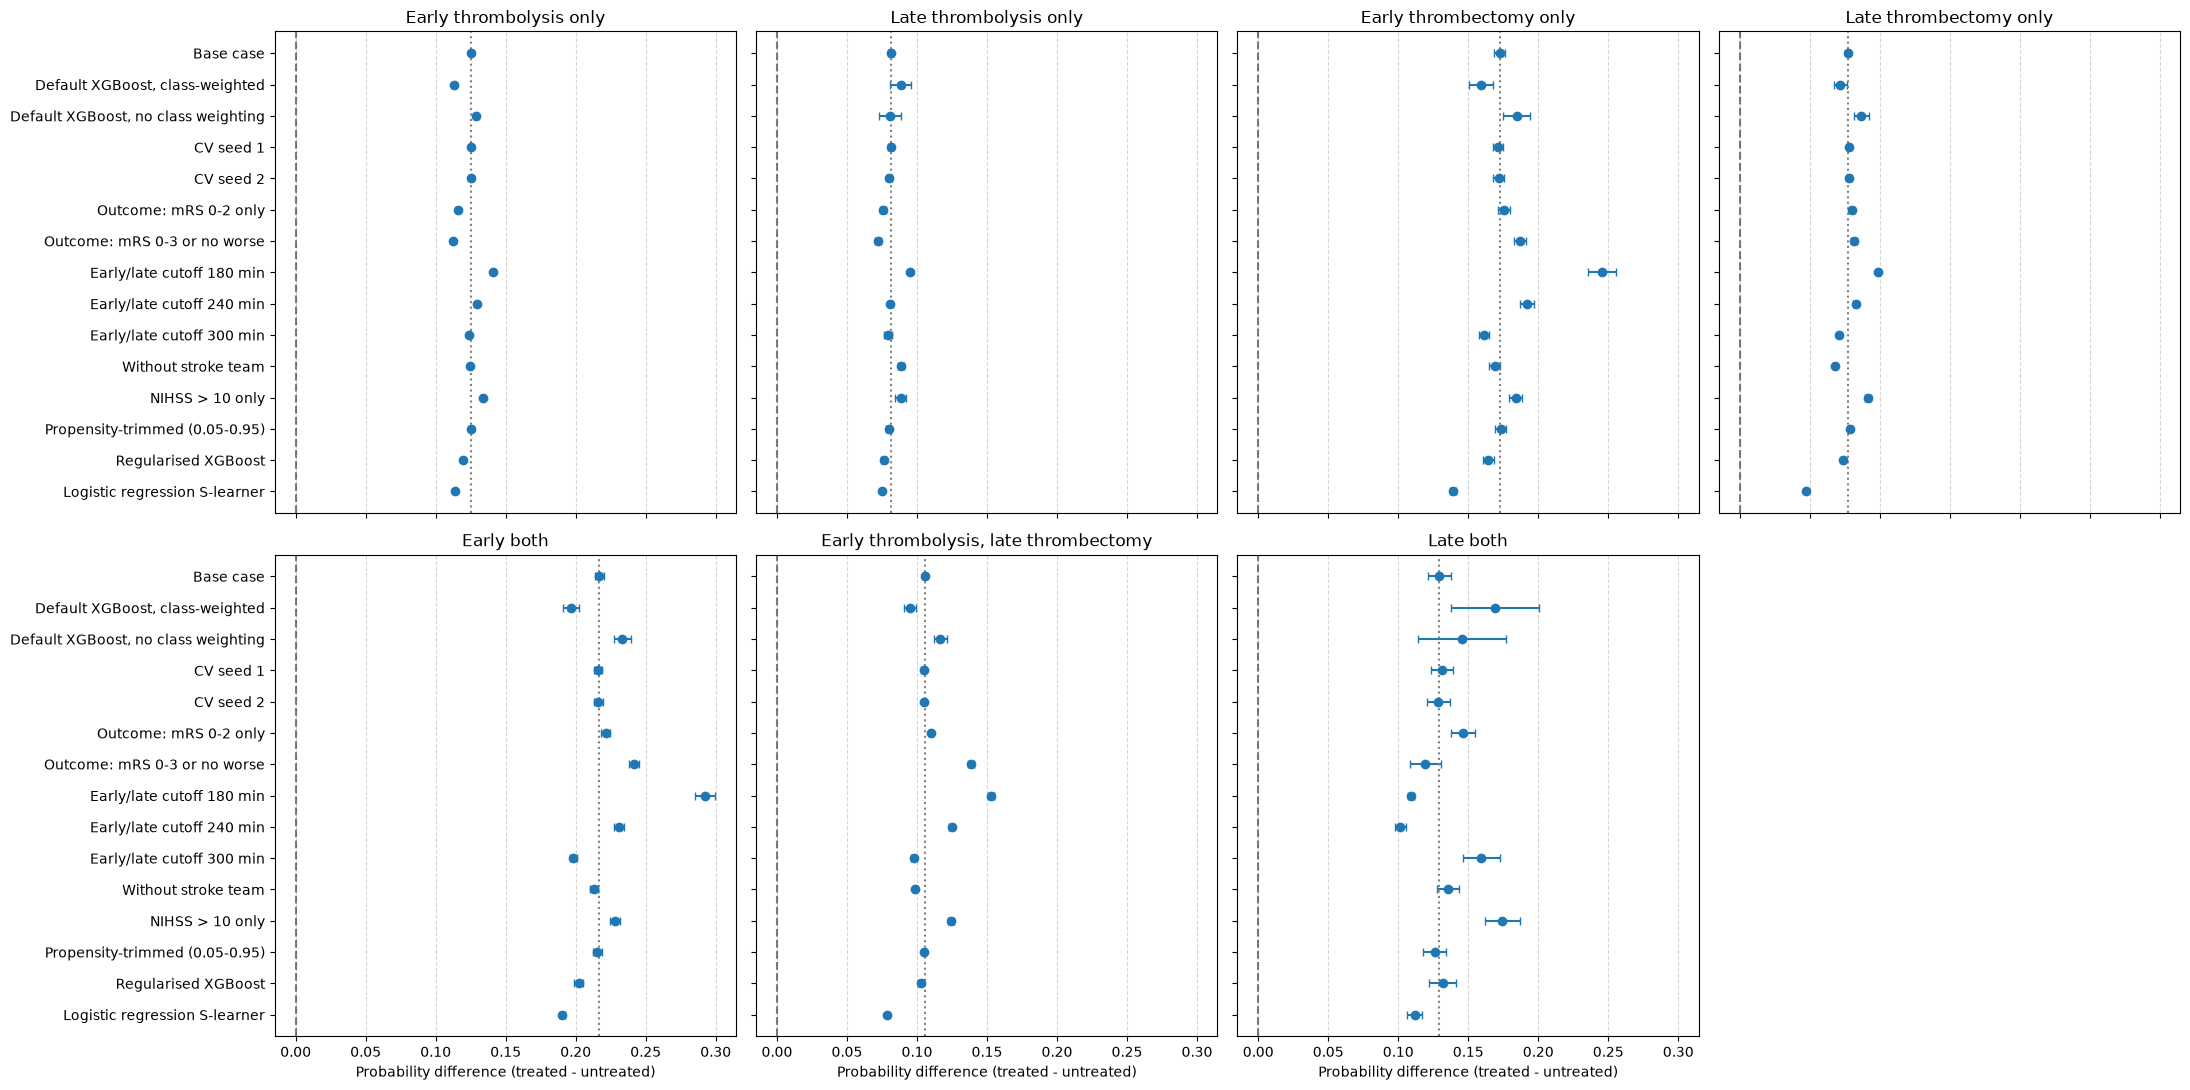

In [40]:
def plot_sensitivity(results, measure, xlabel, filename):
    """One panel per arm: estimate and 95% CI for each scenario; dotted line = base case."""
    res = results[results["measure"] == measure]
    scenarios = list(SCENARIOS)
    y_pos = np.arange(len(scenarios))[::-1]

    fig, axes = plt.subplots(2, 4, figsize=(22, 11), sharex=True, sharey=True)
    for ax, arm in zip(axes.flat, ARM_ORDER):
        arm_res = res[res["treatment_group"] == arm].set_index("scenario").reindex(scenarios)
        ax.errorbar(
            arm_res["mean"], y_pos,
            xerr=[arm_res["mean"] - arm_res["95% CI lower"], arm_res["95% CI upper"] - arm_res["mean"]],
            fmt="o", capsize=3,
        )
        ax.axvline(arm_res.loc["Base case", "mean"], color="grey", linestyle=":")
        ax.axvline(0, color="black", linestyle="--", alpha=0.5)
        ax.set_title(ARM_LABELS[arm].replace("\n", " "))
        ax.grid(axis="x", linestyle="--", alpha=0.5)
    axes[0, 0].set_yticks(y_pos)
    axes[0, 0].set_yticklabels(scenarios)
    for ax in axes[-1, :]:
        ax.set_xlabel(xlabel)
    for ax in axes.flat[len(ARM_ORDER):]:
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(output_path(f"{filename}.png"), dpi=300, bbox_inches="tight")
    plt.show()


plot_sensitivity(sensitivity_results, "log_odds_shift",
                 "Log odds ratio (treated vs untreated)", "sensitivity_log_odds")
plot_sensitivity(sensitivity_results, "prob_shift",
                 "Probability difference (treated - untreated)", "sensitivity_prob")

**Results.** The plots show the same pattern as the tables: most scenarios cluster around the base case, the 180-minute cut-off and NIHSS > 10 scenarios lie to the right, and the logistic regression S-learner lies to the left, most clearly for late thrombectomy only and early thrombolysis with late thrombectomy.

## D3. Unmeasured confounding: E-values

The E-value (VanderWeele and Ding, 2017) is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with *both* treatment and outcome, beyond the measured covariates, to fully explain away the estimate. A second E-value is given for the confidence limit closest to the null (1 if the CI already includes the null).

* Good outcome is common here (about 42%), so odds ratios are converted to approximate risk ratios with the square-root approximation RR ≈ √OR, as recommended for common outcomes.
* The arm "odds ratio" is exp(mean individual log-odds shift) from Part B. This approximates, but is not the same as, a marginal odds ratio.
* The CI used is the between-patient CI from Part B.

In [41]:
def e_value_from_odds_ratio(odds_ratio):
    """E-value for an odds ratio, using RR ~ sqrt(OR) for a common outcome."""
    rr = np.sqrt(np.asarray(odds_ratio, dtype=float))
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))


e_values = np.exp(arm_summary_log_odds[["mean", "95% CI lower", "95% CI upper"]])
e_values.columns = ["OR", "OR 95% CI lower", "OR 95% CI upper"]
e_values["E-value (estimate)"] = e_value_from_odds_ratio(e_values["OR"])

ci_includes_null = (e_values["OR 95% CI lower"] <= 1) & (e_values["OR 95% CI upper"] >= 1)
limit_nearest_null = np.where(e_values["OR"] >= 1, e_values["OR 95% CI lower"], e_values["OR 95% CI upper"])
e_values["E-value (CI limit)"] = np.where(ci_includes_null, 1.0, e_value_from_odds_ratio(limit_nearest_null))

e_values["n"] = arm_summary_log_odds["count"]
e_values.to_csv(output_path("sensitivity_e_values.csv"))
e_values.round(2)

,OR,OR 95% CI lower,OR 95% CI upper,E-value (estimate),E-value (CI limit),n
treatment_group,,,,,,
early_thrombolysis_only,1.90,1.90,1.90,2.10,2.10,27695
late_thrombolysis_only,1.51,1.50,1.52,1.76,1.75,1189
early_thrombectomy_only,2.71,2.68,2.75,2.68,2.66,1107
late_thrombectomy_only,1.60,1.59,1.62,1.85,1.84,1876
early_both,3.18,3.15,3.21,2.96,2.95,2309
early_thrombolysis_late_thrombectomy,1.83,1.82,1.84,2.04,2.03,2714
late_both,1.98,1.91,2.06,2.17,2.11,141


**Results.** Odds ratios range from 1.51 (late thrombolysis only) to 3.18 (early both), and E-values from 1.76 to 2.96:

* early both 2.96; early thrombectomy only 2.68; late both 2.17; early thrombolysis only 2.10; early thrombolysis with late thrombectomy 2.04; late thrombectomy only 1.85; late thrombolysis only 1.76.

The E-values for the confidence limit are almost the same as for the estimate, because the between-patient CIs are narrow. With the wider bootstrap CIs from section 5 (for example late thrombolysis only OR 1.34 to 1.71), the CI E-values would be lower.

**Discussion.** To explain away the early-both or early-thrombectomy effects, an unmeasured confounder would need a risk ratio of about 2.7 to 3 with both treatment and outcome; the late arms need about 1.8 to 2.2. Factors such as frailty or imaging findings could plausibly reach the lower values.

## D4. Unmeasured confounding: sensemakr

Cinelli and Hazlett's omitted variable bias framework describes the strength of an unmeasured confounder by its partial R², the share of the remaining (residual) variance of treatment and of outcome that it explains. It gives:

* **Robustness value RV_q** (q = 1): the minimum partial R² that a confounder would need with *both* treatment and outcome to reduce the estimate to zero.
* **RV_q,alpha**: the same, to make the 95% confidence interval include zero.
* **Partial R² of treatment with outcome**: an extreme-scenario bound. A confounder that explained all the remaining variation in outcome would still need at least this partial R² with treatment to remove the effect.
* **Benchmark bounds**: the adjusted estimate (with 95% CI) if a confounder were 1, 2 or 3 times as strongly associated with treatment and with outcome as an observed covariate.

The framework applies to linear regression, so it cannot be applied to the XGBoost S-learner itself. For each arm, a linear probability model is fitted to the patients in that arm and all untreated patients: good outcome ~ treated + the S-learner's adjustment features + stroke team + ethnicity (as indicator variables). Patients with missing NIHSS are excluded from this model. The linear model is a simpler stand-in for the S-learner: it has no non-linear effects or interactions, and its predictions are not constrained to lie between 0 and 1. Benchmarks are pre-stroke mRS, NIHSS and age.

The first cell implements the formulas of the sensemakr package directly, because the Python package (PySensemakr 0.0.8) is not compatible with pandas 3; the implementation reproduces the package's published Darfur example (estimate, robustness values and benchmark bounds). The second cell fits the models and the third draws the sensitivity contours.

Cinelli C, Hazlett C. Making sense of sensitivity: extending omitted variable bias. *J R Stat Soc Series B* 2020;82:39–67.

In [42]:
from scipy import stats as _stats
import statsmodels.api as _sm


def sensemakr_analysis(model, treatment, benchmarks, kd=(1, 2, 3), q=1.0, alpha=0.05):
    """Cinelli & Hazlett (2020) omitted-variable-bias sensitivity analysis for one OLS coefficient.

    Implements the formulas of the sensemakr package directly (the PySensemakr package is not
    compatible with pandas 3). Returns a one-row DataFrame of sensitivity statistics and a
    DataFrame of bounds: the adjusted estimate if an unobserved confounder were kd times as
    strongly associated with treatment and with outcome as each benchmark covariate.
    """
    est, se, t = model.params[treatment], model.bse[treatment], model.tvalues[treatment]
    dof = model.df_resid
    t_crit = _stats.t.ppf(1 - alpha / 2, dof - 1)

    # Partial R2 of treatment with outcome, and robustness values
    r2yd_x = t**2 / (t**2 + dof)
    f_q = q * abs(t) / np.sqrt(dof)
    rv_q = 0.5 * (np.sqrt(f_q**4 + 4 * f_q**2) - f_q**2)
    f_crit = t_crit / np.sqrt(dof - 1)
    f_qa = f_q - f_crit
    if f_qa < 0:
        rv_qa = 0.0
    elif f_q > 1 / f_crit:  # extreme case (very large t), as in the sensemakr package
        rv_qa = (f_q**2 - f_crit**2) / (1 + f_q**2)
    else:
        rv_qa = 0.5 * (np.sqrt(f_qa**4 + 4 * f_qa**2) - f_qa**2)
    sens_stats = pd.DataFrame([{
        "estimate": est, "se": se, "t": t, "dof": dof, "t_crit": t_crit,
        "r2yd_x": r2yd_x, "rv_q": rv_q, "rv_qa": rv_qa,
    }])

    # Benchmark bounds: partial R2 of each benchmark with treatment (given other covariates)
    # and with outcome (given treatment and other covariates)
    exog = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    treatment_model = _sm.OLS(exog[treatment], exog.drop(columns=treatment)).fit()
    rows = []
    for b in benchmarks:
        t_dx = treatment_model.tvalues[b]
        r2dxj_x = t_dx**2 / (t_dx**2 + treatment_model.df_resid)
        r2yxj_dx = model.tvalues[b]**2 / (model.tvalues[b]**2 + dof)
        for k in kd:
            row = {"benchmark": b, "kd": k}
            if k * r2dxj_x >= 1:
                rows.append(row)
                continue
            r2dz_x = k * r2dxj_x / (1 - r2dxj_x)
            r2zxj_xd = k * r2dxj_x**2 / ((1 - k * r2dxj_x) * (1 - r2dxj_x))
            r2yz_dx = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj_xd)) / np.sqrt(1 - r2zxj_xd))**2
                          * r2yxj_dx / (1 - r2yxj_dx))
            bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
            adj_est = np.sign(est) * (abs(est) - bias)
            adj_se = se * np.sqrt((1 - r2yz_dx) / (1 - r2dz_x) * dof / (dof - 1))
            row.update({"r2dz_x": r2dz_x, "r2yz_dx": r2yz_dx, "adjusted_estimate": adj_est,
                        "adjusted_ci_lower": adj_est - t_crit * adj_se,
                        "adjusted_ci_upper": adj_est + t_crit * adj_se})
            rows.append(row)
    return sens_stats, pd.DataFrame(rows)


def adjusted_estimate_grid(est, se, dof, r2dz_x, r2yz_dx):
    """Adjusted estimate (bias towards zero) over a grid of confounder partial R2 values."""
    bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
    return np.sign(est) * (abs(est) - bias)


BENCHMARK_MARKERS = {"prior_disability": "o", "stroke_severity": "s", "age": "^", "onset_to_scan_time": "D"}
BENCHMARK_NAMES = {"prior_disability": "pre-stroke mRS", "stroke_severity": "NIHSS", "age": "age",
                   "onset_to_scan_time": "onset-to-scan time"}


def plot_sensemakr_contours(sens_stats, sens_bounds, labels, filename, scale=100, unit="percentage points"):
    """One contour plot per treatment strategy: adjusted estimate against the partial R2 of a
    hypothetical confounder with treatment (x) and with outcome (y). The red dashed line is
    where the estimate would fall to zero; markers show confounders 1x, 2x and 3x as strong
    as each benchmark covariate."""
    strategies = list(sens_stats.index)
    ncols = 4
    nrows = int(np.ceil(len(strategies) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.9 * nrows), squeeze=False)
    for ax, strategy in zip(axes.flat, strategies):
        st = sens_stats.loc[strategy]
        b = sens_bounds[(sens_bounds["treatment_group"] == strategy)].dropna(subset=["r2dz_x"])
        lim = max(0.05, 1.2 * max(b["r2dz_x"].max(), b["r2yz_dx"].max(), st["rv_q"]))
        lim = min(lim, 0.95)
        grid = np.linspace(0, lim, 201)
        gx, gy = np.meshgrid(grid, grid)
        z = scale * adjusted_estimate_grid(st["estimate"], st["se"], st["dof"], gx, gy)
        cs = ax.contour(gx, gy, z, levels=8, colors="grey", linewidths=0.7)
        ax.clabel(cs, fontsize=7, fmt="%.0f")
        ax.contour(gx, gy, z, levels=[0], colors="red", linestyles="--", linewidths=1.3)
        for _, r in b.iterrows():
            ax.plot(r["r2dz_x"], r["r2yz_dx"], BENCHMARK_MARKERS.get(r["benchmark"], "x"),
                    color="black", ms=4 + r["kd"])
        ax.plot(0, 0, "*", color="tab:blue", ms=9)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(labels.get(strategy, strategy).replace("\n", " "), fontsize=10)
        ax.set_xlabel("Partial R² of confounder with treatment", fontsize=8)
        ax.set_ylabel("Partial R² of confounder with outcome", fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes.flat[len(strategies):]:
        ax.axis("off")
    handles = [plt.Line2D([], [], color="red", linestyle="--", label="Adjusted estimate = 0"),
               plt.Line2D([], [], marker="*", color="tab:blue", linestyle="", label="Unadjusted estimate")]
    used = sorted(set(sens_bounds["benchmark"]), key=list(BENCHMARK_MARKERS).index)
    handles += [plt.Line2D([], [], marker=BENCHMARK_MARKERS.get(b, "x"), color="black", linestyle="",
                           label=f"1x, 2x, 3x {BENCHMARK_NAMES.get(b, b)}") for b in used]
    fig.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)
    fig.suptitle(f"Sensitivity contours: adjusted effect ({unit})", fontsize=12)
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def format_sensemakr_tables(sens_stats, sens_bounds, labels, scale=100, decimals=1):
    """Publication tables: robustness statistics, and adjusted estimates for each benchmark."""
    fmt = lambda x: f"{scale * x:.{decimals}f}"
    summary = pd.DataFrame({
        "n": sens_stats["n"].astype(int).to_numpy(),
        "estimate (95% CI)": [f"{fmt(r.estimate)} ({fmt(r.estimate - r.t_crit * r.se)}, {fmt(r.estimate + r.t_crit * r.se)})"
                              for r in sens_stats.itertuples()],
        "partial R2 of treatment (%)": (100 * sens_stats["r2yd_x"]).round(2).to_numpy(),
        "RV_q (%)": (100 * sens_stats["rv_q"]).round(1).to_numpy(),
        "RV_q,alpha (%)": (100 * sens_stats["rv_qa"]).round(1).to_numpy(),
    }, index=[labels.get(s, s).replace("\n", " ") for s in sens_stats.index])
    b = sens_bounds.copy()
    b["adjusted (95% CI)"] = [
        "" if pd.isna(r.adjusted_estimate) else
        f"{fmt(r.adjusted_estimate)} ({fmt(r.adjusted_ci_lower)}, {fmt(r.adjusted_ci_upper)})"
        for r in b.itertuples()]
    b["bound"] = b["kd"].astype(str) + "x " + b["benchmark"].map(lambda x: BENCHMARK_NAMES.get(x, x))
    bounds_table = b.pivot(index="treatment_group", columns="bound", values="adjusted (95% CI)")
    bounds_table = bounds_table.reindex(index=list(sens_stats.index),
                                        columns=list(dict.fromkeys(b["bound"])))
    bounds_table.index = [labels.get(s, s).replace("\n", " ") for s in bounds_table.index]
    return summary, bounds_table

In [43]:
# Linear probability model for each arm vs neither, in the whole cohort:
# good outcome ~ treated + adjustment features + stroke team + ethnicity (as indicator variables).
SENS_BENCHMARKS = ["prior_disability", "stroke_severity", "age"]
SENS_ARMS = [g for g in TREATMENT_GROUP_ORDER if g != "neither"]
SENS_LABELS = {g: g.replace("_", " ").capitalize() for g in SENS_ARMS}

y_all = good_outcome(data)
covariates = pd.get_dummies(data[ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES], columns=CATEGORICAL_FEATURES,
                            drop_first=True, dtype=float)

sens_rows, sens_bound_rows = [], []
for arm in SENS_ARMS:
    in_arm = data["treatment_group"].isin([arm, "neither"]).to_numpy()
    df = covariates[in_arm].assign(treated=(data["treatment_group"][in_arm] == arm).astype(float).to_numpy(),
                                   y=y_all[in_arm].to_numpy()).dropna()
    X = df.drop(columns="y")
    X = X.loc[:, X.std() > 0]  # drop indicator columns that are constant in this subset
    lpm = sm.OLS(df["y"], sm.add_constant(X)).fit()
    stats_row, bounds = sensemakr_analysis(lpm, "treated", SENS_BENCHMARKS)
    sens_rows.append(stats_row.assign(treatment_group=arm, n=len(df)))
    sens_bound_rows.append(bounds.assign(treatment_group=arm))

sensemakr_stats = pd.concat(sens_rows).set_index("treatment_group")
sensemakr_bounds = pd.concat(sens_bound_rows, ignore_index=True)
sensemakr_stats.to_csv(output_path("sensemakr.csv"))
sensemakr_bounds.to_csv(output_path("sensemakr_bounds.csv"), index=False)

sensemakr_summary, sensemakr_bounds_table = format_sensemakr_tables(sensemakr_stats, sensemakr_bounds, SENS_LABELS)
display(sensemakr_summary)
display(sensemakr_bounds_table)

,n,estimate (95% CI),partial R2 of treatment (%),RV_q (%),"RV_q,alpha (%)"
Early thrombolysis only,65277,"11.2 (10.4, 12.0)",1.19,10.4,9.7
Late thrombolysis only,38791,"8.9 (6.3, 11.6)",0.11,3.3,2.4
Early thrombectomy only,38709,"15.6 (12.8, 18.4)",0.30,5.4,4.4
Late thrombectomy only,39478,"6.6 (4.4, 8.7)",0.09,3.0,2.0
Early both,39909,"21.1 (19.1, 23.2)",1.01,9.6,8.7
Early thrombolysis late thrombectomy,40316,"10.3 (8.4, 12.1)",0.29,5.2,4.3
Late both,37743,"12.9 (5.5, 20.4)",0.03,1.7,0.7


bound,1x pre-stroke mRS,2x pre-stroke mRS,3x pre-stroke mRS,1x NIHSS,2x NIHSS,3x NIHSS,1x age,2x age,3x age
Early thrombolysis only,"7.8 (7.0, 8.6)","4.2 (3.4, 5.0)","0.4 (-0.4, 1.2)","9.4 (8.7, 10.2)","7.7 (7.0, 8.4)","5.9 (5.2, 6.6)","10.6 (9.8, 11.4)","10.0 (9.2, 10.8)","9.4 (8.7, 10.1)"
Late thrombolysis only,"5.2 (2.7, 7.8)","1.5 (-1.0, 4.1)","-2.2 (-4.7, 0.3)","8.6 (6.1, 11.1)","8.3 (5.9, 10.6)","8.0 (5.7, 10.2)","8.1 (5.5, 10.6)","7.2 (4.6, 9.7)","6.3 (3.8, 8.8)"
Early thrombectomy only,"8.7 (5.9, 11.5)","1.6 (-1.1, 4.4)","-5.5 (-8.3, -2.8)","1.8 (-0.9, 4.5)","-12.2 (-14.8, -9.7)","-26.7 (-29.1, -24.2)","13.3 (10.5, 16.0)","10.9 (8.2, 13.7)","8.6 (5.9, 11.3)"
Late thrombectomy only,"0.0 (-2.1, 2.2)","-6.7 (-8.8, -4.6)","-13.6 (-15.7, -11.5)","-3.2 (-5.3, -1.2)","-13.3 (-15.2, -11.3)","-23.5 (-25.4, -21.7)","4.2 (2.0, 6.3)","1.7 (-0.4, 3.8)","-0.7 (-2.8, 1.4)"
Early both,"12.8 (10.8, 14.9)","4.1 (2.1, 6.2)","-5.0 (-7.1, -2.9)","6.9 (4.9, 8.9)","-8.0 (-9.9, -6.0)","-23.6 (-25.4, -21.8)","18.3 (16.3, 20.4)","15.5 (13.5, 17.5)","12.6 (10.6, 14.6)"
Early thrombolysis late thrombectomy,"2.7 (0.8, 4.5)","-5.3 (-7.2, -3.4)","-13.7 (-15.6, -11.8)","-1.2 (-3.0, 0.6)","-13.2 (-14.9, -11.4)","-25.6 (-27.2, -23.9)","7.5 (5.7, 9.4)","4.7 (2.9, 6.6)","1.9 (0.1, 3.8)"
Late both,"6.2 (-1.1, 13.5)","-0.6 (-7.8, 6.6)","-7.3 (-14.4, -0.3)","4.9 (-2.2, 11.9)","-3.2 (-9.9, 3.5)","-11.3 (-17.5, -5.0)","10.7 (3.4, 18.1)","8.5 (1.3, 15.8)","6.3 (-0.8, 13.5)"


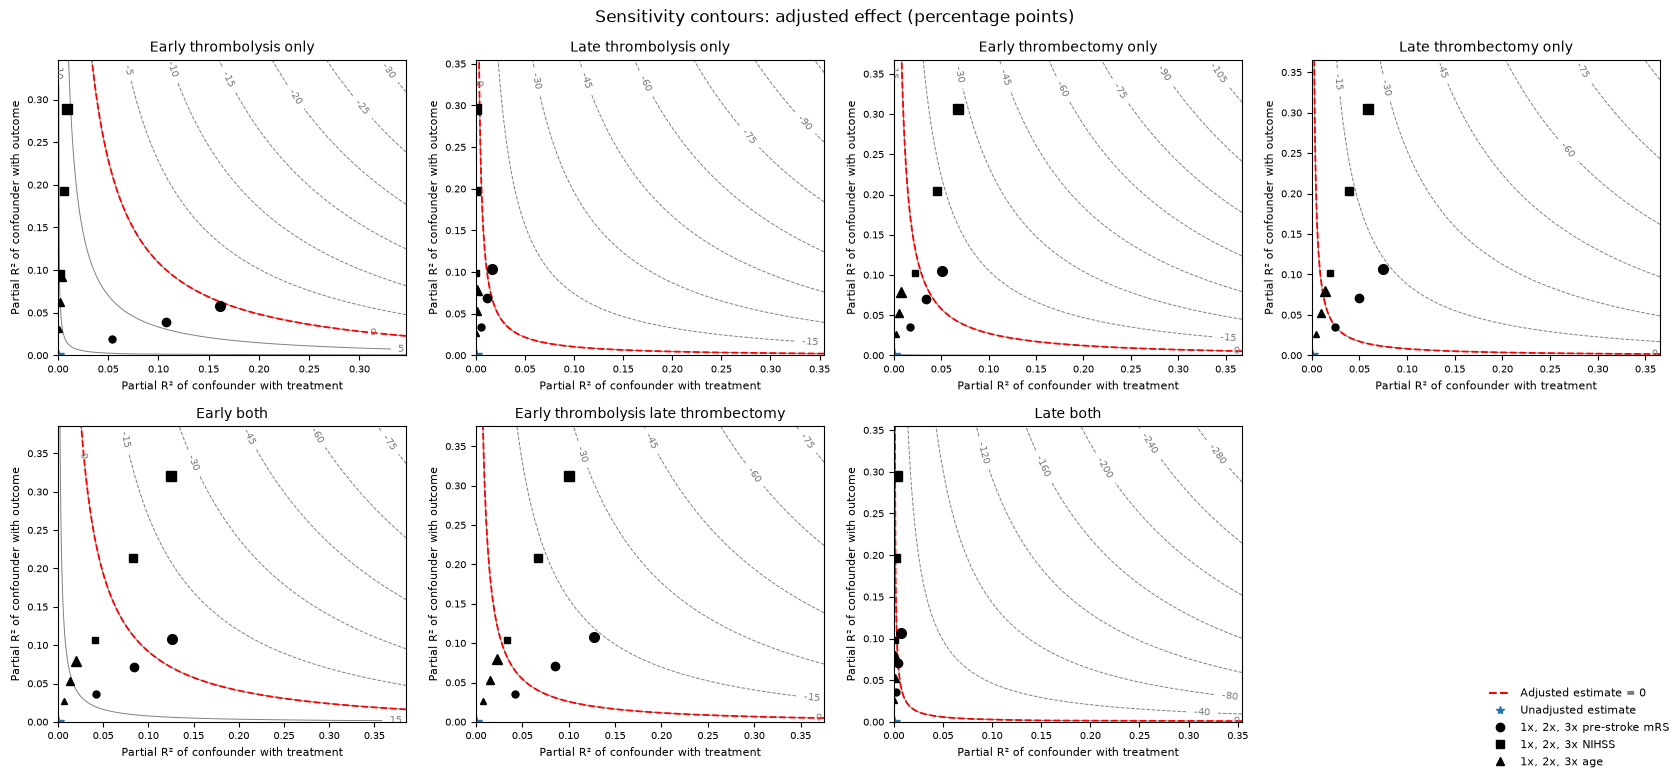

In [44]:
plot_sensemakr_contours(sensemakr_stats, sensemakr_bounds, SENS_LABELS, output_path("sensemakr_contours.png"))

**Results.**

* **The linear model gives effects similar to the S-learner** on the probability scale (for example early both +21.1 vs +21.7 percentage points; early thrombectomy only +15.6 vs +17.2; late both +12.9 vs +12.9), although each arm is compared with all untreated patients rather than through counterfactual predictions.
* **Robustness values are modest.** RV_q ranges from 10.4% (early thrombolysis only) and 9.6% (early both) down to 3.0% (late thrombectomy only) and 1.7% (late both); RV_q,alpha ranges from 0.7% to 9.7%. Most arms are small relative to the untreated group, so treatment explains little of the variance, and a confounder with a modest partial R² could explain away the smaller arms.
* **Benchmarks:**
  * **Age:** a confounder as strong as age, or two or three times as strong, would leave every effect positive except late thrombectomy only (3× age: −0.7 percentage points).
  * **Pre-stroke mRS:** a confounder as strong as pre-stroke mRS would remove the effect of late thrombectomy only (0.0) and most of early thrombolysis with late thrombectomy (2.7), and roughly halve early thrombectomy only (8.7) and early both (12.8). Twice as strong would remove most effects.
  * **NIHSS:** NIHSS is strongly related to receiving thrombectomy, so a confounder as strong as NIHSS would remove most of the thrombectomy effects (early thrombectomy only 1.8, early both 6.9). It is only weakly related to receiving thrombolysis alone, so the thrombolysis-only effects survive even a confounder three times as strong (early 5.9, late 8.0).
* **Contour plot:** each panel shows the adjusted estimate for a hypothetical confounder with the partial R² with treatment (horizontal axis) and with outcome (vertical axis). The red dashed line is where the effect would fall to zero; solid grey lines show smaller positive effects and grey dashed lines negative effects. Far contours are linear extrapolations with no meaning on the probability scale.

**Discussion.** NIHSS and pre-stroke mRS are the strongest measured determinants of both treatment and outcome, and both are already adjusted for. An unmeasured confounder would have to be comparable in strength to these, beyond them, to overturn the thrombectomy results. Imaging findings, LVO status and frailty could plausibly be strong for thrombectomy, so the thrombectomy estimates rest more heavily on the assumption of no unmeasured confounding than the thrombolysis estimates do.

## D5. Leave-one-out analysis of the main confounders

Each of the three strongest measured confounders (NIHSS, age and pre-stroke mRS) is removed from the model features in turn, and the Part B S-learner is refitted with the same tuned hyperparameters and cross-validation folds. Leaving out a measured confounder is a deliberate misspecification: the change in the estimated effect in the treated shows how much each result depends on adjusting for that confounder, and so how much bias an unmeasured confounder of similar strength, acting in the same direction, could cause.

In [45]:
# Leave-one-out sensitivity analysis: remove each main confounder from the S-learner features in turn
LOO_FEATURES = {
    "Without NIHSS": "stroke_severity",
    "Without age": "age",
    "Without pre-stroke mRS": "prior_disability",
}

def arm_rows(summary, analysis):
    """Per-arm mean effect in the treated (probability scale) as rows for the leave-one-out table."""
    rows = summary.rename_axis("treatment_group").reset_index().rename(
        columns={"mean": "estimate", "95% CI lower": "ci_lower", "95% CI upper": "ci_upper", "count": "n"})
    rows["analysis"] = analysis
    return rows[["analysis", "treatment_group", "n", "estimate", "ci_lower", "ci_upper"]]

loo_results = [arm_rows(arm_summary_prob, "Primary")]
loo_auc = {"Primary": performance_arms["AUC"].mean()}
for label, feature in LOO_FEATURES.items():
    cf_loo, performance_loo = run_arm_analysis(data, features=[f for f in X_FIELDS_GROUPS if f != feature])
    loo_results.append(arm_rows(summarise_by_arm(cf_loo, "prob_shift"), label))
    loo_auc[label] = performance_loo["AUC"].mean()
    print(f"Completed: {label}")

loo_df = pd.concat(loo_results, ignore_index=True)
primary_estimate = loo_df[loo_df["analysis"] == "Primary"].set_index("treatment_group")["estimate"]
loo_df["change_pp"] = 100 * (loo_df["estimate"] - loo_df["treatment_group"].map(primary_estimate))
loo_df["estimate_pp"] = 100 * loo_df["estimate"]
loo_df.to_csv(output_path("leave_one_out.csv"), index=False)

loo_columns = ["Primary", *LOO_FEATURES]
for values, title in [("estimate_pp", "Mean effect in the treated, percentage points"),
                      ("change_pp", "Change from the primary estimate, percentage points")]:
    print(title)
    display(loo_df.pivot(index="treatment_group", columns="analysis", values=values)
            .reindex(index=ARM_ORDER, columns=loo_columns).round(1))
print("Mean out-of-fold AUC:", {k: round(v, 3) for k, v in loo_auc.items()})

Completed: Without NIHSS
Completed: Without age
Completed: Without pre-stroke mRS
Mean effect in the treated, percentage points


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
treatment_group,,,,
early_thrombolysis_only,12.500000,10.1,13.1,9.2
late_thrombolysis_only,8.100000,7.2,8.9,5.3
early_thrombectomy_only,17.200001,1.3,18.9,10.9
late_thrombectomy_only,7.800000,-4.4,9.6,2.3
early_both,21.700001,5.1,23.4,16.0
early_thrombolysis_late_thrombectomy,10.600000,-3.2,12.5,5.4
late_both,12.900000,2.6,14.8,8.2


Change from the primary estimate, percentage points


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
treatment_group,,,,
early_thrombolysis_only,0.0,-2.3,0.6,-3.3
late_thrombolysis_only,0.0,-0.9,0.7,-2.9
early_thrombectomy_only,0.0,-16.0,1.7,-6.3
late_thrombectomy_only,0.0,-12.2,1.8,-5.4
early_both,0.0,-16.6,1.7,-5.6
early_thrombolysis_late_thrombectomy,0.0,-13.7,2.0,-5.2
late_both,0.0,-10.4,1.9,-4.7


Mean out-of-fold AUC: {'Primary': np.float64(0.764), 'Without NIHSS': np.float64(0.694), 'Without age': np.float64(0.75), 'Without pre-stroke mRS': np.float64(0.726)}


**Results.**

* **Leaving out age** increases the estimates slightly, by 0.6 to 2.0 percentage points.
* **Leaving out pre-stroke mRS** reduces every estimate, by 2.9 to 6.3 points (for example early both 21.7 → 16.0; late thrombectomy only 7.8 → 2.3).
* **Leaving out NIHSS** changes the thrombolysis-only estimates little (−2.3 and −0.9 points) but reduces every thrombectomy-based estimate by 10.4 to 16.6 points, to between −4.4 and +5.1 (for example early thrombectomy only 17.2 → 1.3; early both 21.7 → 5.1).
* Mean AUC falls from 0.764 to 0.694 without NIHSS, 0.726 without pre-stroke mRS and 0.750 without age.

**Discussion.** Patients selected for thrombectomy have more severe strokes, and so a worse prognosis, than untreated patients. Without NIHSS the model cannot separate the effect of thrombectomy from that of severity, and most of the estimated benefit disappears. This agrees with the sensemakr benchmarks: the thrombectomy results depend heavily on adjustment for stroke severity, and an unmeasured confounder would need to be comparable in strength to NIHSS to remove them.

# 7. Observed outcomes by treatment strategy

Unadjusted number and percentage with a good outcome, in-hospital deaths and length of stay (median, IQR) for the cohort, printed as LaTeX rows for the paper's supplementary table (TARGET items 10 and 12). Counts below 10 are suppressed.

In [46]:
# Observed outcome, in-hospital death and length of stay by treatment strategy,
# printed as LaTeX rows for Supplementary Table "tab:observed_outcomes" (TARGET items 10 and 12).
# Counts below 10 are suppressed, as elsewhere in the paper.

import pandas as pd

LABELS = {
    "neither": "No treatment",
    "early_thrombolysis_only": "Early IVT only",
    "late_thrombolysis_only": "Late IVT only",
    "early_thrombectomy_only": "Early MT only",
    "late_thrombectomy_only": "Late MT only",
    "early_both": "Early IVT + early MT",
    "early_thrombolysis_late_thrombectomy": "Early IVT + late MT",
    "late_both": "Late IVT + late MT",
}


def count_pct(k, n):
    """'k (p%)', or '<10' if the count is below 10."""
    if k < 10:
        return "$<$10"
    return f"{k:,} ({100 * k / n:.1f}\\%)"


def observed_outcome_rows(cohort, outcome_source, group_order):
    """
    cohort: analysed data frame with 'treatment_group', 'discharge_disability'
            and 'prior_disability'.
    outcome_source: data frame holding 'length_of_stay' and 'death' for the same
            patients (same index); for the S-learner this is the cohort itself.
    group_order: treatment groups in the order to print.
    """
    extra = outcome_source.loc[cohort.index, ["length_of_stay", "death"]]
    mrs = cohort["discharge_disability"]
    good = (mrs <= 2) | (mrs <= cohort["prior_disability"])
    table = pd.DataFrame({
        "group": cohort["treatment_group"].astype(str),
        "good": good.astype(int),
        "death": pd.to_numeric(extra["death"], errors="coerce"),
        "los": pd.to_numeric(extra["length_of_stay"], errors="coerce"),
    })
    print(f"% {len(table):,} patients; missing death: {table['death'].isna().sum()}, "
          f"missing length of stay: {table['los'].isna().sum()}")
    for group in group_order:
        rows = table[table["group"] == group]
        n = len(rows)
        if n == 0:
            continue
        good_k = int(rows["good"].sum())
        death_k = int((rows["death"] == 1).sum())
        q1, med, q3 = rows["los"].quantile([0.25, 0.5, 0.75])
        print(f"{LABELS.get(group, group)} & {n:,} & {count_pct(good_k, n)} & "
              f"{count_pct(death_k, n)} & {med:.0f} ({q1:.0f}--{q3:.0f}) \\\\")


# S-learner cohort (all patients): cohort and outcomes are both in data
observed_outcome_rows(data, data, TREATMENT_GROUP_ORDER)


% 74,678 patients; missing death: 0, missing length of stay: 8
No treatment & 37,647 & 14,200 (37.7\%) & 7,495 (19.9\%) & 13 (5--35) \\
Early IVT only & 27,695 & 13,566 (49.0\%) & 3,448 (12.4\%) & 8 (3--29) \\
Late IVT only & 1,189 & 561 (47.2\%) & 145 (12.2\%) & 10 (4--38) \\
Early MT only & 1,107 & 430 (38.8\%) & 178 (16.1\%) & 16 (5--45) \\
Late MT only & 1,876 & 630 (33.6\%) & 299 (15.9\%) & 21 (7--55) \\
Early IVT + early MT & 2,309 & 1,071 (46.4\%) & 246 (10.7\%) & 10 (4--36) \\
Early IVT + late MT & 2,714 & 1,010 (37.2\%) & 317 (11.7\%) & 16 (6--51) \\
Late IVT + late MT & 141 & 62 (44.0\%) & $<$10 & 30 (6--74) \\


**Results.** 37.7% of untreated patients had a good outcome, compared with 49.0% after early thrombolysis only, 47.2% after late thrombolysis only, 38.8% after early thrombectomy only, 33.6% after late thrombectomy only, 46.4% after early both, 37.2% after early thrombolysis with late thrombectomy and 44.0% after late both. In-hospital death was 19.9% in untreated patients and 10.7% to 16.1% in the treated groups. Median length of stay was 13 days (IQR 5 to 35) for untreated patients, 8 days after early thrombolysis only and 10 to 30 days in the thrombectomy groups.

**Discussion.** These are unadjusted comparisons. Thrombectomy patients have more severe strokes, so their raw good-outcome rates are lower than after thrombolysis alone; the adjusted estimates above account for this.

# 8. Conclusions and limitations

### Conclusions

* **Model performance.** The tuned XGBoost S-learner predicts a good outcome at discharge with out-of-fold AUC 0.764 (0.760 to 0.767) and is well calibrated across the range of risk (slope 0.99), so differences in predicted probabilities are a reasonable basis for effect estimates.
* **Effects in the treated.** Every treatment arm is associated with more good outcomes (bootstrap 95% CIs all exclude zero): early thrombolysis only +12.5 percentage points, late thrombolysis only +8.1, early thrombectomy only +17.2, late thrombectomy only +7.8, early both +21.7, early thrombolysis with late thrombectomy +10.6, late both +12.9 (imprecise; 6.4 to 19.5).
* **Time to treatment.** Estimated benefit declines roughly linearly with delay, by about 0.13 to 0.16 log-odds units per hour for each treatment. For thrombolysis alone, predicted benefit falls from about +20 percentage points in the first hour to about +7 at 5 to 6 hours; for thrombectomy alone, from about +25 at 1 to 2 hours to almost nothing at 11 to 12 hours. Combined early treatment gives the largest benefit.
* **Heterogeneity.** Estimated benefit is larger in more severe strokes and smaller in patients aged 82.5 years and over and in those with more pre-stroke disability. Stroke team accounts for a spread of benefit similar to that of age.
* **Robustness.** The estimates are stable across fold allocation, propensity trimming, removal of stroke team and a more regularised model. They change in expected ways with the outcome definition, the early/late cut-off and restriction to NIHSS > 10. A logistic regression S-learner gives smaller effects, especially for thrombectomy.
* **Confounding.** Overlap is adequate. E-values range from 1.76 to 2.96. Thrombolysis-alone effects survive a confounder three times as strong as NIHSS and hardly change when NIHSS is left out; thrombectomy-based effects are largely removed by a confounder as strong as NIHSS or by leaving NIHSS out, so they depend heavily on adjustment for stroke severity.

### Limitations

* **Unmeasured confounding.** The S-learner gives causal effects only if all confounders are measured. Imaging findings, LVO status, frailty and clinicians' judgement of likely benefit are not fully captured, and the thrombectomy estimates are the most vulnerable.
* **Regularisation bias.** An S-learner can shrink treatment effects towards zero when the model gives the treatment feature little weight, especially for small arms such as late both (141 patients).
* **Timing of treatment.** Arms are defined by when treatment was actually given. A patient who died or deteriorated before late treatment is counted as untreated, which can favour the late arms.
* **Uncertainty.** Between-patient CIs understate uncertainty; the bootstrap CIs (30 refits, hyperparameters fixed) are the appropriate ones, but do not include uncertainty from hyperparameter tuning, which used all patients.
* **Extrapolation.** The zero-benefit times from the time regressions extrapolate beyond the data for thrombolysis and should not be read as treatment limits.
* **Outcome at discharge.** mRS at discharge is not the 90-day mRS used in most trials, and depends on length of stay and discharge arrangements.
* **Further analyses not run here** include other meta-learners (T-, X- and doubly robust learners), placebo and negative-control outcome tests, instrumental variable analysis using between-hospital variation in treatment rates, and alternative handling of missing data and selection criteria.